# ADNI CSF SuStaIn Analysis

## Replication and Extension of Emory CSF Subtyping in the ADNI Cohort

This notebook replicates the SuStaIn subtyping analysis from the Emory CSF discovery cohort (N=296) in the ADNI validation cohort (N=595). It covers:

1. Loading and harmonizing Emory and ADNI module eigenprotein data
2. Cross-cohort harmonization using Emory-similar ADNI controls as anchors
3. Control-based z-scoring following the Emory preprocessing pipeline
4. Subtype and stage assignment for all ADNI subjects using pretrained model on Emory CSF dataset
5. Characterization of ADNI subtypes by clinical traits and module eigenproteins
6. Heatmap visualization using one-vs-rest and one-vs-S1 statistical frameworks

**Reference:** Afshar et al. — Subtype and Stage Inference Identifies Five Alzheimer's Disease Subtypes Based on the CSF Proteome


## 1 · Environment Setup

All packages used in this analysis are imported here. `pySuStaIn` implements the z-score SuStaIn algorithm. `sklearn` handles cross-validation, `seaborn` and `matplotlib` handle visualization, and `scipy.stats` provides statistical tests.

In [1]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
import sklearn.model_selection
import pandas as pd
import pylab
import sys
import pySuStaIn
sys.path.insert(0,'/Users/shivaafshar/anaconda3/lib/python3.11/site-packages//sim/')
from simfuncs import generate_random_Zscore_sustain_model, generate_data_Zscore_sustain
import seaborn as sns
from scipy import stats

## 2 · Emory Cohort — Data Loading

The Emory CSF dataset (N=296) is loaded from a multi-sheet `.xlsb` workbook. Two sheets are used:

| Sheet | Contents |
|---|---|
| `MEs(34modules)` | 296 samples × 34 WGCNA module eigengenes |
| `SUSTAIN.numericMeta-Stage+Subty` | Sample-level metadata (Group, APOE, SuStaIn assignments, etc.) |

The `turquoise` module is excluded as it is biologically ambiguous. Module color codes are mapped to interpretable ontology labels. All eigengene values are z-scored across the Emory cohort.

In [2]:
############################### Loading data (Emory)

data = pd.read_excel(
    "FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb", 
    sheet_name="MEs(34modules)", 
    engine='pyxlsb'
)
data.index = data.iloc[:, 0]
data = data.iloc[:, 1:].T
data=data.drop(columns=['turquoise'])
#data=data.drop(columns=['salmon'])
"""
data = pd.read_csv("standardized_net_MEs.csv")
data.index = data.iloc[:, 0]
data = data.iloc[:, 1:]
data=data.drop(columns=['turquoise'])
"""
numeric_meta=pd.read_excel("FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb",sheet_name="SUSTAIN.numericMeta-Stage+Subty",engine='pyxlsb')
numeric_meta.index=numeric_meta.iloc[:,0]
numeric_meta=numeric_meta.iloc[:,1:]

data_normalized = (data - data.mean()) / data.std()
#print(pd.DataFrame(data.mean()))

data_control = data_normalized.loc[
    (numeric_meta["Group"] == "Control") & 
    (numeric_meta["WGCNA-unstandardized-net"].isin(["brown", "red"]))].astype(float)

module_name=data_normalized.columns

np.array(module_name)

color_to_ontologies=pd.read_csv("module_colors.csv")
mapping_dict = dict(zip(color_to_ontologies['Module color'], color_to_ontologies['num-col-ontology']))
#color_to_ontologies=pd.read_csv("Standardized Network Ontologies.csv")
#mapping_dict = dict(zip(color_to_ontologies['Color'], color_to_ontologies['num-col-ontology']))

data= data.rename(columns=mapping_dict)
data_normalized= data_normalized.rename(columns=mapping_dict)
data_control= data_control.rename(columns=mapping_dict)

module_name=data_normalized.columns

np.array(module_name)
data

Unnamed: 0,M33|darkolivegreen|Oxidant detoxification/MAPK signalling,M26|darkorange|Neddylation,M32|violet|L1CAM/ Axon development,M22|darkgreen|Golgi/Glycosylation,M28|skyblue|Neurons system development,M17|grey60|synpatic vesicle/SNAP-SNARE comlex,M4|yellow|Autophagy/Ubiquitination,M19|lightyellow|Ambiguous,M3|brown|Neuron development,M9|magenta|Ambiguous,...,M27|white|Nucleosome,M10|purple|Golgi/Glycosylation,M20|royalblue|Glycolysis/Redox homeostasis,M30|steelblue|Viral endocytosis,M18|lightgreen|Ambiguous,M12|tan|Endocytosis/Ubiquition binding,M21|darkred|ECM/Vasculature,M31|paleturquoise|Actin cytoskeleton,M25|orange|Ambiguous,M29|saddlebrown|Cadherin/Cytoskeleton
43871,0.057007,0.056391,-0.091506,-0.004948,-0.039334,-0.022197,-0.010064,-0.019608,-0.073657,-0.057886,...,0.006930,0.059713,0.040143,-0.049541,0.082702,0.051842,0.090213,0.097072,0.082653,0.093820
54421,0.051236,0.102763,0.031924,0.001372,0.064901,0.002819,-0.026501,-0.012919,0.039442,0.057935,...,0.001265,-0.076639,-0.072161,0.041727,-0.054979,-0.071039,-0.029517,-0.012355,-0.052366,-0.070205
45130,-0.030413,-0.004876,-0.009141,-0.114948,-0.096671,0.074560,0.141211,0.047195,0.075724,0.003180,...,-0.041407,0.010235,0.151969,0.061113,0.004625,0.115005,-0.049652,-0.073862,-0.002367,-0.004943
44782,-0.004410,0.009210,0.042783,-0.027383,0.016107,0.027484,0.005332,0.004485,0.008315,0.015147,...,-0.013188,-0.022589,0.041905,0.096085,0.040269,0.000860,0.112739,0.074764,0.028157,0.008580
52524,0.017244,0.023431,-0.043981,-0.049640,-0.038791,-0.055698,-0.080410,-0.030736,-0.063366,-0.066179,...,0.041883,0.028805,-0.019794,-0.035199,0.011021,-0.031155,-0.004913,0.050712,0.045663,0.048487
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55244,-0.033403,-0.041094,0.022001,-0.001763,-0.022197,-0.029360,-0.049486,0.014901,-0.027409,-0.035731,...,0.064808,0.069993,-0.031079,-0.032041,0.027296,-0.026511,0.002917,-0.029149,-0.051521,0.000576
48615,-0.027389,-0.059417,0.037642,-0.032014,0.013668,0.039689,0.023802,0.022497,0.023296,0.033221,...,0.051314,-0.005994,0.011871,0.052175,0.060231,0.056733,0.056802,0.087926,-0.006064,0.063455
53240,0.065325,-0.019281,0.084550,0.121438,0.057386,-0.028153,-0.028196,0.039933,0.055374,0.046902,...,0.015088,0.025209,-0.068633,-0.114335,-0.092606,-0.057218,-0.094964,-0.089808,-0.114111,-0.084075
51129,-0.017661,0.056240,0.041919,-0.077991,-0.033955,-0.062178,-0.058763,-0.085432,-0.053158,-0.080205,...,0.045157,-0.078514,0.022867,-0.009037,-0.003511,-0.038195,0.008591,0.037509,-0.005219,0.076699


## 3 · ADNI Cohort — Data Loading

Synthetic eigenproteins for the ADNI cohort (N=595) were computed from the top intramodular hub proteins (ranked by kME) identified in the Emory cohort, using harmonized ADNI SomaScan 7k CSF proteomics data. The ADNI eigenprotein matrix uses the same 33 module feature space as Emory, enabling direct cross-cohort comparison. ADNI eigenprotein values are z-scored within the ADNI cohort to match Emory preprocessing.

In [3]:
# Loading data (ADNI)
data_ADNI=pd.read_csv("SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed.csv",index_col=0)
numeric_meta_ADNI=pd.read_csv("ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed.csv",index_col=0)
data_ADNI=data_ADNI.drop(columns=['MEturquoise'])
data_normalized_ADNI = (data_ADNI - data_ADNI.mean()) / data_ADNI.std()
data_ADNI.columns=module_name
data_normalized_ADNI.columns=module_name

## 4 · Combined Cohort — Data Integration and t-SNE Visualization

Emory and ADNI z-scored eigenprotein matrices are concatenated to form a combined dataset (N=891). Clinical group labels (AD/Control) are harmonized: Emory uses pathological diagnosis; ADNI uses CSF pTau/Abeta42 ratio > 0.0191 to define amyloid-positive (AD) status. A t-SNE embedding is computed to assess cohort-level batch effects prior to harmonization.

In [4]:
#ADNI+Emory data
data_all=pd.concat([data_normalized,data_normalized_ADNI])
label_all=["FNIH" for i in range(0,296)]+["ADNI" for i in range(0,595)]
numeric_meta_all=pd.DataFrame()
numeric_meta_all["cohort"]=label_all
index_control=np.where((numeric_meta["Group"] == "Control") & (numeric_meta["WGCNA-unstandardized-net"].isin(["red", "brown"])))[0]
labels                  = np.array(["AD" for i in range(0,296)])
labels[index_control]   = "Control"
labels2=np.array(numeric_meta_ADNI["DX_bl.1"])
numeric_meta_all["Group"]=list(labels)+list(labels2)
len(np.where(labels=="Co")[0])
name=list(numeric_meta.index)+list(numeric_meta_ADNI.index)
numeric_meta_all.index=name

### 4a · t-SNE: Cohort Separation (All Subjects)

Controls (squares) and AD subjects (circles) from each cohort are plotted in t-SNE space to assess whether the two cohorts occupy distinct or overlapping regions of the eigenprotein space.

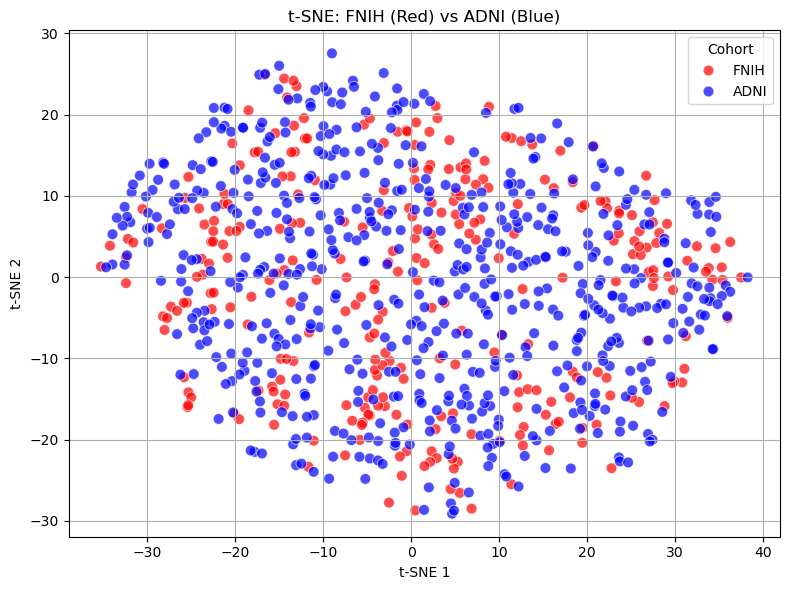

In [5]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import seaborn as sns

# 1. Run t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca")
tsne_results = tsne.fit_transform(data_all)

# 2. Add t-SNE coordinates to metadata
numeric_meta_all["tsne-1"] = tsne_results[:, 0]
numeric_meta_all["tsne-2"] = tsne_results[:, 1]

# 3. Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="tsne-1", y="tsne-2",
    hue="cohort",
    palette={"FNIH": "red", "ADNI": "blue"},
    data=numeric_meta_all,
    alpha=0.7,
    s=60
)
plt.title("t-SNE: FNIH (Red) vs ADNI (Blue)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cohort")
plt.grid(True)
plt.tight_layout()
plt.show()


### 4b · t-SNE: Control Overlap Assessment

Control subjects from Emory and ADNI are highlighted separately. Overlap between cohort control clusters confirms comparable proteomic profiles and validates the use of Emory controls as a harmonization reference.

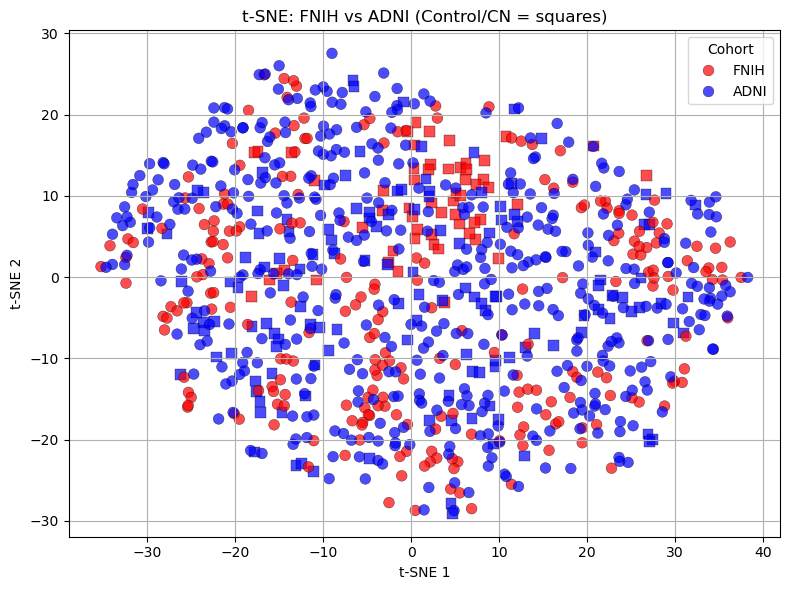

In [6]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import seaborn as sns

# 1. Run t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca")
tsne_results = tsne.fit_transform(data_all)

# 2. Add t-SNE coordinates to metadata
numeric_meta_all["tsne-1"] = tsne_results[:, 0]
numeric_meta_all["tsne-2"] = tsne_results[:, 1]

# 3. Define mask for Control/CN
is_control = numeric_meta_all["Group"].isin(["Co", "CN"])

# 4. Setup plot
plt.figure(figsize=(8, 6))

# Plot Control/CN as squares
sns.scatterplot(
    x="tsne-1", y="tsne-2",
    data=numeric_meta_all[is_control],
    hue="cohort",
    palette={"FNIH": "red", "ADNI": "blue"},
    marker="s",  # square
    s=60,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.3,
    legend=False  # We'll handle legend manually
)

# Plot Others as circles
sns.scatterplot(
    x="tsne-1", y="tsne-2",
    data=numeric_meta_all[~is_control],
    hue="cohort",
    palette={"FNIH": "red", "ADNI": "blue"},
    marker="o",  # circle
    s=60,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.3
)

# Final touches
plt.title("t-SNE: FNIH vs ADNI (Control/CN = squares)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.tight_layout()
plt.legend(title="Cohort")
plt.show()


### 4c · Identifying Most Similar ADNI Controls

To anchor cross-cohort harmonization, the 30 ADNI control subjects whose t-SNE coordinates most closely match the Emory control cluster are identified by pairwise Euclidean distance. These serve as harmonization anchors.

In [7]:
from scipy.spatial.distance import cdist
import numpy as np

# Mask controls in each cohort
fnih_control = numeric_meta_all[(numeric_meta_all["cohort"] == "FNIH") & is_control]
adni_control = numeric_meta_all[(numeric_meta_all["cohort"] == "ADNI") & is_control]

# Compute pairwise distances in t-SNE space
dist_matrix = cdist(adni_control[["tsne-1", "tsne-2"]], fnih_control[["tsne-1", "tsne-2"]])

# For each ADNI control, find the min distance to any FNIH control
min_dist_to_fnih = dist_matrix.min(axis=1)
adni_control["min_dist_to_fnih"] = min_dist_to_fnih

# Sort ADNI controls by similarity to FNIH controls
similar_adni_controls = adni_control.sort_values("min_dist_to_fnih")

/var/folders/63/r5m31vp516x6qwddwfqtw5xh0000gr/T/ipykernel_56786/952201343.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adni_control["min_dist_to_fnih"] = min_dist_to_fnih


### 4d · Annotation of Top 30 ADNI Controls

The 30 most Emory-similar ADNI controls are annotated on the t-SNE plot to confirm they cluster within the Emory control region.

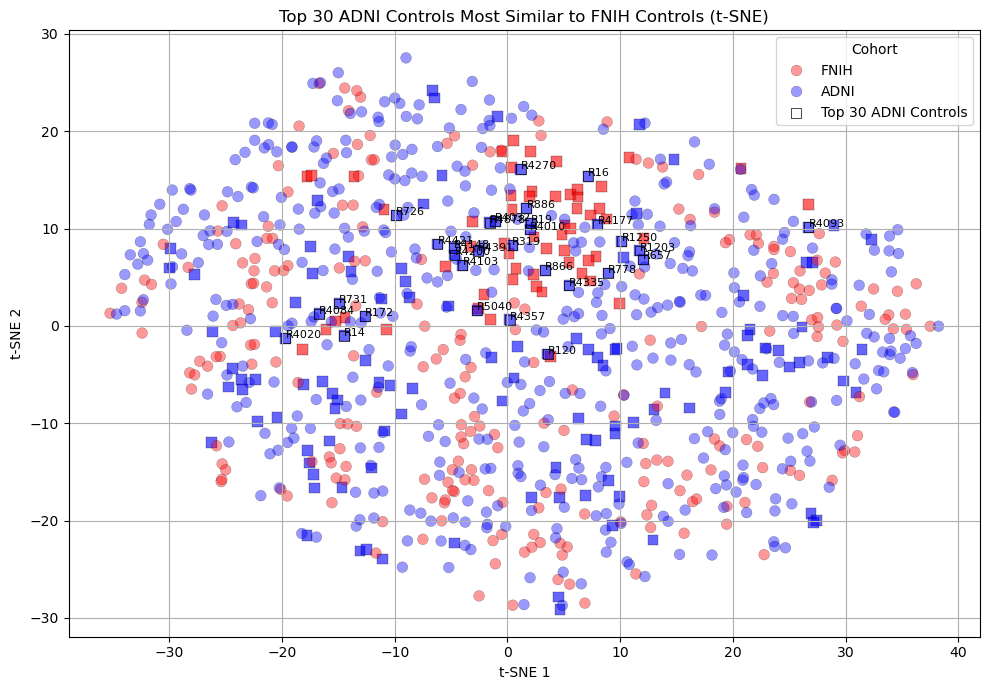

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select top 30 ADNI control samples most similar to FNIH controls
top_30_adni = similar_adni_controls.head(30)

# Create the t-SNE plot
plt.figure(figsize=(10, 7))

# Plot FNIH and ADNI Control/CN as squares
sns.scatterplot(
    x="tsne-1", y="tsne-2",
    data=numeric_meta_all[is_control],
    hue="cohort",
    palette={"FNIH": "red", "ADNI": "blue"},
    marker="s",
    s=60,
    alpha=0.6,
    edgecolor="black",
    linewidth=0.3,
    legend=False
)

# Plot other (non-control) samples as circles
sns.scatterplot(
    x="tsne-1", y="tsne-2",
    data=numeric_meta_all[~is_control],
    hue="cohort",
    palette={"FNIH": "red", "ADNI": "blue"},
    marker="o",
    s=60,
    alpha=0.4,
    edgecolor="black",
    linewidth=0.3
)

# Annotate the top 30 ADNI controls with a black border and text
plt.scatter(
    top_30_adni["tsne-1"], top_30_adni["tsne-2"],
    s=50,
    marker="s",
    facecolors='none',
    edgecolors='black',
    linewidths=0.5,
    label='Top 30 ADNI Controls'
)

# Optional: Label with index or ID
for _, row in top_30_adni.iterrows():
    plt.text(row["tsne-1"], row["tsne-2"], str(row.name), fontsize=8, color='black')

# Final touches
plt.title("Top 30 ADNI Controls Most Similar to FNIH Controls (t-SNE)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.tight_layout()
plt.legend(title="Cohort")
plt.show()


## 5 · Cross-Cohort Harmonization

A control-anchored mean shift correction is applied to remove systematic eigenprotein scale differences between cohorts. For each module, the mean across the 30 ADNI anchor controls is subtracted and the corresponding Emory control mean is added, shifting the ADNI control distribution to match the Emory reference while preserving within-ADNI disease-vs-control differences. Alignment is verified by confirming post-adjustment ADNI anchor control means match Emory control means.

In [9]:
import numpy as np
import pandas as pd

cohort1_common=data_normalized.T #FNIH
cohort2_common=data_normalized_ADNI.T #ADNI
cohort1_labels=labels
cohort2_labels=labels2

# Step 2: Extract control samples
ctrl1 = cohort1_common.loc[:, np.array(cohort1_labels) == "Co"]
ctrl2 = cohort2_common.loc[:, similar_adni_controls.head(30).index]#np.array(cohort2_labels) == "CN"]

# Step 3: Calculate row-wise (protein-wise) mean for controls
mean_ctrl1 = ctrl1.mean(axis=1)
mean_ctrl2 = ctrl2.mean(axis=1)

# Step 4: Calculate adjustment per protein
adjustment = mean_ctrl1 - mean_ctrl2  # difference to add to each protein

# Step 5: Apply the adjustment to all Cohort 2 samples (preserves Ctrl-Disease difference)
cohort2_adjusted = cohort2_common.add(adjustment, axis=0)

# 6. Check if control means are now aligned
new_ctrl2_means = cohort2_adjusted.loc[:,similar_adni_controls.head(30).index].mean(axis=1)
print("Max median difference after alignment:", (mean_ctrl1 - new_ctrl2_means).abs().max())

# 7. Optional: Check if disease-control differences are preserved
old_diff = cohort2_common.loc[:, np.array(cohort2_labels) != "CN"].mean(axis=1) - mean_ctrl2
new_diff = cohort2_adjusted.loc[:, np.array(cohort2_labels) != "CN"].mean(axis=1) - new_ctrl2_means
print("Max change in disease-control difference:", (old_diff - new_diff).abs().max())

# Step 6: Optional CV check
def cv(x): return np.std(x, ddof=1) / np.mean(x)

cv_ctrl1 = ctrl1.apply(cv, axis=1)
cv_ctrl2_before = ctrl2.apply(cv, axis=1)
cv_ctrl2_after = cohort2_adjusted.loc[:, similar_adni_controls.head(30).index].apply(cv, axis=1)

cv_diff_before = (cv_ctrl1 - cv_ctrl2_before).abs().mean()
cv_diff_after = (cv_ctrl1 - cv_ctrl2_after).abs().mean()

print(f"Mean CV difference before adjustment: {cv_diff_before:.4f}")
print(f"Mean CV difference after adjustment: {cv_diff_after:.4f}")


Max median difference after alignment: 3.3306690738754696e-16
Max change in disease-control difference: 3.3306690738754696e-16
Mean CV difference before adjustment: 8.4971
Mean CV difference after adjustment: 0.4285


## 6 · SuStaIn Preprocessing — Control-Based Z-Scoring

Following harmonization, ADNI data are z-scored relative to the 30 anchor controls, matching the Emory preprocessing pipeline. Modules whose cohort-wide mean falls below the control mean are sign-flipped (multiplied by -1), so all biomarkers represent increasing deviations from normal — a requirement of the z-score SuStaIn model. Sanity checks confirm control means are approximately 0 and SDs are approximately 1.

In [18]:
data=cohort2_adjusted.T#
data_control=ctrl1.T
# compute the mean and standard deviation of the control population
mean_control = np.mean(data_control,axis=0)
std_control = np.std(data_control,axis=0)

# z-score the data
data = (data-mean_control)/std_control
#data_96=(data_96-mean_control)/std_control
data_control = (data_control-mean_control)/std_control

# multiply data for decreasing biomarkers by -1
mean_data = np.mean(data,axis=0)
data.iloc[:,np.where(mean_data<np.mean(data_control,axis=0))[0]]=-1*data.iloc[:,np.where(mean_data<np.mean(data_control,axis=0))[0]]
data_control.iloc[:,np.where(mean_data<np.mean(data_control,axis=0))[0]]=-1*data_control.iloc[:,np.where(mean_data<np.mean(data_control,axis=0))[0]]

#mean_data_96 = np.mean(data_96,axis=0)
#data_96.iloc[:,np.where(mean_data_96<np.mean(data_control,axis=0))[0]]=-1*data_96.iloc[:,np.where(mean_data_96<np.mean(data_control,axis=0))[0]]


# Check that the mean of the control population is 0
print('Mean of controls is ',np.mean(data_control,axis=0))
# Check that the standard deviation of the control population is 1
print('Standard deviation of controls is ',np.std(data_control,axis=0))
# Check that the mean of the whole dataset is positive
print('Mean of whole dataset is ',np.mean(data,axis=0))
# Check that the standard deviation of the whole dataset is greater than 1
print('Standard deviation of whole dataset is ',np.std(data,axis=0))
#print('Mean of test dataset is ',np.mean(data_96,axis=0))
# Check that the standard deviation of the whole dataset is greater than 1
#print('Standard deviation of test dataset is ',np.std(data_96,axis=0))
data=np.array(data)
data_control=np.array(data_control)


Mean of controls is  Unnamed: 0
M33|darkolivegreen|Oxidant detoxification/MAPK signalling    8.570143e-17
M26|darkorange|Neddylation                                   6.232831e-17
M32|violet|L1CAM/ Axon development                          -3.116416e-17
M22|darkgreen|Golgi/Glycosylation                            1.636118e-16
M28|skyblue|Neurons system development                      -3.311191e-17
M17|grey60|synpatic vesicle/SNAP-SNARE comlex               -1.129701e-16
M4|yellow|Autophagy/Ubiquitination                          -1.947760e-18
M19|lightyellow|Ambiguous                                    7.011935e-17
M3|brown|Neuron development                                  7.401487e-17
M9|magenta|Ambiguous                                         2.337312e-17
M8|pink|Semaphorin signaling                                -2.415222e-16
M15|midnightblue|Neurexin/Synpatic membrance                -1.558208e-17
M24|darkgrey|Axolemma/Semaphorin complex                     0.000000e+00
M11|gr

## 7 · SuStaIn Model Configuration

The z-score SuStaIn model is configured with the same hyperparameters used in the Emory discovery analysis:

In [19]:
Z_vals=np.array([[1,2,3]]*33) 
Z_max=np.array([5]*33)
SuStaInLabels=module_name
N_startpoints = 5
N_iterations_MCMC = int(1e4)
N_S_max=5
output_folder="/Users/shivaafshar/Library/CloudStorage/OneDrive-EmoryUniversity/Research-Shiva/somascan_new_project/FNIH-CSF-eigen-PC-5-normalized-cleanCT-unstandardized-net-brown-red"
dataset_name="FNIH-CSF-eigen-PC-5-normalized-cleanCT-unstandardized-net-brown-red"
use_parellel_startpoints=False

## 8 · SuStaIn Model Initialization

`ZscoreSustain` is initialized with the harmonized z-scored ADNI data and the configuration above.

In [20]:
# Input the settings for z-score SuStaIn

sustain_input = pySuStaIn.ZscoreSustain(data,
                              Z_vals,
                              Z_max,
                              SuStaInLabels,
                              N_startpoints,
                              N_S_max, 
                              N_iterations_MCMC, 
                              output_folder, 
                              dataset_name, 
                              use_parellel_startpoints)

## 9 · Subtype and Stage Assignment (Cross-Validation)

Using pre-trained model on Emory CSF, each ADNI subject is assigned a most-likely subtype and stage.

In [21]:
N_S_gt=5 # optimal number of subtypes
s = N_S_gt-1

Nfolds                              = 3#len(test_idxs)
for fold in range(Nfolds):
    pickle_filename_fold_s  = sustain_input.output_folder + '/pickle_files/' + sustain_input.dataset_name + '_fold' + str(fold) + '_subtype' + str(s) + '.pickle'
    pickle_filepath         = Path(pickle_filename_fold_s)

    pickle_file             = open(pickle_filename_fold_s, 'rb')

    loaded_variables        = pickle.load(pickle_file)

    samples_sequence        = loaded_variables["samples_sequence"]
    samples_f               = loaded_variables["samples_f"]
    
    pickle_file.close()
    
    if fold == 0:
        samples_sequence_cval    = samples_sequence
        samples_f_cval           = samples_f
    else:
        samples_sequence_cval    = np.concatenate((samples_sequence_cval, samples_sequence), axis=2)
        samples_f_cval           = np.concatenate((samples_f_cval, samples_f), axis=1)
                    
N_samples                       =1000
ml_subtype_cval,             \
prob_ml_subtype_cval,        \
ml_stage_cval,               \
prob_ml_stage_cval,          \
prob_subtype_cval,           \
prob_stage_cval,             \
prob_subtype_stage_cval          = sustain_input.subtype_and_stage_individuals_newData(data,
                                                                                       samples_sequence_cval,
                                                                                       samples_f_cval,
                                                                                       N_samples)


## 10 · Load Full-Dataset Subtype Assignments

Subtype and stage assignments from the full-dataset model fit are loaded for downstream characterization. These are the assignments stored in the ADNI metadata file.

In [22]:
N_S_gt=5 # optimal number of subtypes
s = N_S_gt-1
pickle_filename_s           = output_folder + '/pickle_files/' + dataset_name + '_subtype' + str(s) + '.pickle'
pickle_filepath             = Path(pickle_filename_s)
pickle_file                 = open(pickle_filename_s, 'rb')
loaded_variables            = pickle.load(pickle_file)
ml_subtype                  = loaded_variables["ml_subtype"]
prob_ml_subtype             = loaded_variables["prob_ml_subtype"]
ml_stage                    = loaded_variables["ml_stage"]
prob_ml_stage               = loaded_variables["prob_ml_stage"]
prob_subtype                = loaded_variables["prob_subtype"]
prob_stage                  = loaded_variables["prob_stage"]
prob_subtype_stage          = loaded_variables["prob_subtype_stage"]
pickle_file.close()  

In [23]:
print(set(np.concatenate(ml_stage_cval)))
print(len(np.where(np.concatenate(ml_subtype_cval)==0.0)[0]))
print(len(np.where(np.concatenate(ml_subtype_cval)==1.0)[0]))
print(len(np.where(np.concatenate(ml_subtype_cval)==2.0)[0]))
print(len(np.where(np.concatenate(ml_subtype_cval)==3.0)[0]))
print(len(np.where(np.concatenate(ml_subtype_cval)==4.0)[0]))
print(len(np.where(np.concatenate(ml_subtype_cval)==5.0)[0]))

{0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 37.0, 38.0, 39.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 47.0, 49.0, 50.0, 51.0, 53.0, 60.0}
244
115
154
36
46
0


## 11 · Stage x Subtype x Amyloid Status Boxplot

Amyloid status (CSF pTau/Abeta42 > 0.0191) defines AD vs Control groups. Stage distributions are compared across subtypes with amyloid status as the grouping variable, producing the main subtype-stage characterization figure.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


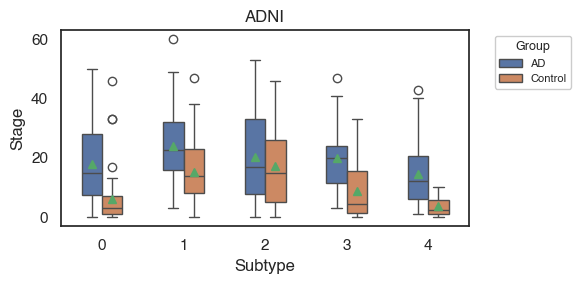

In [34]:
data1 = pd.read_csv("ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv",index_col=0)
data1['Group'] = data1['Amyloid_status'].map({
    'amyloid positive': 'AD',
    'amyloid negative': 'Control'
})

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['text.usetex'] = False
matplotlib.rcParams['svg.fonttype'] = 'none'
matplotlib.rcParams['font.family'] = 'Helvetica'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica']

sns.set_theme(style="white", font="Helvetica")
plt.figure(figsize=(6,3))
sns.boxplot(x=data1["subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI"], 
            y=data1["stage_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI"],
            hue=data1['Group'], 
            width=0.5,
            showmeans=True)
#plt.title('sustain_33_modules')
plt.xlabel('Subtype')
plt.ylabel('Stage')
plt.title("ADNI")
# Adjust legend
plt.legend(bbox_to_anchor=(1.05, 1),  # Position outside plot area
           loc='upper left',           # Anchor point of legend box
           fontsize=8,                 # Smaller font
           frameon=True,               # Show frame
           framealpha=1,             # Frame transparency
           title='Group',              # Legend title
           title_fontsize=9)           # Title font size

plt.tight_layout()  # Automatically adjust to prevent cutoff
plt.savefig("ADNI_SuStaIn_boxplot.pdf", dpi=600)
plt.show()

## 12 · Supplementary Stage-Trait Correlation Plots

Pearson correlations between SuStaIn stage and each clinical trait and module eigenprotein are computed across all subjects and within each subtype. Two multi-page PDFs are generated (all subjects pooled; by subtype). Module eigenproteins are z-scored within each cohort before combining. An Excel workbook of all Pearson r and p-values is also exported.

In [17]:
"""
Supplementary Data: SuStaIn Stage vs Trait Correlations
========================================================
Generates TWO multi-page PDFs:

  *_AllSubjects.pdf  — one panel per trait/EP (all subjects pooled, no subtype split)
  *_BySubtype.pdf    — five panels per trait/EP (one per subtype)

Sections in each PDF:
  1. FNIH cohort continuous traits vs SuStaIn stage
  2. ADNI cohort continuous traits vs SuStaIn stage
  3. Harmonized FNIH+ADNI module eigenproteins vs SuStaIn stage

Layout:
  AllSubjects: 1 panel per page, figsize=(8, 6)
  BySubtype:   1×5 panels per page, figsize=(22, 5)

Color convention: AD = red, Control = blue
Statistics:       Pearson r and p-value (two-sided)
All text editable (pdf.fonttype = 42)
"""

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import pearsonr
from scipy.stats import linregress

warnings.filterwarnings('ignore')

# ── Editable text in PDF ──────────────────────────────────────────────────────
matplotlib.rcParams['pdf.fonttype']    = 42   # TrueType → editable in Illustrator/Acrobat
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['text.usetex']     = False
matplotlib.rcParams['svg.fonttype']    = 'none'
matplotlib.rcParams['font.family']     = 'Helvetica'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

# ── File paths ────────────────────────────────────────────────────────────────
FNIH_XLSB      = "FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb"
ADNI_CSV       = "ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv"
ADNIMERGE_CSV  = "ADNIMERGE_17Jul2025_filtered.csv"
ADNI_T2_CSV    = "1.ADNI_merge-T2-Traits.csv"
SLOPES_CSV     = "3.NumericTraits-SlopesPerYr.csv"
FREESURFER_CSV = os.path.expanduser("~/Downloads/FreeSurfer_595_UCSFFSX7_ventricular_volumes.csv")

# FNIH MEs: xlsb sheet "MEs(34modules)", columns = color names (turquoise excluded)
# ADNI EPs: CSV indexed as R<RID>, columns "M##|color|description"
ADNI_EP_CSV       = "SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv"
MODULE_COLORS_CSV = "module_colors_corrected.csv"

OUTPUT_ALL     = os.path.expanduser("~/Downloads/SupplementaryData_StageCorrelations_AllSubjects.pdf")
OUTPUT_SUBTYPE = os.path.expanduser("~/Downloads/SupplementaryData_StageCorrelations_BySubtype.pdf")
SVG_ROOT_ALL     = os.path.expanduser("~/Downloads/StageCorrelations_SVG_AllSubjects")
SVG_ROOT_SUBTYPE = os.path.expanduser("~/Downloads/StageCorrelations_SVG_BySubtype")

# ── Subtype labels (paper naming convention) ──────────────────────────────────
SUBTYPE_LABELS = {
    1: "S1: Typical",
    2: "S2: Metabolic-sparing",
    3: "S3: Blood-brain barrier",
    4: "S4: ECM/vascular-sparing",
    5: "S5: Neuronal/synaptic-sparing",
}
N_SUBTYPES = 5

AD_COLOR   = 'red'
CTRL_COLOR = 'blue'
AD_ALPHA   = 0.55
CTRL_ALPHA = 0.55
DOT_SIZE   = 18

# ── Race mapping ──────────────────────────────────────────────────────────────
race_mapping = {
    'White': 'White', 'Caucasian': 'White', 'Caucasian or White': 'White',
    'Black or African American': 'Black', 'Black': 'Black',
    'Asian': 'Other', 'American Indian or Alaska Native': 'Other',
    'Native Hawaiian or Other Pacific Islander': 'Other',
    'More than one race': 'Other', 'Unknown': 'Other',
}

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 65)
print("  Loading data ...")
print("=" * 65)

# ── FNIH ──────────────────────────────────────────────────────────────────────
print("\nLoading FNIH xlsb (traits sheet) ...")
data1_fnih = pd.read_excel(
    FNIH_XLSB,
    sheet_name="SUSTAIN.numericMeta-Stage+Subty",
    engine="pyxlsb",
)
data1_fnih.index = data1_fnih.iloc[:, 0]
data1_fnih = data1_fnih.iloc[:, 1:]

FNIH_SUBTYPE_COL = "subtype_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT"
FNIH_STAGE_COL = FNIH_SUBTYPE_COL.replace('subtype_', 'stage_')
print(f"  FNIH stage col: {FNIH_STAGE_COL}")

df_fnih = pd.DataFrame({
    "Subtype":            data1_fnih[FNIH_SUBTYPE_COL] + 1,
    "Stage":              pd.to_numeric(data1_fnih[FNIH_STAGE_COL], errors='coerce'),
    "AD_Status":          data1_fnih["Group"],
    "pTau":               pd.to_numeric(data1_fnih.get("pTau",       np.nan), errors='coerce'),
    "ABETA42":            pd.to_numeric(data1_fnih.get("Abeta",      np.nan), errors='coerce'),
    "APOE4":              pd.to_numeric(data1_fnih.get("APOE4.Dose", np.nan), errors='coerce'),
    "Age":                pd.to_numeric(data1_fnih.get("Age",        np.nan), errors='coerce'),
    "MoCA":               pd.to_numeric(data1_fnih.get("MoCA",       np.nan), errors='coerce'),
})
df_fnih['pTau_ABETA42_ratio'] = df_fnih['pTau'] / df_fnih['ABETA42']
df_fnih['Cohort'] = 'FNIH'
df_fnih = df_fnih[df_fnih['Stage'].notna()].copy()
print(f"  FNIH: {len(df_fnih)} subjects, stage {df_fnih['Stage'].min():.0f}–{df_fnih['Stage'].max():.0f}")

# ── ADNI ──────────────────────────────────────────────────────────────────────
print("\nLoading ADNI csv (traits) ...")
data1_adni = pd.read_csv(ADNI_CSV, index_col=5)

ADNI_SUBTYPE_COL = "subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI"
ADNI_STAGE_COL = ADNI_SUBTYPE_COL.replace('subtype_', 'stage_')
print(f"  ADNI stage col: {ADNI_STAGE_COL}")

adni_merge = pd.read_csv(ADNIMERGE_CSV, index_col=0)
adni_merge = adni_merge.reindex(data1_adni.index)

df_adni = pd.DataFrame({
    "Subtype":            data1_adni[ADNI_SUBTYPE_COL] + 1,
    "Stage":              pd.to_numeric(data1_adni[ADNI_STAGE_COL],         errors='coerce'),
    "AD_Status":          data1_adni['Amyloid_status'].map(
                              {'amyloid negative': 'Control', 'amyloid positive': 'AD'}),
    "pTau":               pd.to_numeric(data1_adni.get("PTAU_bl",      np.nan), errors='coerce'),
    "ABETA42":            pd.to_numeric(data1_adni.get("ABETA42_bl.1", np.nan), errors='coerce'),
    "APOE4":              pd.to_numeric(data1_adni.get("APOE4",        np.nan), errors='coerce'),
    "Age":                pd.to_numeric(data1_adni.get("AGE.1",        np.nan), errors='coerce'),
    "ADAS13":             pd.to_numeric(adni_merge.get("ADAS13_bl",    np.nan), errors='coerce'),
})
df_adni['pTau_ABETA42_ratio'] = df_adni['pTau'] / df_adni['ABETA42']
df_adni['Cohort'] = 'ADNI'

def _ptid_to_rid(ptid):
    try: return int(ptid)
    except (ValueError, TypeError): pass
    try: return int(str(ptid).split('_S_')[1])
    except Exception: return np.nan

df_adni['RID'] = [_ptid_to_rid(p) for p in df_adni.index]
df_adni = df_adni[df_adni['Stage'].notna()].copy()
print(f"  ADNI: {len(df_adni)} subjects, stage {df_adni['Stage'].min():.0f}–{df_adni['Stage'].max():.0f}")

# ── Supplemental ADNI files ───────────────────────────────────────────────────
print("\nLoading supplemental ADNI files ...")
adni_t2_traits = pd.read_csv(ADNI_T2_CSV, index_col=0)
slopes_per_yr  = pd.read_csv(SLOPES_CSV,  index_col=0)

# ── FreeSurfer ICV-normalized volumes ─────────────────────────────────────────
print(f"Loading FreeSurfer data ...")
fs = pd.read_csv(FREESURFER_CSV)
fs['RID'] = pd.to_numeric(fs['RID'], errors='coerce')
fs = fs.dropna(subset=['RID'])
fs['RID'] = fs['RID'].astype(int)
fs = fs.set_index('RID')

RAW_VOL_COLS = [
    'LH_LateralVentricle_mm3', 'RH_LateralVentricle_mm3',
    'TotalLateralVentricle_mm3', 'ChoroidPlexus_mm3',
    'VentChoroid_full_mm3', 'CSF_mm3', 'ICV_mm3',
]
for col in RAW_VOL_COLS:
    if col in fs.columns:
        df_adni[col] = [
            fs.at[int(rid), col]
            if (not pd.isna(rid) and int(rid) in fs.index) else np.nan
            for rid in df_adni['RID']
        ]
        df_adni[col] = pd.to_numeric(df_adni[col], errors='coerce')

for col in [c for c in RAW_VOL_COLS if c != 'ICV_mm3']:
    df_adni[col.replace('_mm3', '_icv_ratio')] = df_adni[col] / df_adni['ICV_mm3']

print(f"  FreeSurfer: {df_adni['VentChoroid_full_icv_ratio'].notna().sum()}/{len(df_adni)} matched")

# ── FNIH MEs from xlsb sheet "MEs(34modules)" ────────────────────────────────
print("\nLoading FNIH MEs from xlsb sheet 'MEs(34modules)' ...")
fnih_me_raw = pd.read_excel(FNIH_XLSB, sheet_name="MEs(34modules)", engine='pyxlsb')
fnih_me_raw.index = fnih_me_raw.iloc[:, 0]
fnih_me_raw = fnih_me_raw.iloc[:, 1:]
fnih_me_cols = [c for c in fnih_me_raw.columns if str(c).strip().lower() != 'turquoise']
print(f"  FNIH: {len(fnih_me_cols)} ME columns (turquoise excluded)")

for col in fnih_me_cols:
    df_fnih[f'ME_{col}'] = (
        pd.to_numeric(fnih_me_raw[col], errors='coerce')
        .reindex(df_fnih.index).values
    )

# ── ADNI synthetic EPs ────────────────────────────────────────────────────────
print(f"Loading ADNI EPs from {ADNI_EP_CSV} ...")
adni_ep = pd.read_csv(ADNI_EP_CSV, index_col=0)
# Index: R<RID> → integer RID
adni_ep.index = adni_ep.index.map(
    lambda x: int(str(x).lstrip('R')) if str(x).lstrip('R').isdigit() else x
)
print(f"  ADNI EP: {adni_ep.shape[0]} subjects, {adni_ep.shape[1]} modules")

# ── Module color → corrected label map ───────────────────────────────────────
print(f"Loading module color labels from {MODULE_COLORS_CSV} ...")
_mc = pd.read_csv(MODULE_COLORS_CSV)
MODULE_COLOR_MAP = {
    str(row["Module color"]).strip().lower(): str(row["num-col-ontology"]).strip()
    for _, row in _mc.iterrows()
}
print(f"  {len(MODULE_COLOR_MAP)} module color entries loaded")

for col in adni_ep.columns:
    df_adni[f'SE_{col}'] = [
        adni_ep.at[int(rid), col]
        if (not pd.isna(rid) and int(rid) in adni_ep.index) else np.nan
        for rid in df_adni['RID']
    ]

# ─────────────────────────────────────────────────────────────────────────────
# PLOT HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _pearson_annot(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    return pearsonr(x[mask], y[mask])

def _fmt_p(p):
    if np.isnan(p): return "n/a"
    if p < 0.001:   return "p < 0.001"
    if p < 0.01:    return f"p = {p:.3f}"
    return f"p = {p:.2f}"

def _regression_line(ax, x, y, color, lw=1.8):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5: return
    slope, intercept, *_ = linregress(x[mask], y[mask])
    xr = np.array([x[mask].min(), x[mask].max()])
    ax.plot(xr, intercept + slope * xr, color=color, lw=lw, alpha=0.85, zorder=4)

def _ad_legend():
    return [
        plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=AD_COLOR,
                   markersize=7, alpha=0.8, label='AD'),
        plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=CTRL_COLOR,
                   markersize=7, alpha=0.8, label='Control'),
    ]

def _style_ax(ax, xlabel="SuStaIn Stage", ylabel="", title=""):
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    if title:
        ax.set_title(title, fontsize=11, fontweight='bold', pad=4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    ax.tick_params(labelsize=9)

def _scatter_groups(ax, sub, y_col, rng, annot_pos=(0.97, 0.97)):
    """Draw scatter + regression + Pearson annotation on one axis."""
    x_all = sub['Stage'].values.astype(float)
    y_all = sub[y_col].values.astype(float)

    for status, color, alpha in [('Control', CTRL_COLOR, CTRL_ALPHA),
                                  ('AD',      AD_COLOR,  AD_ALPHA)]:
        sub_g = sub[sub['AD_Status'] == status]
        if len(sub_g) == 0:
            continue
        xg = sub_g['Stage'].values.astype(float)
        yg = sub_g[y_col].values.astype(float)
        jitter = rng.uniform(-0.15, 0.15, len(xg))
        ax.scatter(xg + jitter, yg, color=color, alpha=alpha,
                   s=DOT_SIZE, zorder=3, linewidths=0)

    # Single fitted line for all subjects (black)
    _regression_line(ax, x_all, y_all, color='black')

    r, p = _pearson_annot(x_all, y_all)
    r_str = f"r = {r:.2f}" if not np.isnan(r) else "r = n/a"
    ax.text(*annot_pos, f"{r_str}\n{_fmt_p(p)}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.85, edgecolor='0.75'))

def _svg_save(fig, svg_dir, label):
    """Save fig as SVG into svg_dir using a sanitized label as filename."""
    if svg_dir is None:
        return
    os.makedirs(svg_dir, exist_ok=True)
    safe = re.sub(r'[^\w\-]', '_', label).strip('_')
    safe = re.sub(r'_+', '_', safe)[:120]
    fig.savefig(os.path.join(svg_dir, f"{safe}.svg"),
                format='svg', bbox_inches='tight')

def _section_page(pdf, title, subtitle=""):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axis('off')
    ax.text(0.5, 0.62, title,    transform=ax.transAxes, ha='center', va='center',
            fontsize=22, fontweight='bold')
    if subtitle:
        ax.text(0.5, 0.38, subtitle, transform=ax.transAxes, ha='center', va='center',
                fontsize=13, color='0.45')
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

# ─────────────────────────────────────────────────────────────────────────────
# PAGE GENERATORS
# ─────────────────────────────────────────────────────────────────────────────

def _build_df(df, trait_col, trait_values=None):
    """Return a clean DataFrame with Stage, Subtype, AD_Status, Trait."""
    if trait_values is not None:
        src = (trait_values.reindex(df.index)
               if hasattr(trait_values, 'reindex')
               else pd.Series(trait_values, index=df.index))
        trait_series = pd.to_numeric(src, errors='coerce')
    else:
        trait_series = pd.to_numeric(df.get(trait_col, np.nan), errors='coerce')

    return pd.DataFrame({
        'Stage':     df['Stage'],
        'Subtype':   df['Subtype'],
        'AD_Status': df.get('AD_Status', pd.Series(np.nan, index=df.index)),
        'Trait':     trait_series,
    }).dropna(subset=['Stage', 'Trait'])


# ── ALL-SUBJECTS version (1 panel per page) ───────────────────────────────────
def page_all(pdf, df, trait_col, trait_label, cohort_label,
             trait_values=None, y_floor=None, axhline=False, svg_dir=None):
    dw = _build_df(df, trait_col, trait_values)
    dw = dw.rename(columns={'Trait': '_y'})

    fig, ax = plt.subplots(figsize=(8, 6))
    fig.suptitle(f"{cohort_label} — SuStaIn Stage vs {trait_label}",
                 fontsize=13, fontweight='bold')

    rng = np.random.default_rng(42)
    if len(dw):
        _scatter_groups(ax, dw.rename(columns={'_y': 'Trait'}), 'Trait', rng)
        if y_floor is not None: ax.set_ylim(bottom=y_floor)
        if axhline: ax.axhline(0, color='grey', lw=0.8, ls='--', alpha=0.6)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', fontsize=12, color='grey')

    _style_ax(ax, ylabel=trait_label)
    ax.legend(handles=_ad_legend(), loc='upper left', fontsize=9, frameon=True)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    _svg_save(fig, svg_dir, f"{cohort_label}_{trait_label}")
    plt.close(fig)
    print(f"  ✓ [all] {cohort_label}: {trait_label}")


# ── BY-SUBTYPE version (1×5 panels per page) ─────────────────────────────────
def page_by_subtype(pdf, df, trait_col, trait_label, cohort_label,
                    trait_values=None, y_floor=None, axhline=False, svg_dir=None):
    dw = _build_df(df, trait_col, trait_values)

    fig, axes = plt.subplots(1, N_SUBTYPES, figsize=(22, 5), sharey=False)
    fig.suptitle(f"{cohort_label} — SuStaIn Stage vs {trait_label}",
                 fontsize=15, fontweight='bold', y=1.01)

    rng = np.random.default_rng(42)
    for ax_idx, st in enumerate(range(1, N_SUBTYPES + 1)):
        ax = axes[ax_idx]
        sub = dw[dw['Subtype'] == st].copy()
        ax.set_title(SUBTYPE_LABELS.get(st, f"S{st}"), fontsize=11, fontweight='bold', pad=4)

        if len(sub):
            _scatter_groups(ax, sub.rename(columns={'Trait': 'Trait'}), 'Trait', rng)
            if y_floor is not None: ax.set_ylim(bottom=y_floor)
            if axhline: ax.axhline(0, color='grey', lw=0.8, ls='--', alpha=0.6)
        else:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                    ha='center', va='center', fontsize=10, color='grey')

        _style_ax(ax, ylabel=trait_label if ax_idx == 0 else "")

    axes[-1].legend(handles=_ad_legend(), loc='upper left', fontsize=8, frameon=True)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    pdf.savefig(fig, bbox_inches='tight')
    _svg_save(fig, svg_dir, f"{cohort_label}_{trait_label}")
    plt.close(fig)
    print(f"  ✓ [subtype] {cohort_label}: {trait_label}")


# ── EP page generators ────────────────────────────────────────────────────────
def _build_ep_df(df_fnih, df_adni, fnih_col, adni_col):
    frames = []
    if fnih_col and fnih_col in df_fnih.columns:
        df_f = pd.DataFrame({
            'Stage':     df_fnih['Stage'],
            'Subtype':   df_fnih['Subtype'],
            'AD_Status': df_fnih['AD_Status'],
            'Trait':     pd.to_numeric(df_fnih[fnih_col], errors='coerce'),
        }).dropna(subset=['Stage', 'Trait'])
        frames.append(df_f)
    if adni_col and adni_col in df_adni.columns:
        df_a = pd.DataFrame({
            'Stage':     df_adni['Stage'],
            'Subtype':   df_adni['Subtype'],
            'AD_Status': df_adni['AD_Status'],
            'Trait':     pd.to_numeric(df_adni[adni_col], errors='coerce'),
        }).dropna(subset=['Stage', 'Trait'])
        frames.append(df_a)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def ep_page_all(pdf, df_fnih, df_adni, fnih_col, adni_col, module_label, svg_dir=None):
    dw = _build_ep_df(df_fnih, df_adni, fnih_col, adni_col)
    if len(dw) == 0:
        print(f"  ⚠ [all] EP {module_label}: no data")
        return

    fig, ax = plt.subplots(figsize=(8, 6))
    fig.suptitle(f"Emory+ADNI — SuStaIn Stage vs {module_label} Eigenprotein (z-scored)",
                 fontsize=12, fontweight='bold')

    rng = np.random.default_rng(42)
    _scatter_groups(ax, dw, 'Trait', rng)
    _style_ax(ax, ylabel=f"{module_label}\nEigenprotein (z-score)")
    ax.legend(handles=_ad_legend(), loc='upper left', fontsize=9, frameon=True)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    _svg_save(fig, svg_dir, f"EP_{module_label}")
    plt.close(fig)
    print(f"  ✓ [all] EP: {module_label}")


def ep_page_by_subtype(pdf, df_fnih, df_adni, fnih_col, adni_col, module_label, svg_dir=None):
    dw = _build_ep_df(df_fnih, df_adni, fnih_col, adni_col)
    if len(dw) == 0:
        print(f"  ⚠ [subtype] EP {module_label}: no data")
        return

    fig, axes = plt.subplots(1, N_SUBTYPES, figsize=(22, 5), sharey=False)
    fig.suptitle(f"Emory+ADNI — SuStaIn Stage vs {module_label} Eigenprotein (z-scored)",
                 fontsize=14, fontweight='bold', y=1.01)

    rng = np.random.default_rng(42)
    for ax_idx, st in enumerate(range(1, N_SUBTYPES + 1)):
        ax = axes[ax_idx]
        sub = dw[dw['Subtype'] == st].copy()
        ax.set_title(SUBTYPE_LABELS.get(st, f"S{st}"), fontsize=11, fontweight='bold', pad=4)

        if len(sub):
            _scatter_groups(ax, sub, 'Trait', rng)
        else:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                    ha='center', va='center', fontsize=10, color='grey')

        _style_ax(ax, ylabel=f"{module_label}\nEigenprotein (z-score)" if ax_idx == 0 else "")

    axes[-1].legend(handles=_ad_legend(), loc='upper left', fontsize=8, frameon=True)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    pdf.savefig(fig, bbox_inches='tight')
    _svg_save(fig, svg_dir, f"EP_{module_label}")
    plt.close(fig)
    print(f"  ✓ [subtype] EP: {module_label}")


# ─────────────────────────────────────────────────────────────────────────────
# MODULE LIST (sorted by module number, matched between FNIH and ADNI)
# ─────────────────────────────────────────────────────────────────────────────
def _parse_num(label):
    m = re.match(r'M(\d+)', str(label).strip())
    return int(m.group(1)) if m else 9999

def _parse_color(label):
    parts = str(label).strip().split('|')
    return parts[1].strip().lower() if len(parts) >= 2 else label.strip().lower()

def _strip_color_from_label(label):
    """'M##|color|ontology' → 'M## ontology'; 'M##|ontology' → 'M## ontology'."""
    parts = [p.strip() for p in str(label).split('|')]
    if len(parts) == 3:
        return f"{parts[0]} {parts[2]}"
    if len(parts) == 2:
        return f"{parts[0]} {parts[1]}"
    return label

adni_ep_cols_sorted = sorted(adni_ep.columns, key=_parse_num)

def _ep_keys(adni_col):
    """Return (fnih_key, adni_key, module_label)."""
    color    = _parse_color(adni_col)
    adni_key = f'SE_{adni_col}'
    # Corrected label from modules_color_corrected.csv; strip color segment
    label = MODULE_COLOR_MAP.get(color)
    if label:
        label = _strip_color_from_label(label)
    else:
        num   = _parse_num(adni_col)
        parts = adni_col.strip().split('|')
        desc  = parts[2].strip() if len(parts) >= 3 else ''
        label = f"M{num} {desc}" if desc else f"M{num}"
    # Match FNIH ME column by color
    fnih_key = None
    for fc in fnih_me_cols:
        if str(fc).strip().lower() == color:
            fnih_key = f'ME_{fc}'
            break
    return fnih_key, adni_key, label


# ─────────────────────────────────────────────────────────────────────────────
# GENERATE BOTH PDFs
# ─────────────────────────────────────────────────────────────────────────────

# Shared helper: ADNI supplemental sources
def _adni_src(col):
    return adni_t2_traits.get(col, pd.Series(np.nan, index=df_adni.index))
def _merge_src(col):
    return adni_merge.get(col, pd.Series(np.nan, index=df_adni.index))
def _slope_src(col):
    return slopes_per_yr.get(col, pd.Series(np.nan, index=df_adni.index))

FS_TRAIT_MAP = {
    'TotalLateralVentricle_icv_ratio': 'Total Lateral Ventricle / ICV',
    'ChoroidPlexus_icv_ratio':         'Choroid Plexus / ICV',
    'VentChoroid_full_icv_ratio':      'Ventricle + Choroid / ICV',
}

for output_path, page_fn_trait, page_fn_ep, svg_root in [
    (OUTPUT_ALL,     page_all,        ep_page_all,        SVG_ROOT_ALL),
    (OUTPUT_SUBTYPE, page_by_subtype, ep_page_by_subtype, SVG_ROOT_SUBTYPE),
]:
    mode = "AllSubjects" if "AllSubjects" in output_path else "BySubtype"
    svg_fnih = os.path.join(svg_root, "FNIH")
    svg_adni = os.path.join(svg_root, "ADNI")
    svg_ep   = os.path.join(svg_root, "EP")
    print(f"\n{'='*65}")
    print(f"  Generating PDF [{mode}] → {output_path}")
    print(f"  SVGs → {svg_root}/{{FNIH,ADNI,EP}}/")
    print(f"{'='*65}")

    with PdfPages(output_path) as pdf:

        # Cover
        _section_page(pdf,
            "Supplementary Data",
            "SuStaIn Stage Correlations with Traits and Module Eigenproteins"
            + (f"\n({'All subjects pooled'  if mode=='AllSubjects' else 'Split by subtype'})"),
        )

        # ── SECTION 1: Emory traits ──────────────────────────────────────────
        print(f"\n[Emory continuous traits]")
        _section_page(pdf, "Section 1",
                      "Emory Cohort (N=296) — Stage vs Continuous Traits")

        page_fn_trait(pdf, df_fnih, 'pTau',               'pTau181 (pg/mL)',        'Emory', svg_dir=svg_fnih)
        page_fn_trait(pdf, df_fnih, 'ABETA42',            'Aβ42 (pg/mL)',           'Emory', svg_dir=svg_fnih)
        page_fn_trait(pdf, df_fnih, 'pTau_ABETA42_ratio', 'pTau181 / Aβ42 ratio',  'Emory', svg_dir=svg_fnih)
        page_fn_trait(pdf, df_fnih, 'Age',                'Age (years)',             'Emory', svg_dir=svg_fnih)
        page_fn_trait(pdf, df_fnih, 'MoCA',               'MoCA',                   'Emory', svg_dir=svg_fnih)

        # ── SECTION 2: ADNI traits ────────────────────────────────────────────
        print(f"\n[ADNI continuous traits]")
        _section_page(pdf, "Section 2",
                      "ADNI Cohort (N=595) — Stage vs Continuous Traits")

        page_fn_trait(pdf, df_adni, 'pTau',               'pTau181 (pg/mL)',        'ADNI', svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'ABETA42',            'Aβ42 (pg/mL)',           'ADNI', svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'pTau_ABETA42_ratio', 'pTau181 / Aβ42 ratio',  'ADNI', svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'Age',                'Age (years)',          'ADNI', svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'ADAS13',             'ADAS13',              'ADNI', y_floor=0, svg_dir=svg_adni)

        page_fn_trait(pdf, df_adni, 'tTau',       'tTau (pg/mL)',             'ADNI',
                      trait_values=_merge_src("TAU"),       y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'AV45',       'AV45 SUVR',               'ADNI',
                      trait_values=_merge_src("AV45"),      y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'Plasma_NfL', 'Plasma NfL (pg/mL)',      'ADNI',
                      trait_values=_adni_src("PLASMA_NFL|6"), y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'PHS',        'AD Polygenic Hazard Score', 'ADNI',
                      trait_values=_adni_src("PHS|31"), svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'Hippocampus','Hippocampal Volume (mm³)', 'ADNI',
                      trait_values=_merge_src("Hippocampus_bl"), y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'Entorhinal', 'Entorhinal Volume (mm³)', 'ADNI',
                      trait_values=_merge_src("Entorhinal_bl"), y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'WMH',        'Total WMH Volume (mm³)',  'ADNI',
                      trait_values=_adni_src("TOTAL_WMH|10"), y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'MMSE',       'MMSE',                    'ADNI',
                      trait_values=_adni_src("MMSCORE|37"),   y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'MMSE_slope', 'MMSE Slope (pts/year)',   'ADNI',
                      trait_values=_slope_src("MMSCORE|37.slope"), axhline=True, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'CDRSB',      'CDRSB',                   'ADNI',
                      trait_values=_adni_src("CDRSB|29"),     y_floor=0, svg_dir=svg_adni)
        page_fn_trait(pdf, df_adni, 'CDRSB_slope','CDRSB Slope (pts/year)',  'ADNI',
                      trait_values=_slope_src("CDRSB|29.slope"), axhline=True, svg_dir=svg_adni)

        for col, label in FS_TRAIT_MAP.items():
            page_fn_trait(pdf, df_adni, col, label, 'ADNI', y_floor=0, svg_dir=svg_adni)

        # ── SECTION 3: Module EPs ─────────────────────────────────────────────
        print(f"\n[Module Eigenprotein correlations]")
        _section_page(pdf, "Section 3",
                      "Harmonized Emory+ADNI — Stage vs Module Eigenproteins (z-scored)")

        for adni_col in adni_ep_cols_sorted:
            fnih_key, adni_key, label = _ep_keys(adni_col)
            page_fn_ep(pdf, df_fnih, df_adni, fnih_key, adni_key, label, svg_dir=svg_ep)

        # PDF metadata
        info = pdf.infodict()
        info['Title']  = f'Supplementary Data: Stage Correlations ({mode})'
        info['Author'] = 'Johnson Lab'

    print(f"\n  ✓ Saved: {output_path}")

print(f"\n{'='*65}")
print("  Done. Both PDFs saved to ~/Downloads/")
print("=" * 65)

# ─────────────────────────────────────────────────────────────────────────────
# CORRELATION TABLES → Excel
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'='*65}")
print("  Building correlation tables ...")
print(f"{'='*65}")

from openpyxl import Workbook as _XWB
from openpyxl.styles import (Font as _XFont, PatternFill as _XFill,
                              Alignment as _XAlign)
from openpyxl.utils import get_column_letter as _gcl

OUTPUT_TABLES = os.path.expanduser("~/Downloads/StageCorrelation_Tables.xlsx")

_FILL_TITLE  = _XFill(fill_type="solid", fgColor="D9E1F2")
_FILL_HEADER = _XFill(fill_type="solid", fgColor="BDD7EE")
_FILL_SIG    = _XFill(fill_type="solid", fgColor="FCE4D6")   # sig p < 0.05

_ST_SHORT = {
    1: "S1 Typical",
    2: "S2 Metabolic-sp.",
    3: "S3 BBB",
    4: "S4 ECM/vasc.",
    5: "S5 Neuronal/syn.",
}

def _xf(bold=False, size=10, color="000000"):
    return _XFont(name="Arial", size=size, bold=bold, color=color)

def _xc():
    return _XAlign(horizontal="center", vertical="center", wrap_text=True)

def _xl():
    return _XAlign(horizontal="left", vertical="center", wrap_text=False)

def _r_p(x_arr, y_arr):
    """Pearson (N, r, p) for finite pairs; returns NaN if N < 5."""
    x = np.asarray(x_arr, dtype=float)
    y = np.asarray(y_arr, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    n = int(mask.sum())
    if n < 5:
        return n, np.nan, np.nan
    r_val, p_val = pearsonr(x[mask], y[mask])
    return n, float(r_val), float(p_val)

def _p_str(p):
    if np.isnan(p): return "n/a"
    if p < 0.001:   return "<0.001"
    return f"{p:.3f}"

def _write_sheet(wb, sname, title, rows):
    """
    rows: list of (label, stage_arr, trait_arr, subtype_arr)
          All arrays numpy-array-like, same length, already finite-filtered
          is not required — NaNs handled internally.
    """
    ws = wb.create_sheet(sname)
    NCOLS = 19   # 1 label + 3*(1 all + 5 subtypes)

    # Row 1: merged title
    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=NCOLS)
    c = ws.cell(row=1, column=1, value=title)
    c.font      = _xf(bold=True, size=11)
    c.fill      = _FILL_TITLE
    c.alignment = _XAlign(horizontal="left", vertical="center", wrap_text=True)
    ws.row_dimensions[1].height = 36.0

    # Row 2: blank spacer
    ws.row_dimensions[2].height = 6.0

    # Row 3: column headers
    hdrs = ["Trait / Module",
            "N\n(all)", "r\n(all)", "p\n(all)"]
    for st in range(1, 6):
        lbl = _ST_SHORT[st]
        hdrs += [f"{lbl}\nN", f"{lbl}\nr", f"{lbl}\np"]

    for ci, h in enumerate(hdrs, start=1):
        c = ws.cell(row=3, column=ci, value=h)
        c.font      = _xf(bold=True, size=9)
        c.fill      = _FILL_HEADER
        c.alignment = _xc()
    ws.row_dimensions[3].height = 56.0
    ws.freeze_panes = "A4"

    # Rows 4+: data
    for ri, (label, stage_arr, trait_arr, sub_arr) in enumerate(rows, start=4):
        ws.row_dimensions[ri].height = 15.0

        # Col A: trait/module label
        c = ws.cell(row=ri, column=1, value=label)
        c.font      = _xf(size=10)
        c.alignment = _xl()

        col = 2
        # All subjects
        n, r, p = _r_p(stage_arr, trait_arr)
        for vi, val in enumerate([n or "–",
                                   round(r, 3) if not np.isnan(r) else "n/a",
                                   _p_str(p)]):
            c = ws.cell(row=ri, column=col, value=val)
            c.font      = _xf(size=10)
            c.alignment = _xc()
            if vi == 2 and val not in ("n/a", "–"):
                try:
                    if float(str(val).lstrip('<')) < 0.05:
                        c.fill = _FILL_SIG
                except Exception:
                    pass
            col += 1

        # Per subtype
        sa = np.asarray(sub_arr,   dtype=float)
        xa = np.asarray(stage_arr, dtype=float)
        ya = np.asarray(trait_arr, dtype=float)
        for st in range(1, 6):
            m = sa == st
            ns, rs, ps = _r_p(xa[m], ya[m])
            for vi, val in enumerate([ns or "–",
                                       round(rs, 3) if not np.isnan(rs) else "n/a",
                                       _p_str(ps)]):
                c = ws.cell(row=ri, column=col, value=val)
                c.font      = _xf(size=10)
                c.alignment = _xc()
                if vi == 2 and val not in ("n/a", "–"):
                    try:
                        if float(str(val).lstrip('<')) < 0.05:
                            c.fill = _FILL_SIG
                    except Exception:
                        pass
                col += 1

    # Column widths
    ws.column_dimensions["A"].width = 28.0
    for i in range(2, NCOLS + 1):
        ws.column_dimensions[_gcl(i)].width = 9.5

    print(f"  Written '{sname}': {len(rows)} rows")
    return ws


def _aligned_series(df, col=None, trait_values=None):
    """Return numeric Series aligned to df.index."""
    if trait_values is not None:
        src = (trait_values.reindex(df.index)
               if hasattr(trait_values, 'reindex')
               else pd.Series(trait_values, index=df.index))
        return pd.to_numeric(src, errors='coerce')
    return pd.to_numeric(df.get(col, np.nan), errors='coerce')

def _make_row(df, label, col=None, trait_values=None):
    """Build (label, stage_arr, trait_arr, subtype_arr) tuple for df."""
    s = _aligned_series(df, col=col, trait_values=trait_values)
    return (label,
            df['Stage'].values.astype(float),
            s.values.astype(float),
            df['Subtype'].values.astype(float))


# ── Table 1: FNIH clinical traits ────────────────────────────────────────────
fnih_rows = [
    _make_row(df_fnih, 'pTau181 (pg/mL)',      col='pTau'),
    _make_row(df_fnih, 'Aβ42 (pg/mL)',         col='ABETA42'),
    _make_row(df_fnih, 'pTau181 / Aβ42 ratio', col='pTau_ABETA42_ratio'),
    _make_row(df_fnih, 'Age (years)',           col='Age'),
    _make_row(df_fnih, 'MoCA',                 col='MoCA'),
]

# ── Table 2: ADNI clinical traits ────────────────────────────────────────────
adni_rows = [
    _make_row(df_adni, 'pTau181 (pg/mL)',             col='pTau'),
    _make_row(df_adni, 'Aβ42 (pg/mL)',                col='ABETA42'),
    _make_row(df_adni, 'pTau181 / Aβ42 ratio',        col='pTau_ABETA42_ratio'),
    _make_row(df_adni, 'Age (years)',                  col='Age'),
    _make_row(df_adni, 'ADAS13',                      col='ADAS13'),
    _make_row(df_adni, 'tTau (pg/mL)',                trait_values=_merge_src("TAU")),
    _make_row(df_adni, 'AV45 SUVR',                   trait_values=_merge_src("AV45")),
    _make_row(df_adni, 'Plasma NfL (pg/mL)',          trait_values=_adni_src("PLASMA_NFL|6")),
    _make_row(df_adni, 'AD Polygenic Hazard Score',   trait_values=_adni_src("PHS|31")),
    _make_row(df_adni, 'Hippocampal Volume (mm³)',    trait_values=_merge_src("Hippocampus_bl")),
    _make_row(df_adni, 'Entorhinal Volume (mm³)',     trait_values=_merge_src("Entorhinal_bl")),
    _make_row(df_adni, 'Total WMH Volume (mm³)',      trait_values=_adni_src("TOTAL_WMH|10")),
    _make_row(df_adni, 'MMSE',                        trait_values=_adni_src("MMSCORE|37")),
    _make_row(df_adni, 'MMSE Slope (pts/year)',       trait_values=_slope_src("MMSCORE|37.slope")),
    _make_row(df_adni, 'CDRSB',                       trait_values=_adni_src("CDRSB|29")),
    _make_row(df_adni, 'CDRSB Slope (pts/year)',      trait_values=_slope_src("CDRSB|29.slope")),
]
for _fs_col, _fs_label in FS_TRAIT_MAP.items():
    if _fs_col in df_adni.columns:
        adni_rows.append(_make_row(df_adni, _fs_label, col=_fs_col))

# ── Table 3: Module Eigenproteins (harmonized FNIH+ADNI) ─────────────────────
ep_rows = []
for adni_col in adni_ep_cols_sorted:
    fnih_key, adni_key, module_label = _ep_keys(adni_col)
    ep_frames = []
    if fnih_key and fnih_key in df_fnih.columns:
        ep_frames.append(pd.DataFrame({
            'Stage':   df_fnih['Stage'],
            'Subtype': df_fnih['Subtype'],
            'Trait':   pd.to_numeric(df_fnih[fnih_key], errors='coerce'),
        }).dropna(subset=['Stage', 'Trait']))
    if adni_key and adni_key in df_adni.columns:
        ep_frames.append(pd.DataFrame({
            'Stage':   df_adni['Stage'],
            'Subtype': df_adni['Subtype'],
            'Trait':   pd.to_numeric(df_adni[adni_key], errors='coerce'),
        }).dropna(subset=['Stage', 'Trait']))
    if ep_frames:
        dw = pd.concat(ep_frames, ignore_index=True)
        ep_rows.append((
            module_label,
            dw['Stage'].values.astype(float),
            dw['Trait'].values.astype(float),
            dw['Subtype'].values.astype(float),
        ))

# ── Write workbook ────────────────────────────────────────────────────────────
xwb = _XWB()
xwb.remove(xwb.active)

_write_sheet(xwb, "Emory Traits",
    "Table. Pearson Correlation: SuStaIn Stage vs Clinical Traits — Emory CSF Cohort (N=296). "
    "p<0.05 highlighted orange. r = Pearson r (two-sided).",
    fnih_rows)

_write_sheet(xwb, "ADNI Traits",
    "Table. Pearson Correlation: SuStaIn Stage vs Clinical Traits — ADNI Cohort (N=595). "
    "p<0.05 highlighted orange. r = Pearson r (two-sided).",
    adni_rows)

_write_sheet(xwb, "Module Eigenproteins",
    "Table. Pearson Correlation: SuStaIn Stage vs Module Eigenproteins — Harmonized Emory+ADNI. "
    "p<0.05 highlighted orange. r = Pearson r (two-sided).",
    ep_rows)

xwb.save(OUTPUT_TABLES)
print(f"\n  ✓ Saved: {OUTPUT_TABLES}")
print(f"{'='*65}")

  Loading data ...

Loading FNIH xlsb (traits sheet) ...
  FNIH stage col: stage_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT
  FNIH: 296 subjects, stage 0–63

Loading ADNI csv (traits) ...
  ADNI stage col: stage_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI
  ADNI: 595 subjects, stage 0–60

Loading supplemental ADNI files ...
Loading FreeSurfer data ...
  FreeSurfer: 595/595 matched

Loading FNIH MEs from xlsb sheet 'MEs(34modules)' ...
  FNIH: 296 ME columns (turquoise excluded)
Loading ADNI EPs from SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv ...
  ADNI EP: 595 subjects, 33 modules
Loading module color labels from module_colors_corrected.csv ...
  34 module color entries loaded

  Generating PDF [AllSubjects] → /Users/shivaafshar/Downloads/SupplementaryData_StageCorrelations_AllSubjects.pdf
  SVGs → /Users/shivaafshar/Downloads/StageCorrelations_SVG_AllSubjects/{FNIH,ADNI,EP}/

[Emory continuous traits]
  ✓ [all] Emory: pTau18

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  ✓ [all] EP: M34 Mitochondrion

  ✓ Saved: /Users/shivaafshar/Downloads/SupplementaryData_StageCorrelations_AllSubjects.pdf

  Generating PDF [BySubtype] → /Users/shivaafshar/Downloads/SupplementaryData_StageCorrelations_BySubtype.pdf
  SVGs → /Users/shivaafshar/Downloads/StageCorrelations_SVG_BySubtype/{FNIH,ADNI,EP}/

[Emory continuous traits]
  ✓ [subtype] Emory: pTau181 (pg/mL)
  ✓ [subtype] Emory: Aβ42 (pg/mL)
  ✓ [subtype] Emory: pTau181 / Aβ42 ratio
  ✓ [subtype] Emory: Age (years)
  ✓ [subtype] Emory: MoCA

[ADNI continuous traits]
  ✓ [subtype] ADNI: pTau181 (pg/mL)
  ✓ [subtype] ADNI: Aβ42 (pg/mL)
  ✓ [subtype] ADNI: pTau181 / Aβ42 ratio
  ✓ [subtype] ADNI: Age (years)
  ✓ [subtype] ADNI: ADAS13
  ✓ [subtype] ADNI: tTau (pg/mL)
  ✓ [subtype] ADNI: AV45 SUVR
  ✓ [subtype] ADNI: Plasma NfL (pg/mL)
  ✓ [subtype] ADNI: AD Polygenic Hazard Score
  ✓ [subtype] ADNI: Hippocampal Volume (mm³)
  ✓ [subtype] ADNI: Entorhinal Volume (mm³)
  ✓ [subtype] ADNI: Total WMH Volume (mm³)
  ✓ 

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  ✓ [subtype] EP: M34 Mitochondrion

  ✓ Saved: /Users/shivaafshar/Downloads/SupplementaryData_StageCorrelations_BySubtype.pdf

  Done. Both PDFs saved to ~/Downloads/

  Building correlation tables ...
  Written 'Emory Traits': 5 rows
  Written 'ADNI Traits': 19 rows
  Written 'Module Eigenproteins': 33 rows

  ✓ Saved: /Users/shivaafshar/Downloads/StageCorrelation_Tables.xlsx


## 13 · Biomarker Distribution Histograms

Overlapping density histograms of CSF pTau181, tTau, Abeta42, and pTau/Abeta42 ratio are plotted for Emory and ADNI cohorts side by side, colored by AD status, to validate comparable biomarker distributions and the cross-cohort harmonization.

In [27]:
"""
Biomarker Distribution Histograms
===================================
4 rows × 2 columns  (FNIH left | ADNI right)
Rows: pTau181, tTau, Aβ42, pTau181/Aβ42 ratio

Output: ~/Downloads/BiomarkerDistributions.pdf
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

warnings.filterwarnings('ignore')

matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['svg.fonttype']    = 'none'
matplotlib.rcParams['font.family']     = 'Helvetica'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

# ── File paths ────────────────────────────────────────────────────────────────
FNIH_XLSB     = "FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb"
ADNI_CSV      = "ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv"
ADNIMERGE_CSV = "ADNIMERGE_17Jul2025_filtered.csv"
ADNIMERGE_CSV = "ADNIMERGE_17Jul2025_filtered.csv"

OUTPUT_PDF = os.path.expanduser("~/Downloads/BiomarkerDistributions.pdf")

# ── Colors ────────────────────────────────────────────────────────────────────
AD_COLOR   = '#D62728'   # red
CTRL_COLOR = '#1F77B4'   # blue
ALPHA      = 0.55

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────
print("Loading FNIH ...")
data1_fnih = pd.read_excel(
    FNIH_XLSB,
    sheet_name="SUSTAIN.numericMeta-Stage+Subty",
    engine="pyxlsb",
)
data1_fnih.index = data1_fnih.iloc[:, 0]
data1_fnih = data1_fnih.iloc[:, 1:]

df_fnih = pd.DataFrame({
    "AD_Status": data1_fnih["Group"],
    "pTau":      pd.to_numeric(data1_fnih.get("pTau",  np.nan), errors='coerce'),
    "tTau":      pd.to_numeric(data1_fnih.get("Tau",  np.nan), errors='coerce'),
    "ABETA42":   pd.to_numeric(data1_fnih.get("Abeta", np.nan), errors='coerce'),
})
df_fnih['ratio'] = df_fnih['pTau'] / df_fnih['ABETA42']
df_fnih['AD_Status'] = df_fnih['AD_Status'].astype(str).str.strip()
print(f"  FNIH: {len(df_fnih)} subjects, AD status values: {df_fnih['AD_Status'].unique()}")

# tTau check
n_tau_fnih = df_fnih['tTau'].notna().sum()
print(f"  FNIH tTau non-null: {n_tau_fnih}")

print("Loading ADNI ...")
data1_adni  = pd.read_csv(ADNI_CSV, index_col=5)
adnimerge   = pd.read_csv(ADNIMERGE_CSV, index_col=0)

df_adni = pd.DataFrame({
    "AD_Status": data1_adni['Amyloid_status'].map(
                     {'amyloid negative': 'Control', 'amyloid positive': 'AD'}),
    "pTau":      pd.to_numeric(data1_adni.get("PTAU_bl",      np.nan), errors='coerce'),
    "ABETA42":   pd.to_numeric(data1_adni.get("ABETA42_bl.1", np.nan), errors='coerce'),
}, index=data1_adni.index)

# tTau from ADNIMERGE file, aligned by index
df_adni['tTau'] = pd.to_numeric(
    adnimerge.reindex(df_adni.index).get('TAU_bl', pd.Series(np.nan, index=df_adni.index)),
    errors='coerce'
)
df_adni['ratio'] = df_adni['pTau'] / df_adni['ABETA42']
print(f"  ADNI: {len(df_adni)} subjects")
print(f"  ADNI tTau non-null: {df_adni['tTau'].notna().sum()}")

# ─────────────────────────────────────────────────────────────────────────────
# PLOT
# ─────────────────────────────────────────────────────────────────────────────
BIOMARKERS = [
    ('pTau',    'pTau181 (pg/mL)'),
    ('tTau',    'tTau (pg/mL)'),
    ('ABETA42', 'Aβ42 (pg/mL)'),
    ('ratio',   'pTau181 / Aβ42 ratio'),
]

def _get_groups(df):
    """Return (ad_series, ctrl_series) dropping NaNs, flexible label matching."""
    status = df['AD_Status'].astype(str).str.strip()
    ad_mask   = status.str.contains('AD|Alzheimer|positive', case=False, na=False)
    ctrl_mask = status.str.contains('Control|CN|Cognitively Normal|negative', case=False, na=False)
    return ad_mask, ctrl_mask

def _draw_hist(ax, series_ad, series_ctrl, xlabel, cohort_label, n_bins=30):
    """Draw overlapping histograms for AD (red) and Control (blue)."""
    # drop NaN
    ad   = series_ad.dropna().values
    ctrl = series_ctrl.dropna().values

    if len(ad) == 0 and len(ctrl) == 0:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', fontsize=11, color='grey')
        ax.set_title(f"{cohort_label}\n{xlabel}", fontsize=11, fontweight='bold')
        return

    # common bin edges
    all_vals = np.concatenate([ad, ctrl])
    lo, hi   = np.nanpercentile(all_vals, 0.5), np.nanpercentile(all_vals, 99.5)
    bins = np.linspace(lo, hi, n_bins + 1)

    # normalize to density so different N are comparable
    if len(ctrl) > 0:
        ax.hist(ctrl, bins=bins, density=True, color=CTRL_COLOR, alpha=ALPHA,
                label=f'Control (N={len(ctrl)})', edgecolor='none')
    if len(ad) > 0:
        ax.hist(ad, bins=bins, density=True, color=AD_COLOR, alpha=ALPHA,
                label=f'AD (N={len(ad)})', edgecolor='none')

    # median lines
    if len(ctrl) > 0:
        ax.axvline(np.median(ctrl), color=CTRL_COLOR, linewidth=1.5,
                   linestyle='--', alpha=0.9)
    if len(ad) > 0:
        ax.axvline(np.median(ad), color=AD_COLOR, linewidth=1.5,
                   linestyle='--', alpha=0.9)

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title(cohort_label, fontsize=11, fontweight='bold')
    ax.legend(fontsize=8.5, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=9)

# ── Figure: 4 rows × 2 cols ───────────────────────────────────────────────────
n_rows = len(BIOMARKERS)
fig, axes = plt.subplots(n_rows, 2, figsize=(11, 4 * n_rows))
fig.suptitle('Biomarker Distributions — Emory & ADNI Cohorts',
             fontsize=14, fontweight='bold', y=1.01)

fnih_ad_mask, fnih_ctrl_mask = _get_groups(df_fnih)
adni_ad_mask, adni_ctrl_mask = _get_groups(df_adni)

for row_i, (col, label) in enumerate(BIOMARKERS):
    ax_fnih = axes[row_i, 0]
    ax_adni = axes[row_i, 1]

    # FNIH
    fnih_ad   = df_fnih.loc[fnih_ad_mask,   col]
    fnih_ctrl = df_fnih.loc[fnih_ctrl_mask,  col]
    _draw_hist(ax_fnih, fnih_ad, fnih_ctrl, label, 'Emory (N=296)')

    # ADNI
    adni_ad   = df_adni.loc[adni_ad_mask,   col]
    adni_ctrl = df_adni.loc[adni_ctrl_mask,  col]
    _draw_hist(ax_adni, adni_ad, adni_ctrl, label, 'ADNI (N=595)')

    # row label on the left
    ax_fnih.set_ylabel(f'{label}\nDensity', fontsize=10)

plt.tight_layout()

# ── Save ─────────────────────────────────────────────────────────────────────
with PdfPages(OUTPUT_PDF) as pdf:
    pdf.savefig(fig, bbox_inches='tight')
plt.close(fig)
print(f"\nSaved → {OUTPUT_PDF}")

Loading FNIH ...
  FNIH: 296 subjects, AD status values: ['AD' 'Control']
  FNIH tTau non-null: 296
Loading ADNI ...
  ADNI: 595 subjects
  ADNI tTau non-null: 593


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped



Saved → /Users/shivaafshar/Downloads/BiomarkerDistributions.pdf


## 14 · Subtype Heatmaps — One-vs-Rest Analysis (Scenario 1)

Each subtype is compared against the remaining four subtypes pooled using the two-sided Mann-Whitney U test. P-values are corrected using Benjamini-Hochberg FDR across five comparisons per module (p_FDR < 0.05). Heatmap colors reflect a cross-subtype z-score. Simple, elevated, and depleted heatmaps are generated for Emory, ADNI, and combined cohorts, with and without cross-subtype repetition. Statistics are exported to Excel.

In [54]:
"""
Two heatmaps:
1. Elevated: modules with positive z-score AND p<0.05 (one-vs-rest Mann-Whitney FDR-BH)
2. Depleted: modules with negative z-score AND p<0.05

Z-score = (subtype median - mean of 5 subtype medians) / std of 5 subtype medians

Pipeline:
  1. Within-cohort z-score: MEs z-scored per module within each cohort (FNIH & ADNI separately)
     Continuous traits z-scored within each cohort (binary traits AD Status/Sex left as-is)
  2. Combine cohorts
  3. Mann-Whitney U on combined within-cohort z-scored individual values
  4. Scenario z-score (heatmap colors) computed from those same combined values
"""

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'Helvetica'

# ─────────────────────────────────────────────
# PATHS
# ─────────────────────────────────────────────
FNIH_XLSB      = 'FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb'
ADNI_CSV       = 'ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv'
ADNI_ME_HARM   = 'SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv'
MOD_COLORS     = 'module_colors_corrected.csv'

OUT_DIR = os.path.expanduser('~/Downloads/one_vs_rest')
os.makedirs(OUT_DIR, exist_ok=True)

OUT_ELEV_FNIH  = f'{OUT_DIR}/heatmap_elevated_FNIH.pdf'
OUT_DEPL_FNIH  = f'{OUT_DIR}/heatmap_depleted_FNIH.pdf'
OUT_ELEV_ADNI  = f'{OUT_DIR}/heatmap_elevated_ADNI.pdf'
OUT_DEPL_ADNI  = f'{OUT_DIR}/heatmap_depleted_ADNI.pdf'
OUT_ELEV_COMB  = f'{OUT_DIR}/heatmap_elevated_combined.pdf'
OUT_DEPL_COMB  = f'{OUT_DIR}/heatmap_depleted_combined.pdf'

OUT_TRAIT_FNIH     = f'{OUT_DIR}/heatmap_traits_FNIH.pdf'
OUT_TRAIT_ADNI     = f'{OUT_DIR}/heatmap_traits_ADNI.pdf'
OUT_TRAIT_COMB     = f'{OUT_DIR}/heatmap_traits_combined.pdf'
OUT_ELEV_ONLY_FNIH = f'{OUT_DIR}/heatmap_elevated_only_FNIH.pdf'
OUT_ELEV_ONLY_ADNI = f'{OUT_DIR}/heatmap_elevated_only_ADNI.pdf'
OUT_ELEV_ONLY_COMB = f'{OUT_DIR}/heatmap_elevated_only_combined.pdf'
OUT_DEPL_ONLY_FNIH = f'{OUT_DIR}/heatmap_depleted_only_FNIH.pdf'
OUT_DEPL_ONLY_ADNI = f'{OUT_DIR}/heatmap_depleted_only_ADNI.pdf'
OUT_DEPL_ONLY_COMB = f'{OUT_DIR}/heatmap_depleted_only_combined.pdf'

OUT_ELEV_UNIQ_FNIH = f'{OUT_DIR}/heatmap_elevated_unique_FNIH.pdf'
OUT_ELEV_UNIQ_ADNI = f'{OUT_DIR}/heatmap_elevated_unique_ADNI.pdf'
OUT_ELEV_UNIQ_COMB = f'{OUT_DIR}/heatmap_elevated_unique_combined.pdf'
OUT_DEPL_UNIQ_FNIH = f'{OUT_DIR}/heatmap_depleted_unique_FNIH.pdf'
OUT_DEPL_UNIQ_ADNI = f'{OUT_DIR}/heatmap_depleted_unique_ADNI.pdf'
OUT_DEPL_UNIQ_COMB = f'{OUT_DIR}/heatmap_depleted_unique_combined.pdf'

OUT_SIMPLE_FNIH = f'{OUT_DIR}/heatmap_simple_FNIH.pdf'
OUT_SIMPLE_ADNI = f'{OUT_DIR}/heatmap_simple_ADNI.pdf'
OUT_SIMPLE_COMB = f'{OUT_DIR}/heatmap_simple_combined.pdf'

# ─────────────────────────────────────────────
# SUBTYPE CONFIG
# ─────────────────────────────────────────────
SUBTYPES = [0, 1, 2, 3, 4]
SUBTYPE_COLORS = {
    0: '#FFB6C1', 1: '#800080', 2: '#FFA500', 3: '#008000', 4: '#000000'
}
SUBTYPE_NAMES = {
    0: 'S1 - Typical',
    1: 'S2 - Metabolic-sparing',
    2: 'S3 - Blood-brain barrier',
    3: 'S4 - ECM/vascular-sparing',
    4: 'S5 - Neuronal/synaptic-sparing',
}

# ─────────────────────────────────────────────
# MODULE NAMES
# ─────────────────────────────────────────────
mc = pd.read_csv(MOD_COLORS)
mapping_dict = dict(zip(mc['Module color'], mc['num-col-ontology']))

def clean_label(label):
    """Return 'M2 Ontology name' style label."""
    if '|' in label:
        parts = label.split('|')
        if len(parts) == 3:
            return f"{parts[0]} {parts[2]}"
        if len(parts) == 2:
            return f"{parts[0]} {parts[1]}"
    return label

# ─────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────
FIXES = {
    'synpatic vesicle/SNAP-SNARE comlex':      'Synaptic vesicle/SNAP-SNARE complex',
    'Neurexin/Synpatic membrance':             'Neurexin/Synaptic membrane',
    'Endocytosis/Ubiquition binding':          'Endocytosis/Ubiquitin binding',
    'Neurons system development':              'Nervous system development',
    'L1CAM/ Axon development':                 'L1CAM/Axon development',
    'Oxidant detoxification/MAPK signalling':  'Oxidant detoxification/MAPK signaling',
    'Wnt-Fizzled signaling/Protein transport': 'Wnt-Frizzled signaling/Protein transport',
}
def af(name):
    for old, new in FIXES.items():
        name = name.replace(old, new)
    return name

def load_fnih():
    data = pd.read_excel(FNIH_XLSB, sheet_name='SUSTAIN.numericMeta-Stage+Subty', engine='pyxlsb')
    data.index = data.iloc[:,0]; data = data.iloc[:,1:]
    subtypes = data['subtype_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT'].astype(int)
    traits = pd.DataFrame({
        'AD Status':     data['Group'].map({'Control':0,'AD':1}),
        'pTau':          data['pTau'],
        'ABETA42':       data['Abeta'],
        'pTau/ABETA42':  data['pTau']/data['Abeta'],
        'APOE4 Dose':    data['APOE4.Dose'],
        'Age':           data['Age'],
        'Sex':           data['Sex'],
        'MoCA':          data.get('MoCA', np.nan),
    })
    MEs = pd.read_excel(FNIH_XLSB, sheet_name='MEs(34modules)', engine='pyxlsb')
    MEs.index = MEs.iloc[:,0]; MEs = MEs.iloc[:,1:].T
    MEs = MEs.drop(columns=['turquoise'], errors='ignore')
    MEs.index = data.index
    # Within-cohort z-score (FNIH)
    MEs = (MEs - MEs.mean()) / MEs.std()
    MEs = MEs.rename(columns=mapping_dict)
    MEs_clip = MEs.apply(lambda x: x.clip(-min(abs(x.min()),abs(x.max())),
                                            min(abs(x.min()),abs(x.max()))), axis=0)
    return subtypes, MEs_clip, traits

def load_adni():
    data = pd.read_csv(ADNI_CSV, index_col=5)
    subtypes = data['subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI'].astype(int)
    traits = pd.DataFrame({
        'AD Status':     data['Amyloid_status'].map({'amyloid negative':0,'amyloid positive':1}),
        'pTau':          data['PTAU_bl'],
        'ABETA42':       data['ABETA42_bl.1'],
        'pTau/ABETA42':  data['PTAU_bl']/data['ABETA42_bl.1'],
        'APOE4 Dose':    data['APOE4'],
        'Age':           data['AGE.1'],
        'Sex':           data['PTGENDER.1'].map({'Female':0,'Male':1}),
    })
    MEs = pd.read_csv(ADNI_ME_HARM, index_col=0)
    MEs.index = MEs.index.str.replace('R','').astype(int)
    MEs = MEs.loc[data.index]
    # Fix typos in column names to match FNIH
    MEs.columns = [af(c) for c in MEs.columns]
    # Within-cohort z-score (ADNI) — matches FNIH preprocessing
    MEs = (MEs - MEs.mean()) / MEs.std()
    MEs_clip = MEs.apply(lambda x: x.clip(-min(abs(x.min()),abs(x.max())),
                                            min(abs(x.min()),abs(x.max()))), axis=0)
    return subtypes, MEs_clip, traits

# ─────────────────────────────────────────────
# WITHIN-COHORT TRAIT Z-SCORING
# Continuous traits are z-scored within each cohort to make them scale-free
# before combining FNIH and ADNI. Binary traits (AD Status, Sex) are left as-is.
# ─────────────────────────────────────────────
BINARY_TRAITS  = ('AD Status', 'Sex')
# Only biomarker traits with assay-scale differences are z-scored within cohort.
# Age, APOE4 Dose, AD Status, Sex are left in original units.
# MoCA is FNIH-only (not available in ADNI) and is left in original units.
ZSCORE_TRAITS  = ('pTau', 'tTau', 'ABETA42', 'pTau/ABETA42')

def _zscore_within_traits(traits):
    """Z-score only biomarker traits (pTau, tTau, ABETA42, pTau/ABETA42) using
    within-cohort mean/std (ddof=1). All other traits left unchanged."""
    out = traits.copy()
    for col in traits.columns:
        if col not in ZSCORE_TRAITS:
            continue
        s = pd.to_numeric(out[col], errors='coerce')
        finite = s.dropna()
        if len(finite) >= 2:
            out[col] = (s - finite.mean()) / finite.std(ddof=1)
    return out

print("Loading data...")
subtypes_fnih, MEs_fnih, traits_fnih_raw = load_fnih()
subtypes_adni, MEs_adni, traits_adni_raw = load_adni()

# Apply within-cohort z-scoring to continuous traits
traits_fnih = _zscore_within_traits(traits_fnih_raw)
traits_adni = _zscore_within_traits(traits_adni_raw)

# Combined traits — common columns
TRAIT_COLS_FNIH = ['AD Status','pTau','ABETA42','pTau/ABETA42','APOE4 Dose','Age','Sex','MoCA']
TRAIT_COLS_ADNI = ['AD Status','pTau','ABETA42','pTau/ABETA42','APOE4 Dose','Age','Sex']
TRAIT_COLS_COMB = ['AD Status','pTau','ABETA42','pTau/ABETA42','APOE4 Dose','Age','Sex']

# Combined — MEs already within-cohort z-scored; traits also within-cohort z-scored
common_mods = sorted(set(MEs_fnih.columns) & set(MEs_adni.columns),
                     key=lambda c: int(c.split('|')[0].replace('M','')))
MEs_comb    = pd.concat([MEs_fnih[common_mods], MEs_adni[common_mods]], axis=0, ignore_index=True)
sub_comb    = pd.concat([subtypes_fnih, subtypes_adni], axis=0, ignore_index=True).astype(int)
traits_comb = pd.concat([
    traits_fnih[TRAIT_COLS_COMB], traits_adni[TRAIT_COLS_COMB]
], axis=0, ignore_index=True)

# ─────────────────────────────────────────────
# STEP 1: SCENARIO Z-SCORE (heatmap colors)
# z(s, m) = (median(m | subtype=s) - mean_s(median(m|s))) / std_s(median(m|s))
# Computed on within-cohort z-scored individual values.
# ─────────────────────────────────────────────
def compute_zscores(subtypes, MEs):
    mod_cols = MEs.columns.tolist()
    # subtype medians: shape (n_subtypes x n_modules)
    sub_meds = pd.DataFrame(
        {col: {s: MEs.loc[subtypes==s, col].median() for s in SUBTYPES}
         for col in mod_cols}
    )  # index=subtypes, columns=modules
    # z-score per module across 5 subtype medians
    z = sub_meds.apply(lambda col: (col - col.mean()) / col.std() if col.std() > 0 else col*0,
                       axis=0)
    return z, sub_meds   # both: index=subtypes, columns=modules

# ─────────────────────────────────────────────
# STEP 2: MANN-WHITNEY U ONE-VS-REST + FDR-BH
# Run on within-cohort z-scored individual values (not on scenario z-scores).
# ─────────────────────────────────────────────
def compute_trait_zscores(subtypes, traits):
    """Z-score each trait across 5 subtype medians. Uses mean for binary traits (Sex, AD Status), median for continuous."""
    result = {}
    for col in traits.columns:
        if traits[col].isna().all():
            result[col] = {s: 0.0 for s in SUBTYPES}
            continue
        if col in BINARY_TRAITS:
            meds = {s: traits.loc[subtypes==s, col].mean() for s in SUBTYPES}
        else:
            meds = {s: traits.loc[subtypes==s, col].median() for s in SUBTYPES}
        vals = np.array([meds[s] for s in SUBTYPES])
        std = vals.std()
        mean = vals.mean()
        result[col] = {s: (meds[s]-mean)/std if std>0 else 0.0 for s in SUBTYPES}
    return pd.DataFrame(result).T  # index=traits, columns=SUBTYPES

def compute_trait_pvalues(subtypes, traits):
    """One-vs-rest Mann-Whitney on within-cohort z-scored individual values, FDR-BH corrected."""
    result = pd.DataFrame(index=traits.columns, columns=SUBTYPES, dtype=float)
    for col in traits.columns:
        if traits[col].isna().all():
            for s in SUBTYPES: result.loc[col,s] = 1.0
            continue
        raw_ps = []
        for s in SUBTYPES:
            grp  = traits.loc[subtypes==s, col].dropna().values
            rest = traits.loc[subtypes!=s, col].dropna().values
            if len(grp)<2 or len(rest)<2:
                raw_ps.append(1.0)
            else:
                _, p = mannwhitneyu(grp, rest, alternative='two-sided')
                raw_ps.append(p)
        _, corr, _, _ = multipletests(raw_ps, method='fdr_bh')
        for s, pc in zip(SUBTYPES, corr):
            result.loc[col, s] = pc
    return result

def compute_pvalues(subtypes, MEs):
    """One-vs-rest Mann-Whitney on within-cohort z-scored individual ME values, FDR-BH corrected."""
    mod_cols = MEs.columns.tolist()
    pval_df = pd.DataFrame(index=SUBTYPES, columns=mod_cols, dtype=float)
    for col in mod_cols:
        raw_ps = []
        for s in SUBTYPES:
            grp  = MEs.loc[subtypes==s, col].dropna().values
            rest = MEs.loc[subtypes!=s, col].dropna().values
            if len(grp) < 2 or len(rest) < 2:
                raw_ps.append(1.0)
            else:
                _, p = mannwhitneyu(grp, rest, alternative='two-sided')
                raw_ps.append(p)
        _, corr, _, _ = multipletests(raw_ps, method='fdr_bh')
        for s, pc in zip(SUBTYPES, corr):
            pval_df.loc[s, col] = pc
    return pval_df

print("Computing z-scores and p-values...")
z_fnih,  med_fnih  = compute_zscores(subtypes_fnih, MEs_fnih[common_mods])
z_adni,  med_adni  = compute_zscores(subtypes_adni, MEs_adni[common_mods])
z_comb,  med_comb  = compute_zscores(sub_comb, MEs_comb)

p_fnih = compute_pvalues(subtypes_fnih, MEs_fnih[common_mods])
p_adni = compute_pvalues(subtypes_adni, MEs_adni[common_mods])
p_comb = compute_pvalues(sub_comb, MEs_comb)

# Subtype medians for modules (within-cohort z-scored clipped values)
def compute_medians(subtypes, MEs):
    mod_cols = MEs.columns.tolist()
    return pd.DataFrame(
        {col: {s: MEs.loc[subtypes==s, col].median() for s in SUBTYPES}
         for col in mod_cols}
    ).T  # index=modules, columns=subtypes

def compute_trait_medians(subtypes, traits):
    result = {}
    for col in traits.columns:
        if traits[col].isna().all():
            result[col] = {s: np.nan for s in SUBTYPES}
        elif col in BINARY_TRAITS:
            result[col] = {s: traits.loc[subtypes==s, col].mean() for s in SUBTYPES}
        else:
            result[col] = {s: traits.loc[subtypes==s, col].median() for s in SUBTYPES}
    return pd.DataFrame(result).T  # index=traits, columns=subtypes

med_fnih_xl = compute_medians(subtypes_fnih, MEs_fnih[common_mods])
med_adni_xl = compute_medians(subtypes_adni, MEs_adni[common_mods])
med_comb_xl = compute_medians(sub_comb, MEs_comb)

tmed_fnih_xl = compute_trait_medians(subtypes_fnih, traits_fnih[TRAIT_COLS_FNIH])
tmed_adni_xl = compute_trait_medians(subtypes_adni, traits_adni[TRAIT_COLS_ADNI])
tmed_comb_xl = compute_trait_medians(sub_comb, traits_comb[TRAIT_COLS_COMB])

# Trait stats — computed on within-cohort z-scored trait values
tz_fnih = compute_trait_zscores(subtypes_fnih, traits_fnih[TRAIT_COLS_FNIH])
tz_adni = compute_trait_zscores(subtypes_adni, traits_adni[TRAIT_COLS_ADNI])
tz_comb = compute_trait_zscores(sub_comb, traits_comb[TRAIT_COLS_COMB])

tp_fnih = compute_trait_pvalues(subtypes_fnih, traits_fnih[TRAIT_COLS_FNIH])
tp_adni = compute_trait_pvalues(subtypes_adni, traits_adni[TRAIT_COLS_ADNI])
tp_comb = compute_trait_pvalues(sub_comb, traits_comb[TRAIT_COLS_COMB])

# ─────────────────────────────────────────────
# STEP 3: BLOCK ORDER
# For elevated heatmap: module in subtype S block if z>0 AND p<0.05
# Order modules within each subtype block by z-score descending
# For depleted heatmap: z<0 AND p<0.05
# ─────────────────────────────────────────────
def block_order(z_df, p_df, direction='elevated'):
    """
    direction: 'elevated' (z>0) or 'depleted' (z<0)
    Each module assigned to the subtype with highest |z| among significant ones.
    Returns: ordered list of (subtype, module) tuples, block_boundaries
    """
    mod_cols = z_df.columns.tolist()
    blocks = {s: [] for s in SUBTYPES}

    for col in mod_cols:
        if direction == 'elevated':
            sig = [s for s in SUBTYPES if p_df.loc[s, col] < 0.05 and z_df.loc[s, col] > 0]
        else:
            sig = [s for s in SUBTYPES if p_df.loc[s, col] < 0.05 and z_df.loc[s, col] < 0]
        if not sig:
            continue
        # module appears in EVERY significant subtype block (repetition allowed)
        for s in sig:
            blocks[s].append((col, abs(z_df.loc[s, col])))

    # sort within each block by |z| descending
    for s in SUBTYPES:
        blocks[s].sort(key=lambda x: -x[1])

    order = []
    block_tags = []
    for s in SUBTYPES:
        for col, _ in blocks[s]:
            order.append(col)
            block_tags.append(s)
    return order, block_tags

# ─────────────────────────────────────────────
# PLOTTING
# ─────────────────────────────────────────────
sig_sym = lambda p: '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else ''))

def plot_heatmap(z_df, p_df, order, block_tags, cohort_name, direction, out_path, tz_df=None, tp_df=None):
    if not order:
        print(f"No modules for {direction} heatmap in {cohort_name} — skipping")
        return

    n_mod = len(order)
    n_sub = len(SUBTYPES)
    SUBTYPES_PLOT = list(reversed(SUBTYPES))  # S1 at top

    # build z-score matrix (n_sub x n_mod) in SUBTYPES_PLOT order
    matrix = np.zeros((n_sub, n_mod))
    for c_i, col in enumerate(order):
        for r_i, s in enumerate(SUBTYPES_PLOT):
            matrix[r_i, c_i] = z_df.loc[s, col] if col in z_df.columns else 0.0

    # Shared vmax from module z-scores AND trait z-scores
    all_z = list(matrix.flatten())
    if tz_df is not None:
        all_z += [v for v in tz_df.values.flatten() if not np.isnan(float(v))]
    vmax = max(np.nanpercentile(np.abs([v for v in all_z if not np.isnan(v)]), 98), 1.5)
    cmap = plt.cm.RdBu_r
    norm = Normalize(vmin=-vmax, vmax=vmax)

    cell_w = 0.75
    cell_h = 1.6
    fig_w  = max(n_mod * cell_w + 4, 20)
    fig_h  = n_sub * cell_h + 5
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    # ── draw trait block (left) ──
    n_traits = 0
    bar_y, bar_h = n_sub - 0.5, 0.45
    if tz_df is not None and tp_df is not None:
        trait_cols = tz_df.index.tolist()
        n_traits   = len(trait_cols)
        t_cmap = plt.cm.RdBu_r
        t_norm = norm  # shared vmax with modules for consistent colorbar
        for c_i, tc in enumerate(trait_cols):
            for r_i, s in enumerate(SUBTYPES_PLOT):
                z_val = tz_df.loc[tc, s] if tc in tz_df.index else 0.0
                color = t_cmap(t_norm(z_val))
                rect = mpatches.FancyBboxPatch(
                    (c_i - 0.5, r_i - 0.5), 1, 1,
                    boxstyle='square,pad=0', facecolor=color,
                    edgecolor='white', linewidth=0.6)
                ax.add_patch(rect)
                p = tp_df.loc[tc, s] if tc in tp_df.index else 1.0
                sym = sig_sym(p)
                if sym:
                    lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                    tc2 = 'white' if lum < 0.45 else 'black'
                    ax.text(c_i, r_i, sym, ha='center', va='center',
                            fontsize=11, color=tc2, fontweight='bold')

        # trait header bar
        ax.add_patch(mpatches.FancyBboxPatch(
            (-0.5, bar_y), n_traits, bar_h,
            boxstyle='square,pad=0', facecolor='#DDDDDD',
            edgecolor='black', linewidth=0.8,
            transform=ax.transData, clip_on=False))
        ax.text(n_traits/2 - 0.5, bar_y + bar_h/2, 'Clinical Traits',
                ha='center', va='center', fontsize=13, fontweight='bold',
                transform=ax.transData, clip_on=False)

        # thick divider between traits and modules
        ax.axvline(n_traits - 0.5, color='black', linewidth=3, zorder=5)

    total_cols = n_traits + len(order)
    bar_y, bar_h = n_sub - 0.5, 0.45

    # ── draw module cells ──
    for c_i, col in enumerate(order):
        c_i_plot = c_i + n_traits  # offset by trait columns
        for r_i, s in enumerate(SUBTYPES_PLOT):
            val_z = matrix[r_i, c_i]
            color = cmap(norm(val_z))
            rect = mpatches.FancyBboxPatch(
                (c_i_plot - 0.5, r_i - 0.5), 1, 1,
                boxstyle='square,pad=0', facecolor=color,
                edgecolor='white', linewidth=0.6)
            ax.add_patch(rect)
            # asterisk
            p = p_df.loc[s, col] if col in p_df.columns else 1.0
            sym = sig_sym(p)
            if sym:
                lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                tc  = 'white' if lum < 0.45 else 'black'
                ax.text(c_i_plot, r_i, sym, ha='center', va='center',
                        fontsize=11, color=tc, fontweight='bold')

    # block dividers (offset by n_traits)
    prev_tag = block_tags[0]
    for i, tag in enumerate(block_tags):
        if tag != prev_tag:
            ax.axvline(n_traits + i - 0.5, color='black', linewidth=2.5, zorder=5)
            prev_tag = tag

    # block header bars (offset by n_traits)
    prev_tag = block_tags[0]
    blk_start = 0
    for i in range(len(block_tags)+1):
        is_last = (i == len(block_tags))
        curr_tag = block_tags[i] if not is_last else None
        if is_last or curr_tag != prev_tag:
            x_start = n_traits + blk_start - 0.5
            x_end   = n_traits + i - 0.5
            blk_color = SUBTYPE_COLORS.get(prev_tag, '#AAAAAA')
            ax.add_patch(mpatches.FancyBboxPatch(
                (x_start, bar_y), x_end - x_start, bar_h,
                boxstyle='square,pad=0', facecolor=blk_color, alpha=0.85,
                edgecolor='black', linewidth=0.8,
                transform=ax.transData, clip_on=False))
            lbl = f'S{prev_tag+1}'
            txt_col = 'white' if prev_tag in [1,3,4] else 'black'
            ax.text((x_start + x_end)/2, bar_y + bar_h/2, lbl,
                    ha='center', va='center', fontsize=14, fontweight='bold',
                    color=txt_col, transform=ax.transData, clip_on=False)
            if not is_last:
                blk_start = i
                prev_tag = curr_tag

    # axes
    all_labels = (list(tz_df.index) if tz_df is not None else []) + [clean_label(c) for c in order]
    ax.set_xlim(-0.5, total_cols - 0.5)
    ax.set_ylim(-0.5, n_sub + 0.1)
    ax.set_xticks(range(total_cols))
    ax.set_xticklabels(all_labels, rotation=55, ha='right', fontsize=17)
    ax.set_yticks(range(n_sub))
    ax.set_yticklabels([SUBTYPE_NAMES[s] for s in SUBTYPES_PLOT], fontsize=19)
    for tick, s in zip(ax.get_yticklabels(), SUBTYPES_PLOT):
        tick.set_color(SUBTYPE_COLORS[s])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    ax.tick_params(left=False)

    dir_label = 'Elevated (Z > 0, p_FDR < 0.05)' if direction == 'elevated' else 'Depleted (Z < 0, p_FDR < 0.05)'
    unique_note = '[unique]' in cohort_name
    repeat_note = ('Each module appears in one block only (highest |Z| subtype)'
                   if unique_note else
                   'Modules may repeat across blocks if significant in multiple subtypes')
    clean_name = cohort_name.replace(' [unique]', '')
    ax.set_title(
        f'{clean_name} — {dir_label} Module Eigenproteins by SuStaIn Subtype\n'
        f'Within-cohort z-score → combine → one-vs-rest scenario z-score   |   {repeat_note}\n'
        f'* p<0.05  ** p<0.01  *** p<0.001  (one-vs-rest Mann-Whitney U on within-cohort z-scored values, FDR-BH)',
        fontsize=13, pad=22)

    plt.tight_layout()
    # colorbar — placed after tight_layout so positions are stable
    fig.subplots_adjust(right=0.88)
    cax = fig.add_axes([0.90, 0.25, 0.012, 0.50])
    sm  = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb  = plt.colorbar(sm, cax=cax)
    cb.set_label('Z-score', fontsize=13, labelpad=5)
    cb.ax.tick_params(labelsize=11)
    cb.set_ticks([-vmax, 0, vmax])
    cb.set_ticklabels([f'{-vmax:.1f}', '0.0', f'{vmax:.1f}'])
    plt.savefig(out_path, dpi=200, bbox_inches='tight',
                format='pdf', metadata={'Creator': 'matplotlib'})
    plt.close()
    print(f"Saved: {out_path}")

# ─────────────────────────────────────────────
# TRAIT-ONLY HEATMAP FUNCTION
# ─────────────────────────────────────────────
def plot_trait_heatmap(tz_df, tp_df, cohort_name, out_path):
    """Heatmap of clinical traits only — one column per trait, rows = subtypes."""
    trait_cols   = tz_df.index.tolist()
    n_traits     = len(trait_cols)
    n_sub        = len(SUBTYPES)
    SUBTYPES_PLOT = list(reversed(SUBTYPES))

    vmax = 2.0
    cmap = plt.cm.RdBu_r
    norm = Normalize(vmin=-vmax, vmax=vmax)

    cell_w = 1.2
    cell_h = 1.6
    fig_w  = max(n_traits * cell_w + 4, 12)
    fig_h  = n_sub * cell_h + 5
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    bar_y, bar_h = n_sub - 0.5, 0.45

    for c_i, tc in enumerate(trait_cols):
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(tz_df.loc[tc, s]) if tc in tz_df.index else 0.0
            color = cmap(norm(np.clip(z_val, -vmax, vmax)))
            rect = mpatches.FancyBboxPatch(
                (c_i - 0.5, r_i - 0.5), 1, 1,
                boxstyle='square,pad=0', facecolor=color,
                edgecolor='white', linewidth=0.6)
            ax.add_patch(rect)
            p = float(tp_df.loc[tc, s]) if tc in tp_df.index else 1.0
            sym = sig_sym(p)
            if sym:
                lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                tc2 = 'white' if lum < 0.45 else 'black'
                ax.text(c_i, r_i, sym, ha='center', va='center',
                        fontsize=13, color=tc2, fontweight='bold')

    # header bar
    ax.add_patch(mpatches.FancyBboxPatch(
        (-0.5, bar_y), n_traits, bar_h,
        boxstyle='square,pad=0', facecolor='#DDDDDD',
        edgecolor='black', linewidth=0.8,
        transform=ax.transData, clip_on=False))
    ax.text(n_traits/2 - 0.5, bar_y + bar_h/2, 'Clinical Traits',
            ha='center', va='center', fontsize=13, fontweight='bold',
            transform=ax.transData, clip_on=False)

    ax.set_xlim(-0.5, n_traits - 0.5)
    ax.set_ylim(-0.5, n_sub + 0.1)
    ax.set_xticks(range(n_traits))
    ax.set_xticklabels(trait_cols, rotation=45, ha='right', fontsize=17)
    ax.set_yticks(range(n_sub))
    ax.set_yticklabels([SUBTYPE_NAMES[s] for s in SUBTYPES_PLOT], fontsize=19)
    for tick, s in zip(ax.get_yticklabels(), SUBTYPES_PLOT):
        tick.set_color(SUBTYPE_COLORS[s])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    ax.tick_params(left=False)
    ax.set_title(
        f'{cohort_name} — Clinical Traits by SuStaIn Subtype\n'
        f'Continuous traits within-cohort z-scored before combining; color = scenario z-score across subtypes\n'
        f'* p<0.05  ** p<0.01  *** p<0.001  (one-vs-rest Mann-Whitney U on within-cohort z-scored values, FDR-BH)',
        fontsize=13, pad=22)

    plt.tight_layout()
    fig.subplots_adjust(right=0.88)
    cax = fig.add_axes([0.90, 0.25, 0.012, 0.50])
    sm  = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb  = plt.colorbar(sm, cax=cax)
    cb.set_label('Z-score', fontsize=13, labelpad=5)
    cb.ax.tick_params(labelsize=11)
    cb.set_ticks([-vmax, 0, vmax])
    cb.set_ticklabels([f'{-vmax:.1f}', '0.0', f'{vmax:.1f}'])
    plt.savefig(out_path, dpi=200, bbox_inches='tight',
                format='pdf', metadata={'Creator': 'matplotlib'})
    plt.close()
    print(f'Saved: {out_path}')

def block_order_unique(z_df, p_df, direction='elevated'):
    """
    Each module appears in ONLY ONE subtype block —
    the one with the highest |Z| among significant ones.
    No repetition across subtypes.
    """
    mod_cols = z_df.columns.tolist()
    blocks   = {s: [] for s in SUBTYPES}

    for col in mod_cols:
        if direction == 'elevated':
            sig = [s for s in SUBTYPES if p_df.loc[s, col] < 0.05 and z_df.loc[s, col] > 0]
        else:
            sig = [s for s in SUBTYPES if p_df.loc[s, col] < 0.05 and z_df.loc[s, col] < 0]
        if not sig:
            continue
        # assign to ONE dominant subtype only
        dominant = max(sig, key=lambda s: abs(z_df.loc[s, col]))
        blocks[dominant].append((col, abs(z_df.loc[dominant, col])))

    for s in SUBTYPES:
        blocks[s].sort(key=lambda x: -x[1])

    order, block_tags = [], []
    for s in SUBTYPES:
        for col, _ in blocks[s]:
            order.append(col)
            block_tags.append(s)
    return order, block_tags

# ─────────────────────────────────────────────
# GENERATE ALL OUTPUTS — one PDF per cohort
# ─────────────────────────────────────────────
# GENERATE ALL HEATMAPS
# ─────────────────────────────────────────────
datasets = [
    ('FNIH',     f'FNIH (n={len(subtypes_fnih)})',            z_fnih, p_fnih, OUT_ELEV_FNIH, OUT_DEPL_FNIH, tz_fnih, tp_fnih),
    ('ADNI',     f'ADNI (n={len(subtypes_adni)})',            z_adni, p_adni, OUT_ELEV_ADNI, OUT_DEPL_ADNI, tz_adni, tp_adni),
    ('Combined', f'FNIH + ADNI combined (n={len(sub_comb)})', z_comb, p_comb, OUT_ELEV_COMB, OUT_DEPL_COMB, tz_comb, tp_comb),
]

for name, label, z_df, p_df, out_elev, out_depl, tz, tp in datasets:
    print(f"\nProcessing {name}...")
    order_e, btags_e = block_order(z_df, p_df, direction='elevated')
    order_d, btags_d = block_order(z_df, p_df, direction='depleted')
    print(f"  Elevated modules: {len(order_e)}  Depleted modules: {len(order_d)}")
    plot_heatmap(z_df, p_df, order_e, btags_e, label, 'elevated', out_elev, tz_df=tz, tp_df=tp)
    plot_heatmap(z_df, p_df, order_d, btags_d, label, 'depleted', out_depl, tz_df=tz, tp_df=tp)

# ─────────────────────────────────────────────
# SEPARATE HEATMAPS (traits / elevated-only / depleted-only)
# ─────────────────────────────────────────────
separate = [
    (f'FNIH (n={len(subtypes_fnih)})',            z_fnih, p_fnih, tz_fnih, tp_fnih,
     OUT_TRAIT_FNIH, OUT_ELEV_ONLY_FNIH, OUT_DEPL_ONLY_FNIH),
    (f'ADNI (n={len(subtypes_adni)})',            z_adni, p_adni, tz_adni, tp_adni,
     OUT_TRAIT_ADNI, OUT_ELEV_ONLY_ADNI, OUT_DEPL_ONLY_ADNI),
    (f'FNIH + ADNI combined (n={len(sub_comb)})', z_comb, p_comb, tz_comb, tp_comb,
     OUT_TRAIT_COMB, OUT_ELEV_ONLY_COMB, OUT_DEPL_ONLY_COMB),
]

print("\nGenerating separate heatmaps...")
for label, z_df, p_df, tz, tp, out_trait, out_elev, out_depl in separate:
    print(f"  {label.split(' ')[0]}...")
    plot_trait_heatmap(tz, tp, label, out_trait)
    order_e, btags_e = block_order(z_df, p_df, direction='elevated')
    plot_heatmap(z_df, p_df, order_e, btags_e, label, 'elevated', out_elev)
    order_d, btags_d = block_order(z_df, p_df, direction='depleted')
    plot_heatmap(z_df, p_df, order_d, btags_d, label, 'depleted', out_depl)

# ─────────────────────────────────────────────
# UNIQUE VERSIONS (no repetition across subtypes)
# ─────────────────────────────────────────────
unique = [
    (f'FNIH (n={len(subtypes_fnih)})',            z_fnih, p_fnih,
     OUT_ELEV_UNIQ_FNIH, OUT_DEPL_UNIQ_FNIH),
    (f'ADNI (n={len(subtypes_adni)})',            z_adni, p_adni,
     OUT_ELEV_UNIQ_ADNI, OUT_DEPL_UNIQ_ADNI),
    (f'FNIH + ADNI combined (n={len(sub_comb)})', z_comb, p_comb,
     OUT_ELEV_UNIQ_COMB, OUT_DEPL_UNIQ_COMB),
]

print("\nGenerating unique (non-repetitive) heatmaps...")
for label, z_df, p_df, out_elev, out_depl in unique:
    print(f"  {label.split(' ')[0]}...")
    order_e, btags_e = block_order_unique(z_df, p_df, direction='elevated')
    order_d, btags_d = block_order_unique(z_df, p_df, direction='depleted')
    print(f"    Elevated unique: {len(order_e)}  Depleted unique: {len(order_d)}")
    plot_heatmap(z_df, p_df, order_e, btags_e, label + ' [unique]', 'elevated', out_elev)
    plot_heatmap(z_df, p_df, order_d, btags_d, label + ' [unique]', 'depleted', out_depl)

# ─────────────────────────────────────────────
# EXPORT STATS EXCEL
# ─────────────────────────────────────────────
import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

def export_stats_excel(z_df, p_df, med_df, tmed_df, tz_df, tp_df, cohort_name, out_path, all_mods=None):
    wb = openpyxl.Workbook()

    HEADER_FILL = PatternFill('solid', fgColor='2F4F8F')
    HEADER_FONT = Font(bold=True, color='FFFFFF', size=11)
    CENTER = Alignment(horizontal='center', vertical='center', wrap_text=True)
    LEFT   = Alignment(horizontal='left', vertical='center')
    THIN   = Border(left=Side(style='thin'), right=Side(style='thin'),
                    top=Side(style='thin'),  bottom=Side(style='thin'))
    SFILLS = {0:PatternFill('solid',fgColor='FFB6C1'),
              1:PatternFill('solid',fgColor='800080'),
              2:PatternFill('solid',fgColor='FFA500'),
              3:PatternFill('solid',fgColor='008000'),
              4:PatternFill('solid',fgColor='000000')}
    SFONTS = {0:'000000',1:'FFFFFF',2:'000000',3:'FFFFFF',4:'FFFFFF'}

    for sheet_name, feat_df, pval_df, feat_label in [
        ('Modules',         z_df,  p_df,  'Module'),
        ('Clinical Traits', tz_df, tp_df, 'Trait'),
    ]:
        ws = wb.active if sheet_name == 'Modules' else wb.create_sheet(sheet_name)
        ws.title = sheet_name

        # Header row
        ws.cell(1, 1, feat_label).fill = HEADER_FILL
        ws.cell(1, 1).font = HEADER_FONT; ws.cell(1, 1).alignment = CENTER
        ws.cell(1, 1).border = THIN
        col = 2
        for s in SUBTYPES:
            sname = SUBTYPE_NAMES[s]
            for hdr in ['Median (within-z)', 'Scenario Z-score', 'FDR p-value', 'Sig']:
                ws.cell(1, col, f'{sname}\n{hdr}').fill = SFILLS[s]
                ws.cell(1, col).font = Font(bold=True, color=SFONTS[s], size=10)
                ws.cell(1, col).alignment = CENTER
                ws.cell(1, col).border = THIN
                col += 1

        # Data rows — sort modules by number, include ALL modules
        if sheet_name == 'Modules':
            # Use all_mods if provided to ensure all 33 modules are included
            if all_mods is not None:
                feats = sorted(all_mods,
                               key=lambda c: int(c.split('|')[0].replace('M','')))
            else:
                feats = sorted(feat_df.index.tolist(),
                               key=lambda c: int(c.split('|')[0].replace('M',''))
                               if '|' in str(c) else 99)
        else:
            feats = feat_df.index.tolist()

        for ri, feat in enumerate(feats, start=2):
            label = clean_label(feat) if '|' in feat else feat
            ws.cell(ri, 1, label).font = Font(bold=True, size=10)
            ws.cell(ri, 1).alignment = LEFT; ws.cell(ri, 1).border = THIN
            col = 2
            for s in SUBTYPES:
                z_val   = round(float(feat_df.loc[feat, s]), 4) if feat in feat_df.index else ''
                p_val   = round(float(pval_df.loc[feat, s]), 4) if feat in pval_df.index else ''
                sig     = ('***' if p_val<0.001 else ('**' if p_val<0.01 else
                           ('*' if p_val<0.05 else ''))) if isinstance(p_val, float) else ''
                med_src = tmed_df if sheet_name == 'Clinical Traits' else med_df
                med_val = round(float(med_src.loc[feat, s]), 4) if feat in med_src.index else ''
                for val in [med_val, z_val, p_val, sig]:
                    ws.cell(ri, col, val).alignment = CENTER
                    ws.cell(ri, col).border = THIN
                    ws.cell(ri, col).font = Font(size=10)
                    col += 1

        ws.column_dimensions['A'].width = 40
        for c in range(2, 2+len(SUBTYPES)*4):
            ws.column_dimensions[get_column_letter(c)].width = 14
        ws.row_dimensions[1].height = 40
        ws.freeze_panes = 'A2'

    wb.save(out_path)
    print(f'Saved: {out_path}')

print("\nExporting stats Excel files...")
# z_df/p_df: index=SUBTYPES, columns=modules → transpose for Excel (needs modules as index)
export_stats_excel(z_fnih.T, p_fnih.T, med_fnih_xl, tmed_fnih_xl, tz_fnih, tp_fnih,
    f'FNIH (n={len(subtypes_fnih)})',
    f'{OUT_DIR}/stats_new_FNIH.xlsx', all_mods=common_mods)
export_stats_excel(z_adni.T, p_adni.T, med_adni_xl, tmed_adni_xl, tz_adni, tp_adni,
    f'ADNI (n={len(subtypes_adni)})',
    f'{OUT_DIR}/stats_new_ADNI.xlsx', all_mods=common_mods)
export_stats_excel(z_comb.T, p_comb.T, med_comb_xl, tmed_comb_xl, tz_comb, tp_comb,
    f'FNIH + ADNI combined (n={len(sub_comb)})',
    f'{OUT_DIR}/stats_new_combined.xlsx', all_mods=common_mods)
print("Excel export done!")

# ─────────────────────────────────────────────
# SIMPLE HEATMAP (no ordering, M2→M34)
# ─────────────────────────────────────────────
OUT_SIMPLE_FNIH = f'{OUT_DIR}/heatmap_simple_FNIH.pdf'
OUT_SIMPLE_ADNI = f'{OUT_DIR}/heatmap_simple_ADNI.pdf'
OUT_SIMPLE_COMB = f'{OUT_DIR}/heatmap_simple_combined.pdf'

def plot_simple_heatmap(z_df, p_df, tz_df, tp_df, cohort_name, out_path):
    """
    Single heatmap: traits on left, modules M2->M34 on right.
    No block ordering. Single RdBu_r cmap. S1 at top.
    """
    SUBTYPES_PLOT = list(reversed(SUBTYPES))  # S1 at top
    n_sub = len(SUBTYPES_PLOT)

    # module order from module_colors_corrected.csv
    CSV_ORDER = ['M33','M26','M32','M22','M28','M17','M4','M19','M3','M9',
                 'M8','M15','M24','M11','M23','M34','M5','M7','M6',
                 'M2','M13','M16','M14','M27','M10','M20','M30','M18',
                 'M12','M21','M31','M25','M29']
    all_cols = z_df.columns.tolist()
    mod_order = [c for m in CSV_ORDER for c in all_cols if c.startswith(m+'|')]
    # append any remaining modules not in CSV_ORDER
    in_order = set(mod_order)
    mod_order += [c for c in sorted(all_cols, key=lambda c: int(c.split('|')[0].replace('M','')))
                  if c not in in_order]
    trait_cols = tz_df.index.tolist()
    n_traits   = len(trait_cols)
    n_mod      = len(mod_order)
    n_cols     = n_traits + n_mod

    bar_y, bar_h = n_sub - 0.5, 0.45
    vmax = max(np.nanpercentile(np.abs(z_df.values), 98),
               np.nanpercentile(np.abs(tz_df.values), 98), 1.5)
    cmap = plt.cm.RdBu_r
    norm = Normalize(vmin=-vmax, vmax=vmax)
    sig_sym = lambda p: '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else ''))

    cell_w = 0.80
    cell_h = 1.6
    fig_w  = max(n_cols * cell_w + 4, 44)
    fig_h  = n_sub * cell_h + 5
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    # ── draw trait columns ──
    for c_i, tc in enumerate(trait_cols):
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(tz_df.loc[tc, s]) if tc in tz_df.index else 0.0
            color = cmap(norm(np.clip(z_val, -vmax, vmax)))
            rect = mpatches.FancyBboxPatch(
                (c_i - 0.5, r_i - 0.5), 1, 1,
                boxstyle='square,pad=0', facecolor=color,
                edgecolor='white', linewidth=0.6)
            ax.add_patch(rect)
            p = float(tp_df.loc[tc, s]) if tc in tp_df.index else 1.0
            sym = sig_sym(p)
            if sym:
                lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                tc2 = 'white' if lum < 0.45 else 'black'
                ax.text(c_i, r_i, sym, ha='center', va='center',
                        fontsize=14, color=tc2, fontweight='bold')

    # thick divider
    ax.axvline(n_traits - 0.5, color='black', linewidth=3, zorder=5)

    # ── draw module columns ──
    for c_i, col in enumerate(mod_order):
        x = n_traits + c_i
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(z_df.loc[s, col]) if col in z_df.columns else 0.0
            color = cmap(norm(z_val))
            rect = mpatches.FancyBboxPatch(
                (x - 0.5, r_i - 0.5), 1, 1,
                boxstyle='square,pad=0', facecolor=color,
                edgecolor='white', linewidth=0.6)
            ax.add_patch(rect)
            p = float(p_df.loc[s, col]) if col in p_df.columns else 1.0
            sym = sig_sym(p)
            if sym:
                lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                tc2 = 'white' if lum < 0.45 else 'black'
                ax.text(x, r_i, sym, ha='center', va='center',
                        fontsize=14, color=tc2, fontweight='bold')

    # ── header bars ──
    ax.add_patch(mpatches.FancyBboxPatch(
        (-0.5, bar_y), n_traits, bar_h,
        boxstyle='square,pad=0', facecolor='#DDDDDD',
        edgecolor='black', linewidth=0.8,
        transform=ax.transData, clip_on=False))
    ax.text(n_traits/2 - 0.5, bar_y + bar_h/2, 'Clinical Traits',
            ha='center', va='center', fontsize=15, fontweight='bold',
            transform=ax.transData, clip_on=False)
    ax.add_patch(mpatches.FancyBboxPatch(
        (n_traits - 0.5, bar_y), n_mod, bar_h,
        boxstyle='square,pad=0', facecolor='#CCDDEE',
        edgecolor='black', linewidth=0.8,
        transform=ax.transData, clip_on=False))
    ax.text(n_traits + n_mod/2 - 0.5, bar_y + bar_h/2,
            'Module Eigenproteins (M2–M34)',
            ha='center', va='center', fontsize=15, fontweight='bold',
            transform=ax.transData, clip_on=False)

    # ── axes ──
    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(-0.5, n_sub + 0.1)
    all_labels = list(trait_cols) + [clean_label(c) for c in mod_order]
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(all_labels, rotation=55, ha='right', fontsize=17)
    ax.set_yticks(range(n_sub))
    ax.set_yticklabels([SUBTYPE_NAMES[s] for s in SUBTYPES_PLOT], fontsize=19)
    for tick, s in zip(ax.get_yticklabels(), SUBTYPES_PLOT):
        tick.set_color(SUBTYPE_COLORS[s])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    ax.tick_params(left=False)

    ax.set_title(
        f'{cohort_name} — Clinical Traits & Module Eigenproteins by SuStaIn Subtype\n'
        f'Within-cohort z-score → combine → one-vs-rest scenario z-score for colors\n'
        f'RED = elevated; BLUE = depleted   '
        f'* p<0.05  ** p<0.01  *** p<0.001  (one-vs-rest Mann-Whitney U on within-cohort z-scored values, FDR-BH)',
        fontsize=15, pad=25)

    plt.tight_layout()
    fig.subplots_adjust(right=0.90)
    cax = fig.add_axes([0.912, 0.20, 0.010, 0.55])
    sm  = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb  = plt.colorbar(sm, cax=cax)
    cb.set_label('Z-score across subtypes', fontsize=14, labelpad=5)
    cb.ax.tick_params(labelsize=12)
    cb.set_ticks([-vmax, 0, vmax])
    cb.set_ticklabels([f'{-vmax:.1f}', '0.0', f'{vmax:.1f}'])
    plt.savefig(out_path, dpi=300, bbox_inches='tight',
                format='pdf', metadata={'Creator': 'matplotlib'})
    plt.close()
    print(f'Saved: {out_path}')

print("\nGenerating simple heatmaps...")
plot_simple_heatmap(z_fnih, p_fnih, tz_fnih, tp_fnih,
                    f'FNIH (n={len(subtypes_fnih)})', OUT_SIMPLE_FNIH)
plot_simple_heatmap(z_adni, p_adni, tz_adni, tp_adni,
                    f'ADNI (n={len(subtypes_adni)})', OUT_SIMPLE_ADNI)
plot_simple_heatmap(z_comb, p_comb, tz_comb, tp_comb,
                    f'FNIH + ADNI combined (n={len(sub_comb)})', OUT_SIMPLE_COMB)
print("Simple heatmaps done!")

Loading data...
Computing z-scores and p-values...

Processing FNIH...
  Elevated modules: 55  Depleted modules: 52


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Saved: /Users/shivaafshar/Downloads/one_vs_rest/heatmap_elevated_FNIH.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Saved: /Users/shivaafshar/Downloads/one_vs_rest/heatmap_depleted_FNIH.pdf

Processing ADNI...
  Elevated modules: 60  Depleted modules: 63


...

Saved: /Users/shivaafshar/Downloads/one_vs_rest/heatmap_simple_FNIH.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Saved: /Users/shivaafshar/Downloads/one_vs_rest/heatmap_simple_ADNI.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Saved: /Users/shivaafshar/Downloads/one_vs_rest/heatmap_simple_combined.pdf
Simple heatmaps done!


## 15 · Subtype Heatmaps — One-vs-S1 Analysis with S1-Referenced Z-Score (Scenario 3)

Each of S2-S5 is compared directly against S1-Typical using Mann-Whitney U, with BH-FDR correction across four comparisons per module. The z-score is redefined relative to S1: Z(s,m) = (median(m|s) - median(m|S1)) / global SD, so S1 is always 0 (white) and colors directly reflect deviation from the canonical AD subtype. S1 is excluded from heatmap displays.

In [56]:
"""
Heatmaps and Excel using Mann-Whitney U test:
Each subtype S (S2-S5) compared against S1-Typical (index 0).
S1 itself shows the within-group comparison (S1 vs S1) — set to NaN/ns.

Z-score definition (S1-referenced):
  Z(s,m) = (median(m|s) - median(m|S1)) / std(m across all participants)
S1 row = 0 by definition.

Pipeline:
  1. Within-cohort z-score: MEs z-scored per module within each cohort (FNIH & ADNI separately)
     Biomarker traits (pTau, tTau, ABETA42, pTau/ABETA42) z-scored within each cohort.
     Other traits (Age, Sex, AD Status, APOE4 Dose) left unchanged.
     MoCA is FNIH-only (not available in ADNI) and left unchanged.
  2. Combine cohorts
  3. Mann-Whitney U on combined within-cohort z-scored individual values (each S2-S5 vs S1)
  4. Scenario z-score (heatmap colors) computed from those same combined values
"""

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
import warnings
warnings.filterwarnings('ignore')

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'Helvetica'

# ─────────────────────────────────────────────
# PATHS
# ─────────────────────────────────────────────
FNIH_XLSB      = 'FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb'
ADNI_CSV       = 'ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv'
ADNI_ME_HARM   = 'SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv'
MOD_COLORS     = 'module_colors_corrected.csv'

OUT_DIR = os.path.expanduser('~/Downloads/vs_s1')
os.makedirs(OUT_DIR, exist_ok=True)

OUTS = {
    'simple_FNIH':         f'{OUT_DIR}/vs1_simple_FNIH.pdf',
    'simple_ADNI':         f'{OUT_DIR}/vs1_simple_ADNI.pdf',
    'simple_combined':     f'{OUT_DIR}/vs1_simple_combined.pdf',
    'elevated_FNIH':       f'{OUT_DIR}/vs1_elevated_FNIH.pdf',
    'elevated_ADNI':       f'{OUT_DIR}/vs1_elevated_ADNI.pdf',
    'elevated_combined':   f'{OUT_DIR}/vs1_elevated_combined.pdf',
    'depleted_FNIH':       f'{OUT_DIR}/vs1_depleted_FNIH.pdf',
    'depleted_ADNI':       f'{OUT_DIR}/vs1_depleted_ADNI.pdf',
    'depleted_combined':   f'{OUT_DIR}/vs1_depleted_combined.pdf',
    'excel_FNIH':          f'{OUT_DIR}/vs1_stats_FNIH.xlsx',
    'excel_ADNI':          f'{OUT_DIR}/vs1_stats_ADNI.xlsx',
    'excel_combined':           f'{OUT_DIR}/vs1_stats_combined.xlsx',
    'elevated_unique_FNIH':     f'{OUT_DIR}/vs1_elevated_unique_FNIH.pdf',
    'elevated_unique_ADNI':     f'{OUT_DIR}/vs1_elevated_unique_ADNI.pdf',
    'elevated_unique_combined': f'{OUT_DIR}/vs1_elevated_unique_combined.pdf',
    'depleted_unique_FNIH':     f'{OUT_DIR}/vs1_depleted_unique_FNIH.pdf',
    'depleted_unique_ADNI':     f'{OUT_DIR}/vs1_depleted_unique_ADNI.pdf',
    'depleted_unique_combined': f'{OUT_DIR}/vs1_depleted_unique_combined.pdf',
}

# ─────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────
SUBTYPES      = [0, 1, 2, 3, 4]
COMPARE_TO    = 0   # S1-Typical is the reference
COMPARE_SUBS  = [1, 2, 3, 4]   # subtypes tested against S1

SUBTYPE_COLORS = {
    0:'#FFB6C1', 1:'#800080', 2:'#FFA500', 3:'#008000', 4:'#000000'
}
SUBTYPE_NAMES = {
    0:'S1 - Typical',
    1:'S2 - Metabolic-sparing',
    2:'S3 - Blood-brain barrier',
    3:'S4 - ECM/vascular-sparing',
    4:'S5 - Neuronal/synaptic-sparing',
}

# ─────────────────────────────────────────────
# MODULE NAMES
# ─────────────────────────────────────────────
mc = pd.read_csv(MOD_COLORS)
mapping_dict = dict(zip(mc['Module color'], mc['num-col-ontology']))

FIXES = {
    'synpatic vesicle/SNAP-SNARE comlex':      'Synaptic vesicle/SNAP-SNARE complex',
    'Neurexin/Synpatic membrance':             'Neurexin/Synaptic membrane',
    'Endocytosis/Ubiquition binding':          'Endocytosis/Ubiquitin binding',
    'Neurons system development':              'Nervous system development',
    'L1CAM/ Axon development':                 'L1CAM/Axon development',
    'Oxidant detoxification/MAPK signalling':  'Oxidant detoxification/MAPK signaling',
    'Wnt-Fizzled signaling/Protein transport': 'Wnt-Frizzled signaling/Protein transport',
}
def af(s):
    for o, n in FIXES.items(): s = s.replace(o, n)
    return s
mapping_dict = {k: af(v) for k, v in mapping_dict.items()}

def clean_label(label):
    """Return 'M2 Ontology name' style label."""
    if '|' in label:
        parts = label.split('|')
        if len(parts) == 3:
            return f"{parts[0]} {af(parts[2])}"
        if len(parts) == 2:
            return f"{parts[0]} {af(parts[1])}"
    return af(label)

# ─────────────────────────────────────────────
# WITHIN-COHORT TRAIT Z-SCORING
# Only biomarker traits with assay-scale differences are z-scored within cohort.
# Age, APOE4 Dose, AD Status, Sex are left in original units.
# MoCA is FNIH-only (not available in ADNI) and is left in original units.
# ─────────────────────────────────────────────
BINARY_TRAITS = ('AD Status', 'Sex')
ZSCORE_TRAITS = ('pTau', 'tTau', 'ABETA42', 'pTau/ABETA42')

def _zscore_within_traits(traits):
    """Z-score only biomarker traits (pTau, tTau, ABETA42, pTau/ABETA42) using
    within-cohort mean/std (ddof=1). All other traits left unchanged."""
    out = traits.copy()
    for col in traits.columns:
        if col not in ZSCORE_TRAITS:
            continue
        s = pd.to_numeric(out[col], errors='coerce')
        finite = s.dropna()
        if len(finite) >= 2:
            out[col] = (s - finite.mean()) / finite.std(ddof=1)
    return out

# ─────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────
def load_fnih():
    data = pd.read_excel(FNIH_XLSB, sheet_name='SUSTAIN.numericMeta-Stage+Subty', engine='pyxlsb')
    data.index = data.iloc[:,0]; data = data.iloc[:,1:]
    subtypes = data['subtype_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT'].astype(int)
    traits = pd.DataFrame({
        'AD Status':    data['Group'].map({'Control':0,'AD':1}),
        'pTau':         data['pTau'],
        'ABETA42':      data['Abeta'],
        'pTau/ABETA42': data['pTau']/data['Abeta'],
        'APOE4 Dose':   data['APOE4.Dose'],
        'Age':          data['Age'],
        'Sex':          data['Sex'],
        'MoCA':         data.get('MoCA', np.nan),
    })
    MEs = pd.read_excel(FNIH_XLSB, sheet_name='MEs(34modules)', engine='pyxlsb')
    MEs.index = MEs.iloc[:,0]; MEs = MEs.iloc[:,1:].T
    MEs = MEs.drop(columns=['turquoise'], errors='ignore')
    MEs.index = data.index
    # Within-cohort z-score (FNIH)
    MEs = (MEs - MEs.mean()) / MEs.std()
    MEs = MEs.rename(columns=mapping_dict)
    MEs.columns = [af(c) for c in MEs.columns]
    MEs_clip = MEs.apply(lambda x: x.clip(-min(abs(x.min()),abs(x.max())),
                                            min(abs(x.min()),abs(x.max()))), axis=0)
    return subtypes, MEs_clip, traits

def load_adni():
    data = pd.read_csv(ADNI_CSV, index_col=5)
    subtypes = data['subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI'].astype(int)
    traits = pd.DataFrame({
        'AD Status':    data['Amyloid_status'].map({'amyloid negative':0,'amyloid positive':1}),
        'pTau':         data['PTAU_bl'],
        'ABETA42':      data['ABETA42_bl.1'],
        'pTau/ABETA42': data['PTAU_bl']/data['ABETA42_bl.1'],
        'APOE4 Dose':   data['APOE4'],
        'Age':          data['AGE.1'],
        'Sex':          data['PTGENDER.1'].map({'Female':0,'Male':1}),
    })
    MEs = pd.read_csv(ADNI_ME_HARM, index_col=0)
    MEs.index = MEs.index.str.replace('R','').astype(int)
    MEs = MEs.loc[data.index]
    MEs.columns = [af(c) for c in MEs.columns]
    # Within-cohort z-score (ADNI) — matches FNIH preprocessing
    MEs = (MEs - MEs.mean()) / MEs.std()
    MEs_clip = MEs.apply(lambda x: x.clip(-min(abs(x.min()),abs(x.max())),
                                            min(abs(x.min()),abs(x.max()))), axis=0)
    return subtypes, MEs_clip, traits

print("Loading data...")
subtypes_fnih, MEs_fnih, traits_fnih_raw = load_fnih()
subtypes_adni, MEs_adni, traits_adni_raw = load_adni()

# Apply within-cohort z-scoring to biomarker traits only
traits_fnih = _zscore_within_traits(traits_fnih_raw)
traits_adni = _zscore_within_traits(traits_adni_raw)

common_mods = sorted(set(MEs_fnih.columns) & set(MEs_adni.columns),
                     key=lambda c: int(c.split('|')[0].replace('M','')))

# Combined — MEs and biomarker traits already within-cohort z-scored
MEs_comb = pd.concat([MEs_fnih[common_mods], MEs_adni[common_mods]], axis=0, ignore_index=True)
sub_comb  = pd.concat([subtypes_fnih, subtypes_adni], axis=0, ignore_index=True).astype(int)

TRAIT_COLS_FNIH = ['AD Status','pTau','ABETA42','pTau/ABETA42','APOE4 Dose','Age','Sex','MoCA']
TRAIT_COLS_ADNI = ['AD Status','pTau','ABETA42','pTau/ABETA42','APOE4 Dose','Age','Sex']
TRAIT_COLS_COMB = ['AD Status','pTau','ABETA42','pTau/ABETA42','APOE4 Dose','Age','Sex']

traits_comb = pd.concat([
    traits_fnih[TRAIT_COLS_COMB], traits_adni[TRAIT_COLS_COMB]
], axis=0, ignore_index=True)

# ─────────────────────────────────────────────
# STEP 1: SCENARIO Z-SCORE (heatmap colors)
# S1-referenced:
#   Z(s,m) = (median(m|s) - median(m|S1)) / std(m across all participants)
# S1 row = 0 by definition.
# Computed on within-cohort z-scored individual values.
# ─────────────────────────────────────────────
def compute_zscores(subtypes, MEs):
    mod_cols = MEs.columns.tolist()
    sub_meds = pd.DataFrame(
        {col: {s: MEs.loc[subtypes==s, col].median() for s in SUBTYPES}
         for col in mod_cols})
    global_std = MEs.std(axis=0)
    s1_meds    = sub_meds.loc[COMPARE_TO]
    z = sub_meds.apply(
        lambda col: (col - s1_meds[col.name]) / global_std[col.name]
                    if global_std[col.name] > 0 else col*0,
        axis=0)
    return z, sub_meds

def compute_trait_zscores(subtypes, traits):
    """
    S1-referenced z-score for traits:
      Z(s,t) = (mean/median(t|s) - mean/median(t|S1)) / std(t across all participants)
    S1 row = 0 by definition.
    """
    result = {}
    for col in traits.columns:
        if traits[col].isna().all():
            result[col] = {s: 0.0 for s in SUBTYPES}
            continue
        gstd = traits[col].std()
        if col in BINARY_TRAITS:
            meds = {s: traits.loc[subtypes==s, col].mean() for s in SUBTYPES}
        else:
            meds = {s: traits.loc[subtypes==s, col].median() for s in SUBTYPES}
        s1_val = meds[COMPARE_TO]
        result[col] = {s: (meds[s]-s1_val)/gstd if gstd>0 else 0.0 for s in SUBTYPES}
    return pd.DataFrame(result).T

# ─────────────────────────────────────────────
# STEP 2: ONE-VS-S1 MANN-WHITNEY U
# Run on within-cohort z-scored individual values (not on scenario z-scores).
# S1 (index 0) is the reference. Each of S2-S5 tested against S1.
# S1 row: p=NaN
# FDR-BH applied across 4 comparisons per feature.
# ─────────────────────────────────────────────
def compute_pvalues_vs_s1(subtypes, features):
    """Mann-Whitney U on within-cohort z-scored values: each of S2-S5 vs S1. FDR-BH across 4 tests per feature."""
    cols = features.columns.tolist()
    # result: index=SUBTYPES, columns=features
    pval_df = pd.DataFrame(index=SUBTYPES, columns=cols, dtype=float)
    # S1 row = NaN (no test against itself)
    pval_df.loc[COMPARE_TO, :] = np.nan

    s1_vals_all = {}
    for col in cols:
        s1_vals_all[col] = features.loc[subtypes==COMPARE_TO, col].dropna().values

    for col in cols:
        s1 = s1_vals_all[col]
        raw_ps = []
        valid_subs = []
        for s in COMPARE_SUBS:
            grp = features.loc[subtypes==s, col].dropna().values
            if len(grp) < 2 or len(s1) < 2:
                raw_ps.append(1.0)
            else:
                _, p = mannwhitneyu(grp, s1, alternative='two-sided')
                raw_ps.append(p)
            valid_subs.append(s)
        _, corr, _, _ = multipletests(raw_ps, method='fdr_bh')
        for s, pc in zip(valid_subs, corr):
            pval_df.loc[s, col] = pc

    return pval_df

def compute_trait_pvalues_vs_s1(subtypes, traits):
    return compute_pvalues_vs_s1(subtypes, traits)

print("Computing z-scores and p-values (vs S1)...")
z_fnih, med_fnih = compute_zscores(subtypes_fnih, MEs_fnih[common_mods])
z_adni, med_adni = compute_zscores(subtypes_adni, MEs_adni[common_mods])
z_comb, med_comb = compute_zscores(sub_comb, MEs_comb)

p_fnih = compute_pvalues_vs_s1(subtypes_fnih, MEs_fnih[common_mods])
p_adni = compute_pvalues_vs_s1(subtypes_adni, MEs_adni[common_mods])
p_comb = compute_pvalues_vs_s1(sub_comb, MEs_comb)

tz_fnih = compute_trait_zscores(subtypes_fnih, traits_fnih[TRAIT_COLS_FNIH])
tz_adni = compute_trait_zscores(subtypes_adni, traits_adni[TRAIT_COLS_ADNI])
tz_comb = compute_trait_zscores(sub_comb, traits_comb[TRAIT_COLS_COMB])

tp_fnih = compute_trait_pvalues_vs_s1(subtypes_fnih, traits_fnih[TRAIT_COLS_FNIH])
tp_adni = compute_trait_pvalues_vs_s1(subtypes_adni, traits_adni[TRAIT_COLS_ADNI])
tp_comb = compute_trait_pvalues_vs_s1(sub_comb, traits_comb[TRAIT_COLS_COMB])

# Medians for Excel (within-cohort z-scored values)
def compute_medians(subtypes, MEs):
    return pd.DataFrame(
        {col: {s: MEs.loc[subtypes==s, col].median() for s in SUBTYPES}
         for col in MEs.columns}).T

def compute_trait_medians(subtypes, traits):
    result = {}
    for col in traits.columns:
        if traits[col].isna().all():
            result[col] = {s: np.nan for s in SUBTYPES}
        elif col in BINARY_TRAITS:
            result[col] = {s: traits.loc[subtypes==s, col].mean() for s in SUBTYPES}
        else:
            result[col] = {s: traits.loc[subtypes==s, col].median() for s in SUBTYPES}
    return pd.DataFrame(result).T

med_fnih_xl  = compute_medians(subtypes_fnih, MEs_fnih[common_mods])
med_adni_xl  = compute_medians(subtypes_adni, MEs_adni[common_mods])
med_comb_xl  = compute_medians(sub_comb, MEs_comb)
tmed_fnih_xl = compute_trait_medians(subtypes_fnih, traits_fnih[TRAIT_COLS_FNIH])
tmed_adni_xl = compute_trait_medians(subtypes_adni, traits_adni[TRAIT_COLS_ADNI])
tmed_comb_xl = compute_trait_medians(sub_comb, traits_comb[TRAIT_COLS_COMB])

# ─────────────────────────────────────────────
# BLOCK ORDER
# ─────────────────────────────────────────────
def block_order(z_df, p_df, direction='elevated'):
    mod_cols = z_df.columns.tolist()
    blocks   = {s: [] for s in SUBTYPES}
    for col in mod_cols:
        if direction == 'elevated':
            sig = [s for s in SUBTYPES if not pd.isna(p_df.loc[s,col])
                   and p_df.loc[s,col] < 0.05 and z_df.loc[s,col] > 0]
        else:
            sig = [s for s in SUBTYPES if not pd.isna(p_df.loc[s,col])
                   and p_df.loc[s,col] < 0.05 and z_df.loc[s,col] < 0]
        if not sig: continue
        for s in sig:
            blocks[s].append((col, abs(z_df.loc[s,col])))
    for s in SUBTYPES:
        blocks[s].sort(key=lambda x: -x[1])
    order, block_tags = [], []
    for s in SUBTYPES:
        for col, _ in blocks[s]:
            order.append(col); block_tags.append(s)
    return order, block_tags

# ─────────────────────────────────────────────
# PLOTTING
# ─────────────────────────────────────────────
sig_sym = lambda p: ('***' if p<0.001 else ('**' if p<0.01 else
          ('*' if p<0.05 else ''))) if not pd.isna(p) else ''

def plot_heatmap(z_df, p_df, order, block_tags, tz_df, tp_df,
                 cohort_name, direction, out_path):
    if not order:
        print(f"  No modules for {direction} — skipping")
        return

    SUBTYPES_PLOT = [s for s in reversed(SUBTYPES) if s != COMPARE_TO]  # exclude S1 (reference)
    n_sub = len(SUBTYPES_PLOT)
    trait_cols = tz_df.index.tolist()
    n_traits   = len(trait_cols)
    n_mod      = len(order)
    total_cols = n_traits + n_mod

    bar_y, bar_h = n_sub - 0.5, 0.45
    # Compute shared vmax from both module and trait z-scores
    all_vals = list(z_df.values.flatten())
    if tz_df is not None:
        all_vals += list(tz_df.values.flatten())
    all_vals = np.array([v for v in all_vals if not np.isnan(v)])
    vmax = max(np.nanpercentile(np.abs(all_vals), 98), 1.5)
    cmap = plt.cm.RdBu_r
    norm = Normalize(vmin=-vmax, vmax=vmax)

    cell_w = 0.75; cell_h = 1.5
    fig_w  = max(total_cols * cell_w + 4, 20)
    fig_h  = n_sub * cell_h + 5
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    # trait columns
    for c_i, tc in enumerate(trait_cols):
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(tz_df.loc[tc,s]) if tc in tz_df.index else 0.0
            color = cmap(norm(np.clip(z_val,-vmax,vmax)))
            ax.add_patch(mpatches.FancyBboxPatch(
                (c_i-0.5, r_i-0.5), 1, 1,
                boxstyle='square,pad=0', facecolor=color,
                edgecolor='white', linewidth=0.6))
            p = float(tp_df.loc[s,tc]) if (tc in tp_df.columns and not pd.isna(tp_df.loc[s,tc])) else 1.0
            sym = sig_sym(p)
            if sym:
                lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                ax.text(c_i, r_i, sym, ha='center', va='center',
                        fontsize=13, color='white' if lum<0.45 else 'black',
                        fontweight='bold')

    ax.axvline(n_traits-0.5, color='black', linewidth=3, zorder=5)

    # module columns
    for c_i, col in enumerate(order):
        x = n_traits + c_i
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(z_df.loc[s,col]) if col in z_df.columns else 0.0
            color = cmap(norm(z_val))
            ax.add_patch(mpatches.FancyBboxPatch(
                (x-0.5, r_i-0.5), 1, 1,
                boxstyle='square,pad=0', facecolor=color,
                edgecolor='white', linewidth=0.6))
            p = p_df.loc[s,col] if col in p_df.columns else np.nan
            sym = sig_sym(p)
            if sym:
                lum = 0.299*color[0]+0.587*color[1]+0.114*color[2]
                ax.text(x, r_i, sym, ha='center', va='center',
                        fontsize=13, color='white' if lum<0.45 else 'black',
                        fontweight='bold')

    # block dividers
    prev_tag = block_tags[0]
    for i, tag in enumerate(block_tags):
        if tag != prev_tag:
            ax.axvline(n_traits+i-0.5, color='black', linewidth=2.5, zorder=5)
            prev_tag = tag

    # header bars
    ax.add_patch(mpatches.FancyBboxPatch((-0.5,bar_y), n_traits, bar_h,
        boxstyle='square,pad=0', facecolor='#DDDDDD',
        edgecolor='black', linewidth=0.8, transform=ax.transData, clip_on=False))
    ax.text(n_traits/2-0.5, bar_y+bar_h/2, 'Clinical Traits',
            ha='center', va='center', fontsize=13, fontweight='bold',
            transform=ax.transData, clip_on=False)

    prev_tag = block_tags[0]; blk_start = 0
    for i in range(len(block_tags)+1):
        is_last = (i == len(block_tags))
        curr = block_tags[i] if not is_last else None
        if is_last or curr != prev_tag:
            xs = n_traits+blk_start-0.5; xe = n_traits+i-0.5
            bc = SUBTYPE_COLORS.get(prev_tag,'#AAAAAA')
            ax.add_patch(mpatches.FancyBboxPatch((xs,bar_y), xe-xs, bar_h,
                boxstyle='square,pad=0', facecolor=bc, alpha=0.85,
                edgecolor='black', linewidth=0.8,
                transform=ax.transData, clip_on=False))
            tc = 'white' if prev_tag in [1,3,4] else 'black'
            ax.text((xs+xe)/2, bar_y+bar_h/2, f'S{prev_tag+1}',
                    ha='center', va='center', fontsize=13, fontweight='bold',
                    color=tc, transform=ax.transData, clip_on=False)
            if not is_last: blk_start=i; prev_tag=curr

    # axes
    ax.set_xlim(-0.5, total_cols-0.5)
    ax.set_ylim(-0.5, n_sub+0.1)
    labels = list(trait_cols) + [clean_label(c) for c in order]
    ax.set_xticks(range(total_cols))
    ax.set_xticklabels(labels, rotation=55, ha='right', fontsize=17)
    ax.set_yticks(range(n_sub))
    ax.set_yticklabels([SUBTYPE_NAMES[s] for s in SUBTYPES_PLOT], fontsize=19)
    for tick, s in zip(ax.get_yticklabels(), SUBTYPES_PLOT):
        tick.set_color(SUBTYPE_COLORS[s])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    ax.tick_params(left=False)

    dir_label = 'Elevated (Z>0)' if direction=='elevated' else 'Depleted (Z<0)'
    unique_note = '[unique]' in cohort_name
    repeat_note = ('Each module appears in one block only (highest |Z| subtype)'
                   if unique_note else
                   'Modules may repeat across blocks if significant in multiple subtypes')
    clean_name = cohort_name.replace(' [unique]', '')
    ax.set_title(
        f'{clean_name} — {dir_label} vs S1-Typical\n'
        f'Within-cohort z-score → combine → S1-referenced scenario z-score   |   S1 row = 0 (white, reference)\n'
        f'   |   {repeat_note}\n'
        f'Mann-Whitney on within-cohort z-scored values (each subtype vs S1), FDR-BH (4 comparisons)   |   * p<0.05  ** p<0.01  *** p<0.001',
        fontsize=12, pad=22)

    plt.tight_layout()
    fig.subplots_adjust(right=0.90)
    cax = fig.add_axes([0.912, 0.20, 0.010, 0.55])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
    cb = plt.colorbar(sm, cax=cax)
    cb.set_label('Z-score', fontsize=12, labelpad=5)
    cb.ax.tick_params(labelsize=10)
    cb.set_ticks([-vmax,0,vmax])
    cb.set_ticklabels([f'{-vmax:.1f}','0.0',f'{vmax:.1f}'])

    plt.savefig(out_path, dpi=300, bbox_inches='tight',
                format='pdf', metadata={'Creator':'matplotlib'})
    plt.close()
    print(f'  Saved: {out_path}')

def plot_simple_heatmap(z_df, p_df, tz_df, tp_df, cohort_name, out_path):
    SUBTYPES_PLOT = [s for s in reversed(SUBTYPES) if s != COMPARE_TO]  # exclude S1 (reference)
    n_sub = len(SUBTYPES_PLOT)
    CSV_ORDER = ['M33','M26','M32','M22','M28','M17','M4','M19','M3','M9',
                 'M8','M15','M24','M11','M23','M34','M5','M7','M6',
                 'M2','M13','M16','M14','M27','M10','M20','M30','M18',
                 'M12','M21','M31','M25','M29']
    all_cols  = z_df.columns.tolist()
    mod_order = [c for m in CSV_ORDER for c in all_cols if c.startswith(m+'|')]
    in_order  = set(mod_order)
    mod_order += [c for c in sorted(all_cols, key=lambda c: int(c.split('|')[0].replace('M','')))
                  if c not in in_order]
    trait_cols = tz_df.index.tolist()
    n_traits   = len(trait_cols)
    n_mod      = len(mod_order)
    n_cols     = n_traits + n_mod

    bar_y, bar_h = n_sub-0.5, 0.45
    vmax = max(np.nanpercentile(np.abs(z_df.values),98),
               np.nanpercentile(np.abs(tz_df.values),98), 1.5)
    cmap = plt.cm.RdBu_r
    norm = Normalize(vmin=-vmax, vmax=vmax)

    cell_w=0.75; cell_h=1.5
    fig_w=max(n_cols*cell_w+4,44); fig_h=n_sub*cell_h+5
    fig, ax = plt.subplots(figsize=(fig_w,fig_h))

    for c_i, tc in enumerate(trait_cols):
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(tz_df.loc[tc,s]) if tc in tz_df.index else 0.0
            color = cmap(norm(np.clip(z_val,-vmax,vmax)))
            ax.add_patch(mpatches.FancyBboxPatch((c_i-0.5,r_i-0.5),1,1,
                boxstyle='square,pad=0',facecolor=color,edgecolor='white',linewidth=0.6))
            p = float(tp_df.loc[s,tc]) if (tc in tp_df.columns and not pd.isna(tp_df.loc[s,tc])) else 1.0
            sym = sig_sym(p)
            if sym:
                lum=0.299*color[0]+0.587*color[1]+0.114*color[2]
                ax.text(c_i,r_i,sym,ha='center',va='center',fontsize=12,
                        color='white' if lum<0.45 else 'black',fontweight='bold')

    ax.axvline(n_traits-0.5, color='black', linewidth=3, zorder=5)

    for c_i, col in enumerate(mod_order):
        x = n_traits+c_i
        for r_i, s in enumerate(SUBTYPES_PLOT):
            z_val = float(z_df.loc[s,col]) if col in z_df.columns else 0.0
            color = cmap(norm(z_val))
            ax.add_patch(mpatches.FancyBboxPatch((x-0.5,r_i-0.5),1,1,
                boxstyle='square,pad=0',facecolor=color,edgecolor='white',linewidth=0.6))
            p = p_df.loc[s,col] if col in p_df.columns else np.nan
            sym = sig_sym(p)
            if sym:
                lum=0.299*color[0]+0.587*color[1]+0.114*color[2]
                ax.text(x,r_i,sym,ha='center',va='center',fontsize=12,
                        color='white' if lum<0.45 else 'black',fontweight='bold')

    # headers
    ax.add_patch(mpatches.FancyBboxPatch((-0.5,bar_y),n_traits,bar_h,
        boxstyle='square,pad=0',facecolor='#DDDDDD',edgecolor='black',linewidth=0.8,
        transform=ax.transData,clip_on=False))
    ax.text(n_traits/2-0.5,bar_y+bar_h/2,'Clinical Traits',
            ha='center',va='center',fontsize=13,fontweight='bold',
            transform=ax.transData,clip_on=False)
    ax.add_patch(mpatches.FancyBboxPatch((n_traits-0.5,bar_y),n_mod,bar_h,
        boxstyle='square,pad=0',facecolor='#CCDDEE',edgecolor='black',linewidth=0.8,
        transform=ax.transData,clip_on=False))
    ax.text(n_traits+n_mod/2-0.5,bar_y+bar_h/2,'Module Eigenproteins (M2–M34)',
            ha='center',va='center',fontsize=13,fontweight='bold',
            transform=ax.transData,clip_on=False)

    ax.set_xlim(-0.5,n_cols-0.5); ax.set_ylim(-0.5,n_sub+0.1)
    labels=list(trait_cols)+[clean_label(c) for c in mod_order]
    ax.set_xticks(range(n_cols)); ax.set_xticklabels(labels,rotation=55,ha='right',fontsize=17)
    ax.set_yticks(range(n_sub))
    ax.set_yticklabels([SUBTYPE_NAMES[s] for s in SUBTYPES_PLOT],fontsize=19)
    for tick,s in zip(ax.get_yticklabels(),SUBTYPES_PLOT):
        tick.set_color(SUBTYPE_COLORS[s])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
    ax.tick_params(left=False)
    ax.set_title(
        f'{cohort_name} — Clinical Traits & Module Eigenproteins vs S1-Typical\n'
        f'Within-cohort z-score → combine → S1-referenced scenario z-score   |   S1 row = 0 (white, reference)\n'
        f'Mann-Whitney on within-cohort z-scored values (each subtype vs S1), FDR-BH (4 comparisons)   |   * p<0.05  ** p<0.01  *** p<0.001',
        fontsize=12, pad=22)

    plt.tight_layout()
    fig.subplots_adjust(right=0.90)
    cax=fig.add_axes([0.912,0.20,0.010,0.55])
    sm=plt.cm.ScalarMappable(cmap=cmap,norm=norm); sm.set_array([])
    cb=plt.colorbar(sm,cax=cax)
    cb.set_label('Z-score',fontsize=12,labelpad=5)
    cb.ax.tick_params(labelsize=10)
    cb.set_ticks([-vmax,0,vmax]); cb.set_ticklabels([f'{-vmax:.1f}','0.0',f'{vmax:.1f}'])
    plt.savefig(out_path,dpi=300,bbox_inches='tight',
                format='pdf',metadata={'Creator':'matplotlib'})
    plt.close()
    print(f'  Saved: {out_path}')

# ─────────────────────────────────────────────
# EXCEL EXPORT
# ─────────────────────────────────────────────
def export_excel(z_df, p_df, med_df, tz_df, tp_df, tmed_df,
                 cohort_name, out_path, all_mods):
    wb = openpyxl.Workbook()
    SFILLS={0:PatternFill('solid',fgColor='FFB6C1'),1:PatternFill('solid',fgColor='800080'),
            2:PatternFill('solid',fgColor='FFA500'),3:PatternFill('solid',fgColor='008000'),
            4:PatternFill('solid',fgColor='000000')}
    SFONTS={0:'000000',1:'FFFFFF',2:'000000',3:'FFFFFF',4:'FFFFFF'}
    CENTER=Alignment(horizontal='center',vertical='center',wrap_text=True)
    LEFT  =Alignment(horizontal='left',  vertical='center')
    THIN  =Border(left=Side(style='thin'),right=Side(style='thin'),
                  top=Side(style='thin'), bottom=Side(style='thin'))
    HFILL =PatternFill('solid',fgColor='2F4F8F')
    HFONT =Font(bold=True,color='FFFFFF',size=11)

    for sheet_name, feat_df, pval_df, med_src, feats_list in [
        ('Modules',         z_df.T, p_df.T, med_df,  all_mods),
        ('Clinical Traits', tz_df,  tp_df.T,  tmed_df, tz_df.index.tolist()),
    ]:
        ws = wb.active if sheet_name=='Modules' else wb.create_sheet(sheet_name)
        ws.title = sheet_name
        ws.cell(1,1,'Feature').fill=HFILL; ws.cell(1,1).font=HFONT
        ws.cell(1,1).alignment=CENTER; ws.cell(1,1).border=THIN

        col=2
        for s in SUBTYPES:
            sname=SUBTYPE_NAMES[s]
            note = ' (reference — no test)' if s==COMPARE_TO else ' (vs S1)'
            for hdr in ['Median (within-z)','Scenario Z-score','FDR p-value','Sig']:
                ws.cell(1,col,f'{sname}{note}\n{hdr}').fill=SFILLS[s]
                ws.cell(1,col).font=Font(bold=True,color=SFONTS[s],size=9)
                ws.cell(1,col).alignment=CENTER; ws.cell(1,col).border=THIN
                col+=1

        for ri,feat in enumerate(feats_list,start=2):
            label=clean_label(feat) if '|' in feat else feat
            ws.cell(ri,1,label).font=Font(bold=True,size=10)
            ws.cell(ri,1).alignment=LEFT; ws.cell(ri,1).border=THIN
            col=2
            for s in SUBTYPES:
                m_val = round(float(med_src.loc[feat,s]),4) if feat in med_src.index else ''
                z_val = round(float(feat_df.loc[feat,s]),4) if feat in feat_df.index else ''
                p_raw = pval_df.loc[feat,s] if feat in pval_df.index else np.nan
                if pd.isna(p_raw):
                    p_val=''
                    sig_val='ref'
                else:
                    p_val=round(float(p_raw),4)
                    sig_val=('***' if p_val<0.001 else ('**' if p_val<0.01
                              else ('*' if p_val<0.05 else 'ns')))
                for val in [m_val,z_val,p_val,sig_val]:
                    ws.cell(ri,col,val).alignment=CENTER
                    ws.cell(ri,col).border=THIN
                    ws.cell(ri,col).font=Font(size=10)
                    col+=1

        ws.column_dimensions['A'].width=40
        for c in range(2,2+len(SUBTYPES)*4):
            ws.column_dimensions[get_column_letter(c)].width=14
        ws.row_dimensions[1].height=45
        ws.freeze_panes='A2'

    wb.save(out_path)
    print(f'  Saved: {out_path}')

def block_order_unique(z_df, p_df, direction='elevated'):
    """Each module appears in ONE block only — dominant (highest |Z|)."""
    mod_cols = z_df.columns.tolist()
    blocks   = {s: [] for s in SUBTYPES}
    for col in mod_cols:
        if direction == 'elevated':
            sig = [s for s in SUBTYPES if not pd.isna(p_df.loc[s,col])
                   and p_df.loc[s,col]<0.05 and z_df.loc[s,col]>0]
        else:
            sig = [s for s in SUBTYPES if not pd.isna(p_df.loc[s,col])
                   and p_df.loc[s,col]<0.05 and z_df.loc[s,col]<0]
        if not sig: continue
        dominant = max(sig, key=lambda s: abs(z_df.loc[s,col]))
        blocks[dominant].append((col, abs(z_df.loc[dominant,col])))
    for s in SUBTYPES:
        blocks[s].sort(key=lambda x: -x[1])
    order, block_tags = [], []
    for s in SUBTYPES:
        for col,_ in blocks[s]:
            order.append(col); block_tags.append(s)
    return order, block_tags

# ─────────────────────────────────────────────
# GENERATE ALL OUTPUTS
# ─────────────────────────────────────────────
datasets = [
    ('FNIH',     f'FNIH (n={len(subtypes_fnih)})',
     z_fnih, p_fnih, tz_fnih, tp_fnih, med_fnih_xl, tmed_fnih_xl,
     OUTS['simple_FNIH'], OUTS['elevated_FNIH'], OUTS['depleted_FNIH'], OUTS['excel_FNIH']),
    ('ADNI',     f'ADNI (n={len(subtypes_adni)})',
     z_adni, p_adni, tz_adni, tp_adni, med_adni_xl, tmed_adni_xl,
     OUTS['simple_ADNI'], OUTS['elevated_ADNI'], OUTS['depleted_ADNI'], OUTS['excel_ADNI']),
    ('Combined', f'FNIH + ADNI combined (n={len(sub_comb)})',
     z_comb, p_comb, tz_comb, tp_comb, med_comb_xl, tmed_comb_xl,
     OUTS['simple_combined'], OUTS['elevated_combined'], OUTS['depleted_combined'], OUTS['excel_combined']),
]

for name, label, z_df, p_df, tz, tp, med_xl, tmed_xl, o_s, o_e, o_d, o_x in datasets:
    print(f"\n--- {name} ---")
    plot_simple_heatmap(z_df, p_df, tz, tp, label, o_s)
    o_e_order, o_e_tags = block_order(z_df, p_df, 'elevated')
    o_d_order, o_d_tags = block_order(z_df, p_df, 'depleted')
    print(f"  Elevated: {len(o_e_order)}  Depleted: {len(o_d_order)}")
    plot_heatmap(z_df, p_df, o_e_order, o_e_tags, tz, tp, label, 'elevated', o_e)
    plot_heatmap(z_df, p_df, o_d_order, o_d_tags, tz, tp, label, 'depleted', o_d)
    export_excel(z_df, p_df, med_xl, tz, tp, tmed_xl, label, o_x, all_mods=common_mods)
    # unique versions
    ue_order, ue_tags = block_order_unique(z_df, p_df, 'elevated')
    ud_order, ud_tags = block_order_unique(z_df, p_df, 'depleted')
    print(f"  Elevated unique: {len(ue_order)}  Depleted unique: {len(ud_order)}")
    plot_heatmap(z_df, p_df, ue_order, ue_tags, tz, tp, label+' [unique]', 'elevated',
                 f'{OUT_DIR}/vs1_elevated_unique_{name}.pdf')
    plot_heatmap(z_df, p_df, ud_order, ud_tags, tz, tp, label+' [unique]', 'depleted',
                 f'{OUT_DIR}/vs1_depleted_unique_{name}.pdf')

print("\nAll done!")

Loading data...
Computing z-scores and p-values (vs S1)...

--- FNIH ---


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  Saved: /Users/shivaafshar/Downloads/vs_s1/vs1_simple_FNIH.pdf
  Elevated: 35  Depleted: 36


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  Saved: /Users/shivaafshar/Downloads/vs_s1/vs1_elevated_FNIH.pdf


...

  Saved: /Users/shivaafshar/Downloads/vs_s1/vs1_depleted_combined.pdf
  Saved: /Users/shivaafshar/Downloads/vs_s1/vs1_stats_combined.xlsx
  Elevated unique: 26  Depleted unique: 25


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  Saved: /Users/shivaafshar/Downloads/vs_s1/vs1_elevated_unique_Combined.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  Saved: /Users/shivaafshar/Downloads/vs_s1/vs1_depleted_unique_Combined.pdf

All done!


## 16 · Combined Stage-Trait Correlation PDF

A single combined PDF with two rows per trait is generated: the top panel shows all subjects pooled and the bottom row shows one panel per subtype. Module eigenproteins are z-scored within each cohort before combining. An Excel table of all Pearson r, p-values, and sample sizes is exported.

In [58]:
"""
Supplementary Data: SuStaIn Stage vs Trait Correlations
========================================================
Generates ONE combined multi-page PDF:

  *_Combined.pdf  — top panel: all subjects pooled; bottom: five subtype panels

Sections:
  1. Emory cohort continuous traits vs SuStaIn stage
  2. ADNI cohort continuous traits vs SuStaIn stage
  3. Harmonized Emory+ADNI module eigenproteins vs SuStaIn stage
     (z-scored within each cohort before combining)

Also generates an Excel workbook with Pearson r / p / N tables.

Color convention: AD = red, Control = blue
Statistics:       Pearson r and p-value (two-sided)
All text editable (pdf.fonttype = 42)
"""

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import pearsonr, linregress

warnings.filterwarnings('ignore')

# ── Editable text in PDF ──────────────────────────────────────────────────────
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['text.usetex']     = False
matplotlib.rcParams['svg.fonttype']    = 'none'
matplotlib.rcParams['font.family']     = 'Helvetica'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

# ── File paths ────────────────────────────────────────────────────────────────
FNIH_XLSB         = "FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb"
ADNI_CSV          = "ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv"
ADNIMERGE_CSV     = "ADNIMERGE_17Jul2025_filtered.csv"
ADNI_T2_CSV       = "1.ADNI_merge-T2-Traits.csv"
SLOPES_CSV        = "3.NumericTraits-SlopesPerYr.csv"
FREESURFER_CSV    = os.path.expanduser("~/Downloads/FreeSurfer_595_UCSFFSX7_ventricular_volumes.csv")
ADNI_EP_CSV       = "SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv"
MODULE_COLORS_CSV = "module_colors_corrected.csv"

OUTPUT_COMBINED = os.path.expanduser("~/Downloads/SupplementaryData_StageCorrelations_Combined.pdf")
OUTPUT_TABLES   = os.path.expanduser("~/Downloads/StageCorrelation_Tables.xlsx")
SVG_ROOT        = os.path.expanduser("~/Downloads/StageCorrelations_SVG_Combined")

# ── Constants ─────────────────────────────────────────────────────────────────
SUBTYPE_LABELS = {
    1: "S1: Typical",
    2: "S2: Metabolic-sparing",
    3: "S3: Blood-brain barrier",
    4: "S4: ECM/vascular-sparing",
    5: "S5: Neuronal/synaptic-sparing",
}
ST_SHORT = {
    1: "S1 Typical",
    2: "S2 Metabolic-sp.",
    3: "S3 BBB",
    4: "S4 ECM/vasc.",
    5: "S5 Neuronal/syn.",
}
N_SUBTYPES = 5
AD_COLOR   = 'red'
CTRL_COLOR = 'blue'
AD_ALPHA   = 0.55
CTRL_ALPHA = 0.55
DOT_SIZE   = 18

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 65)
print("  Loading data ...")
print("=" * 65)

# ── FNIH traits ───────────────────────────────────────────────────────────────
print("\nLoading FNIH xlsb (traits sheet) ...")
data1_fnih = pd.read_excel(
    FNIH_XLSB, sheet_name="SUSTAIN.numericMeta-Stage+Subty", engine="pyxlsb"
)
data1_fnih.index = data1_fnih.iloc[:, 0]
data1_fnih = data1_fnih.iloc[:, 1:]

FNIH_SUBTYPE_COL = "subtype_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT"
FNIH_STAGE_COL   = FNIH_SUBTYPE_COL.replace('subtype_', 'stage_')

df_fnih = pd.DataFrame({
    "Subtype":            data1_fnih[FNIH_SUBTYPE_COL] + 1,
    "Stage":              pd.to_numeric(data1_fnih[FNIH_STAGE_COL], errors='coerce'),
    "AD_Status":          data1_fnih["Group"],
    "pTau":               pd.to_numeric(data1_fnih.get("pTau",       np.nan), errors='coerce'),
    "ABETA42":            pd.to_numeric(data1_fnih.get("Abeta",      np.nan), errors='coerce'),
    "APOE4":              pd.to_numeric(data1_fnih.get("APOE4.Dose", np.nan), errors='coerce'),
    "Age":                pd.to_numeric(data1_fnih.get("Age",        np.nan), errors='coerce'),
    "MoCA":               pd.to_numeric(data1_fnih.get("MoCA",       np.nan), errors='coerce'),
})
df_fnih['pTau_ABETA42_ratio'] = df_fnih['pTau'] / df_fnih['ABETA42']
df_fnih['Cohort'] = 'FNIH'
df_fnih = df_fnih[df_fnih['Stage'].notna()].copy()
print(f"  Emory: {len(df_fnih)} subjects")

# ── FNIH MEs (sheet is stored transposed: rows=modules, cols=subjects) ────────
print("Loading FNIH MEs from xlsb sheet 'MEs(34modules)' ...")
fnih_me_raw = pd.read_excel(FNIH_XLSB, sheet_name="MEs(34modules)", engine='pyxlsb')
# First column holds color names; remaining columns are subject IDs.
# Set color names as row index, then transpose so subjects→rows, colors→cols.
fnih_me_raw.index   = fnih_me_raw.iloc[:, 0]
fnih_me_raw         = fnih_me_raw.iloc[:, 1:]
fnih_me_raw         = fnih_me_raw.T                                          # FIX: transpose
fnih_me_raw.columns = [str(c).strip() for c in fnih_me_raw.columns]         # normalise names
fnih_me_cols        = [c for c in fnih_me_raw.columns if c.lower() != 'turquoise']
print(f"  {len(fnih_me_cols)} ME modules (turquoise excluded): {fnih_me_cols[:5]} ...")

for col in fnih_me_cols:
    df_fnih[f'ME_{col}'] = (
        pd.to_numeric(fnih_me_raw[col], errors='coerce')
        .reindex(df_fnih.index).values
    )

# ── ADNI traits ───────────────────────────────────────────────────────────────
print("\nLoading ADNI csv (traits) ...")
data1_adni = pd.read_csv(ADNI_CSV, index_col=5)

ADNI_SUBTYPE_COL = "subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI"
ADNI_STAGE_COL   = ADNI_SUBTYPE_COL.replace('subtype_', 'stage_')

adni_merge = pd.read_csv(ADNIMERGE_CSV, index_col=0)
adni_merge = adni_merge.reindex(data1_adni.index)

df_adni = pd.DataFrame({
    "Subtype":   data1_adni[ADNI_SUBTYPE_COL] + 1,
    "Stage":     pd.to_numeric(data1_adni[ADNI_STAGE_COL],         errors='coerce'),
    "AD_Status": data1_adni['Amyloid_status'].map(
                     {'amyloid negative': 'Control', 'amyloid positive': 'AD'}),
    "pTau":      pd.to_numeric(data1_adni.get("PTAU_bl",      np.nan), errors='coerce'),
    "ABETA42":   pd.to_numeric(data1_adni.get("ABETA42_bl.1", np.nan), errors='coerce'),
    "APOE4":     pd.to_numeric(data1_adni.get("APOE4",        np.nan), errors='coerce'),
    "Age":       pd.to_numeric(data1_adni.get("AGE.1",        np.nan), errors='coerce'),
    "ADAS13":    pd.to_numeric(adni_merge.get("ADAS13_bl",    np.nan), errors='coerce'),
})
df_adni['pTau_ABETA42_ratio'] = df_adni['pTau'] / df_adni['ABETA42']
df_adni['Cohort'] = 'ADNI'

def _ptid_to_rid(ptid):
    try: return int(ptid)
    except (ValueError, TypeError): pass
    try: return int(str(ptid).split('_S_')[1])
    except Exception: return np.nan

df_adni['RID'] = [_ptid_to_rid(p) for p in df_adni.index]
df_adni = df_adni[df_adni['Stage'].notna()].copy()
print(f"  ADNI: {len(df_adni)} subjects")

# ── Supplemental ADNI files ───────────────────────────────────────────────────
print("\nLoading supplemental ADNI files ...")
adni_t2_traits = pd.read_csv(ADNI_T2_CSV, index_col=0)
slopes_per_yr  = pd.read_csv(SLOPES_CSV,  index_col=0)

# ── FreeSurfer ICV-normalised volumes ─────────────────────────────────────────
print(f"Loading FreeSurfer data ...")
fs = pd.read_csv(FREESURFER_CSV)
fs['RID'] = pd.to_numeric(fs['RID'], errors='coerce')
fs = fs.dropna(subset=['RID'])
fs['RID'] = fs['RID'].astype(int)
fs = fs.set_index('RID')

RAW_VOL_COLS = [
    'LH_LateralVentricle_mm3', 'RH_LateralVentricle_mm3',
    'TotalLateralVentricle_mm3', 'ChoroidPlexus_mm3',
    'VentChoroid_full_mm3', 'CSF_mm3', 'ICV_mm3',
]
for col in RAW_VOL_COLS:
    if col in fs.columns:
        df_adni[col] = [
            fs.at[int(rid), col]
            if (not pd.isna(rid) and int(rid) in fs.index) else np.nan
            for rid in df_adni['RID']
        ]
        df_adni[col] = pd.to_numeric(df_adni[col], errors='coerce')

for col in [c for c in RAW_VOL_COLS if c != 'ICV_mm3']:
    df_adni[col.replace('_mm3', '_icv_ratio')] = df_adni[col] / df_adni['ICV_mm3']

print(f"  FreeSurfer: {df_adni['VentChoroid_full_icv_ratio'].notna().sum()}/{len(df_adni)} matched")

FS_TRAIT_MAP = {
    'TotalLateralVentricle_icv_ratio': 'Total Lateral Ventricle / ICV',
    'ChoroidPlexus_icv_ratio':         'Choroid Plexus / ICV',
    'VentChoroid_full_icv_ratio':      'Ventricle + Choroid / ICV',
}

# ── ADNI synthetic EPs ────────────────────────────────────────────────────────
print(f"\nLoading ADNI EPs from {ADNI_EP_CSV} ...")
adni_ep = pd.read_csv(ADNI_EP_CSV, index_col=0)
# Convert R<RID> index → integer RID
adni_ep.index = adni_ep.index.map(
    lambda x: int(str(x).lstrip('R')) if str(x).lstrip('R').isdigit() else x
)
print(f"  ADNI EP: {adni_ep.shape[0]} subjects, {adni_ep.shape[1]} modules")

for col in adni_ep.columns:
    df_adni[f'SE_{col}'] = [
        adni_ep.at[int(rid), col]
        if (not pd.isna(rid) and int(rid) in adni_ep.index) else np.nan
        for rid in df_adni['RID']
    ]

# ── Module color → label map ──────────────────────────────────────────────────
print(f"Loading module color labels from {MODULE_COLORS_CSV} ...")
_mc = pd.read_csv(MODULE_COLORS_CSV)
MODULE_COLOR_MAP = {
    str(row["Module color"]).strip().lower(): str(row["num-col-ontology"]).strip()
    for _, row in _mc.iterrows()
}
print(f"  {len(MODULE_COLOR_MAP)} module color entries loaded")

# ─────────────────────────────────────────────────────────────────────────────
# MODULE KEY HELPERS
# ─────────────────────────────────────────────────────────────────────────────
def _parse_num(label):
    m = re.match(r'M(\d+)', str(label).strip())
    return int(m.group(1)) if m else 9999

def _parse_color(label):
    parts = str(label).strip().split('|')
    return parts[1].strip().lower() if len(parts) >= 2 else label.strip().lower()

def _strip_color_from_label(label):
    """'M##|color|ontology' → 'M## ontology'; 'M##|ontology' → 'M## ontology'."""
    parts = [p.strip() for p in str(label).split('|')]
    if len(parts) == 3:
        return f"{parts[0]} {parts[2]}"
    if len(parts) == 2:
        return f"{parts[0]} {parts[1]}"
    return label

# Build lowercase lookup for FNIH ME columns (color name → 'ME_<color>')
_fnih_me_lower = {str(fc).strip().lower(): f'ME_{fc}' for fc in fnih_me_cols}

adni_ep_cols_sorted = sorted(adni_ep.columns, key=_parse_num)

def _ep_keys(adni_col):
    """Return (fnih_key, adni_key, module_label)."""
    color    = _parse_color(adni_col)
    adni_key = f'SE_{adni_col}'

    label = MODULE_COLOR_MAP.get(color)
    if label:
        label = _strip_color_from_label(label)
    else:
        num   = _parse_num(adni_col)
        parts = adni_col.strip().split('|')
        desc  = parts[2].strip() if len(parts) >= 3 else ''
        label = f"M{num} {desc}" if desc else f"M{num}"

    # Exact match first, then substring fallback
    fnih_key = _fnih_me_lower.get(color)
    if fnih_key is None:
        for fc_low, fc_col in _fnih_me_lower.items():
            if color in fc_low or fc_low in color:
                fnih_key = fc_col
                break

    return fnih_key, adni_key, label

# ─────────────────────────────────────────────────────────────────────────────
# PLOT HELPERS
# ─────────────────────────────────────────────────────────────────────────────
def _pearson_annot(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    return pearsonr(x[mask], y[mask])

def _fmt_p(p):
    if np.isnan(p): return "n/a"
    if p < 0.001:   return "p < 0.001"
    if p < 0.01:    return f"p = {p:.3f}"
    return f"p = {p:.2f}"

def _regression_line(ax, x, y, color='black', lw=1.8):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5: return
    slope, intercept, *_ = linregress(x[mask], y[mask])
    xr = np.array([x[mask].min(), x[mask].max()])
    ax.plot(xr, intercept + slope * xr, color=color, lw=lw, alpha=0.85, zorder=4)

def _ad_legend():
    return [
        plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=AD_COLOR,
                   markersize=7, alpha=0.8, label='AD'),
        plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=CTRL_COLOR,
                   markersize=7, alpha=0.8, label='Control'),
    ]

def _style_ax(ax, xlabel="SuStaIn Stage", ylabel="", title=""):
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    if title:
        ax.set_title(title, fontsize=11, fontweight='bold', pad=4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    ax.tick_params(labelsize=9)

def _scatter_groups(ax, sub, y_col, rng):
    x_all = sub['Stage'].values.astype(float)
    y_all = sub[y_col].values.astype(float)

    for status, color, alpha in [('Control', CTRL_COLOR, CTRL_ALPHA),
                                  ('AD',      AD_COLOR,   AD_ALPHA)]:
        sub_g = sub[sub['AD_Status'] == status]
        if len(sub_g) == 0:
            continue
        xg = sub_g['Stage'].values.astype(float)
        yg = sub_g[y_col].values.astype(float)
        jitter = rng.uniform(-0.15, 0.15, len(xg))
        ax.scatter(xg + jitter, yg, color=color, alpha=alpha,
                   s=DOT_SIZE, zorder=3, linewidths=0)

    _regression_line(ax, x_all, y_all)

    r, p = _pearson_annot(x_all, y_all)
    r_str = f"r = {r:.2f}" if not np.isnan(r) else "r = n/a"
    ax.text(0.97, 0.97, f"{r_str}\n{_fmt_p(p)}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.85, edgecolor='0.75'))

def _svg_save(fig, svg_dir, label):
    if svg_dir is None: return
    os.makedirs(svg_dir, exist_ok=True)
    safe = re.sub(r'[^\w\-]', '_', label).strip('_')
    safe = re.sub(r'_+', '_', safe)[:120]
    fig.savefig(os.path.join(svg_dir, f"{safe}.svg"),
                format='svg', bbox_inches='tight')

def _section_page(pdf, title, subtitle=""):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axis('off')
    ax.text(0.5, 0.62, title,    transform=ax.transAxes, ha='center', va='center',
            fontsize=22, fontweight='bold')
    if subtitle:
        ax.text(0.5, 0.38, subtitle, transform=ax.transAxes, ha='center', va='center',
                fontsize=13, color='0.45')
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

# ─────────────────────────────────────────────────────────────────────────────
# DATA BUILDERS
# ─────────────────────────────────────────────────────────────────────────────
def _build_df(df, trait_col, trait_values=None):
    if trait_values is not None:
        src = (trait_values.reindex(df.index)
               if hasattr(trait_values, 'reindex')
               else pd.Series(trait_values, index=df.index))
        trait_series = pd.to_numeric(src, errors='coerce')
    else:
        trait_series = pd.to_numeric(df.get(trait_col, np.nan), errors='coerce')
    return pd.DataFrame({
        'Stage':     df['Stage'],
        'Subtype':   df['Subtype'],
        'AD_Status': df.get('AD_Status', pd.Series(np.nan, index=df.index)),
        'Trait':     trait_series,
    }).dropna(subset=['Stage', 'Trait'])

def _zscore_within(series):
    s = pd.to_numeric(series, errors='coerce')
    finite = s[s.notna()]
    if len(finite) < 2: return s
    return (s - finite.mean()) / finite.std(ddof=1)

def _zscore_clip_within(series):
    """Z-score within cohort, then symmetrically clip (matches heatmap analysis).
    Clip bound = min(|z_min|, |z_max|) so both tails are equal length."""
    z = _zscore_within(series)
    z_finite = z[z.notna()]
    if len(z_finite) < 2:
        return z
    bound = min(abs(float(z_finite.min())), abs(float(z_finite.max())))
    return z.clip(-bound, bound)

def _build_ep_df(df_fnih, df_adni, fnih_col, adni_col):
    """Combine Emory + ADNI EPs, z-scored then symmetrically clipped within each cohort."""
    frames = []
    if fnih_col and fnih_col in df_fnih.columns:
        raw = pd.to_numeric(df_fnih[fnih_col], errors='coerce')
        df_f = pd.DataFrame({
            'Stage':     df_fnih['Stage'],
            'Subtype':   df_fnih['Subtype'],
            'AD_Status': df_fnih['AD_Status'],
            'Trait':     _zscore_clip_within(raw),
        }).dropna(subset=['Stage', 'Trait'])
        frames.append(df_f)
    if adni_col and adni_col in df_adni.columns:
        raw = pd.to_numeric(df_adni[adni_col], errors='coerce')
        df_a = pd.DataFrame({
            'Stage':     df_adni['Stage'],
            'Subtype':   df_adni['Subtype'],
            'AD_Status': df_adni['AD_Status'],
            'Trait':     _zscore_clip_within(raw),
        }).dropna(subset=['Stage', 'Trait'])
        frames.append(df_a)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

# ─────────────────────────────────────────────────────────────────────────────
# COMBINED PAGE GENERATORS  (top: all subjects · bottom: by subtype)
# ─────────────────────────────────────────────────────────────────────────────
def _make_combined_fig(title):
    fig = plt.figure(figsize=(22, 11))
    gs  = fig.add_gridspec(2, 5, height_ratios=[1.25, 1], hspace=0.50, wspace=0.30)
    ax_top   = fig.add_subplot(gs[0, 1:4])
    axes_bot = [fig.add_subplot(gs[1, i]) for i in range(5)]
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.01)
    return fig, ax_top, axes_bot

def page_combined(pdf, df, trait_col, trait_label, cohort_label,
                  trait_values=None, y_floor=None, axhline=False, svg_dir=None):
    dw = _build_df(df, trait_col, trait_values)
    fig, ax_top, axes_bot = _make_combined_fig(
        f"{cohort_label} — SuStaIn Stage vs {trait_label}"
    )
    rng = np.random.default_rng(42)

    # top: all subjects
    if len(dw):
        _scatter_groups(ax_top, dw, 'Trait', rng)
        if y_floor  is not None: ax_top.set_ylim(bottom=y_floor)
        if axhline: ax_top.axhline(0, color='grey', lw=0.8, ls='--', alpha=0.6)
    else:
        ax_top.text(0.5, 0.5, 'No data', transform=ax_top.transAxes,
                    ha='center', va='center', fontsize=12, color='grey')
    _style_ax(ax_top, ylabel=trait_label, title="All Subjects")
    ax_top.legend(handles=_ad_legend(), loc='upper left', fontsize=9, frameon=True)

    # bottom: by subtype
    rng2 = np.random.default_rng(42)
    for ax_idx, st in enumerate(range(1, N_SUBTYPES + 1)):
        ax  = axes_bot[ax_idx]
        sub = dw[dw['Subtype'] == st].copy()
        ax.set_title(SUBTYPE_LABELS.get(st, f"S{st}"), fontsize=10, fontweight='bold', pad=3)
        if len(sub):
            _scatter_groups(ax, sub, 'Trait', rng2)
            if y_floor  is not None: ax.set_ylim(bottom=y_floor)
            if axhline: ax.axhline(0, color='grey', lw=0.8, ls='--', alpha=0.6)
        else:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                    ha='center', va='center', fontsize=9, color='grey')
        _style_ax(ax, ylabel=trait_label if ax_idx == 0 else "")
    axes_bot[-1].legend(handles=_ad_legend(), loc='upper left', fontsize=8, frameon=True)

    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    if svg_dir:
        _svg_save(fig, svg_dir, f"{cohort_label}_{trait_label}")
    plt.close(fig)
    print(f"  ✓ {cohort_label}: {trait_label}")


def ep_page_combined(pdf, df_fnih, df_adni, fnih_col, adni_col, module_label, svg_dir=None):
    dw = _build_ep_df(df_fnih, df_adni, fnih_col, adni_col)
    if len(dw) == 0:
        print(f"  ⚠ EP {module_label}: no data (fnih_col={fnih_col}, adni_col={adni_col})")
        return

    ylabel = f"{module_label}\nEigenprotein (z-score)"
    fig, ax_top, axes_bot = _make_combined_fig(
        f"Emory+ADNI — SuStaIn Stage vs {module_label} Eigenprotein (z-scored within cohort)\n"
        f"N = {len(dw)} ({(dw['AD_Status']=='AD').sum()} AD, {(dw['AD_Status']=='Control').sum()} Control)"
    )
    rng = np.random.default_rng(42)

    # top
    _scatter_groups(ax_top, dw, 'Trait', rng)
    _style_ax(ax_top, ylabel=ylabel, title="All Subjects")
    ax_top.legend(handles=_ad_legend(), loc='upper left', fontsize=9, frameon=True)

    # bottom
    rng2 = np.random.default_rng(42)
    for ax_idx, st in enumerate(range(1, N_SUBTYPES + 1)):
        ax  = axes_bot[ax_idx]
        sub = dw[dw['Subtype'] == st].copy()
        ax.set_title(SUBTYPE_LABELS.get(st, f"S{st}"), fontsize=10, fontweight='bold', pad=3)
        if len(sub):
            _scatter_groups(ax, sub, 'Trait', rng2)
        else:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                    ha='center', va='center', fontsize=9, color='grey')
        _style_ax(ax, ylabel=ylabel if ax_idx == 0 else "")
    axes_bot[-1].legend(handles=_ad_legend(), loc='upper left', fontsize=8, frameon=True)

    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    if svg_dir:
        _svg_save(fig, svg_dir, f"EP_{module_label}")
    plt.close(fig)
    print(f"  ✓ EP: {module_label} (N={len(dw)})")

# ─────────────────────────────────────────────────────────────────────────────
# SUPPLEMENTAL ADNI HELPERS
# ─────────────────────────────────────────────────────────────────────────────
def _adni_src(col):
    return adni_t2_traits.get(col, pd.Series(np.nan, index=df_adni.index))
def _merge_src(col):
    return adni_merge.get(col, pd.Series(np.nan, index=df_adni.index))
def _slope_src(col):
    return slopes_per_yr.get(col, pd.Series(np.nan, index=df_adni.index))

# ─────────────────────────────────────────────────────────────────────────────
# GENERATE COMBINED PDF
# ─────────────────────────────────────────────────────────────────────────────
svg_dir = SVG_ROOT

print(f"\n{'='*65}")
print(f"  Generating Combined PDF → {OUTPUT_COMBINED}")
print(f"{'='*65}")

with PdfPages(OUTPUT_COMBINED) as pdf:

    _section_page(pdf,
        "Supplementary Data",
        "SuStaIn Stage Correlations with Traits and Module Eigenproteins\n"
        "(Top: all subjects pooled · Bottom: split by subtype)"
    )

    # ── Section 1: Emory traits ──────────────────────────────────────────────
    print(f"\n[Section 1: Emory continuous traits]")
    _section_page(pdf, "Section 1", "Emory Cohort (N=296) — Stage vs Continuous Traits")

    page_combined(pdf, df_fnih, 'pTau',               'pTau181 (pg/mL)',       'Emory', svg_dir=svg_dir)
    page_combined(pdf, df_fnih, 'ABETA42',            'Aβ42 (pg/mL)',          'Emory', svg_dir=svg_dir)
    page_combined(pdf, df_fnih, 'pTau_ABETA42_ratio', 'pTau181 / Aβ42 ratio', 'Emory', svg_dir=svg_dir)
    page_combined(pdf, df_fnih, 'Age',                'Age (years)',            'Emory', svg_dir=svg_dir)
    page_combined(pdf, df_fnih, 'MoCA',               'MoCA',                  'Emory', svg_dir=svg_dir)

    # ── Section 2: ADNI traits ───────────────────────────────────────────────
    print(f"\n[Section 2: ADNI continuous traits]")
    _section_page(pdf, "Section 2", "ADNI Cohort (N=595) — Stage vs Continuous Traits")

    page_combined(pdf, df_adni, 'pTau',               'pTau181 (pg/mL)',          'ADNI', svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'ABETA42',            'Aβ42 (pg/mL)',             'ADNI', svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'pTau_ABETA42_ratio', 'pTau181 / Aβ42 ratio',    'ADNI', svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'Age',                'Age (years)',               'ADNI', svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'ADAS13',             'ADAS13',                   'ADNI', y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'tTau',    'tTau (pg/mL)',              'ADNI',
                  trait_values=_merge_src("TAU"),          y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'AV45',    'AV45 SUVR',                 'ADNI',
                  trait_values=_merge_src("AV45"),         y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'NfL',     'Plasma NfL (pg/mL)',        'ADNI',
                  trait_values=_adni_src("PLASMA_NFL|6"),  y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'PHS',     'AD Polygenic Hazard Score', 'ADNI',
                  trait_values=_adni_src("PHS|31"),                     svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'Hippo',   'Hippocampal Volume (mm³)',  'ADNI',
                  trait_values=_merge_src("Hippocampus_bl"), y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'Entorh',  'Entorhinal Volume (mm³)',  'ADNI',
                  trait_values=_merge_src("Entorhinal_bl"),  y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'WMH',     'Total WMH Volume (mm³)',   'ADNI',
                  trait_values=_adni_src("TOTAL_WMH|10"),   y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'MMSE',    'MMSE',                      'ADNI',
                  trait_values=_adni_src("MMSCORE|37"),     y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'MMSE_sl', 'MMSE Slope (pts/year)',    'ADNI',
                  trait_values=_slope_src("MMSCORE|37.slope"), axhline=True, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'CDRSB',   'CDRSB',                     'ADNI',
                  trait_values=_adni_src("CDRSB|29"),       y_floor=0, svg_dir=svg_dir)
    page_combined(pdf, df_adni, 'CDRSB_sl','CDRSB Slope (pts/year)',   'ADNI',
                  trait_values=_slope_src("CDRSB|29.slope"), axhline=True, svg_dir=svg_dir)
    for _fs_col, _fs_label in FS_TRAIT_MAP.items():
        page_combined(pdf, df_adni, _fs_col, _fs_label, 'ADNI', y_floor=0, svg_dir=svg_dir)

    # ── Section 3: Module EPs (Emory+ADNI, z-scored within cohort) ───────────
    print(f"\n[Section 3: Module Eigenprotein correlations]")
    _section_page(pdf, "Section 3",
                  "Harmonized Emory+ADNI — Stage vs Module Eigenproteins\n"
                  "(z-scored within each cohort before combining)")

    matched = 0
    for adni_col in adni_ep_cols_sorted:
        fnih_key, adni_key, label = _ep_keys(adni_col)
        if fnih_key:
            matched += 1
        ep_page_combined(pdf, df_fnih, df_adni, fnih_key, adni_key, label, svg_dir=svg_dir)

    print(f"\n  FNIH key matched for {matched}/{len(adni_ep_cols_sorted)} modules")

    info = pdf.infodict()
    info['Title']  = 'Supplementary Data: Stage Correlations (Combined)'
    info['Author'] = 'Johnson Lab'

print(f"\n  ✓ Saved: {OUTPUT_COMBINED}")

# ─────────────────────────────────────────────────────────────────────────────
# CORRELATION TABLES → Excel
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'='*65}")
print("  Building correlation tables ...")
print(f"{'='*65}")

from openpyxl import Workbook as _XWB
from openpyxl.styles import Font as _XFont, PatternFill as _XFill, Alignment as _XAlign
from openpyxl.utils import get_column_letter as _gcl

_FILL_TITLE  = _XFill(fill_type="solid", fgColor="D9E1F2")
_FILL_HEADER = _XFill(fill_type="solid", fgColor="BDD7EE")
_FILL_SIG    = _XFill(fill_type="solid", fgColor="FCE4D6")

def _xf(bold=False, size=10):
    return _XFont(name="Arial", size=size, bold=bold)
def _xc():
    return _XAlign(horizontal="center", vertical="center", wrap_text=True)
def _xl():
    return _XAlign(horizontal="left",   vertical="center", wrap_text=False)

def _r_p(x_arr, y_arr):
    x = np.asarray(x_arr, dtype=float)
    y = np.asarray(y_arr, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    n = int(mask.sum())
    if n < 5:
        return n, np.nan, np.nan
    r_val, p_val = pearsonr(x[mask], y[mask])
    return n, float(r_val), float(p_val)

def _p_str(p):
    if np.isnan(p): return "n/a"
    if p < 0.001:   return "<0.001"
    return f"{p:.3f}"

def _write_sheet(wb, sname, title, rows):
    NCOLS = 19   # 1 label + 3*(1 all + 5 subtypes)
    ws = wb.create_sheet(sname)

    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=NCOLS)
    c = ws.cell(row=1, column=1, value=title)
    c.font      = _xf(bold=True, size=11)
    c.fill      = _FILL_TITLE
    c.alignment = _XAlign(horizontal="left", vertical="center", wrap_text=True)
    ws.row_dimensions[1].height = 36.0
    ws.row_dimensions[2].height = 6.0

    hdrs = ["Trait / Module", "N\n(all)", "r\n(all)", "p\n(all)"]
    for st in range(1, 6):
        lbl = ST_SHORT[st]
        hdrs += [f"{lbl}\nN", f"{lbl}\nr", f"{lbl}\np"]
    for ci, h in enumerate(hdrs, start=1):
        c = ws.cell(row=3, column=ci, value=h)
        c.font      = _xf(bold=True, size=9)
        c.fill      = _FILL_HEADER
        c.alignment = _xc()
    ws.row_dimensions[3].height = 56.0
    ws.freeze_panes = "A4"

    for ri, (label, stage_arr, trait_arr, sub_arr) in enumerate(rows, start=4):
        ws.row_dimensions[ri].height = 15.0
        c = ws.cell(row=ri, column=1, value=label)
        c.font      = _xf(size=10)
        c.alignment = _xl()

        col = 2
        n, r, p = _r_p(stage_arr, trait_arr)
        for vi, val in enumerate([n or "–",
                                   round(r, 3) if not np.isnan(r) else "n/a",
                                   _p_str(p)]):
            c = ws.cell(row=ri, column=col, value=val)
            c.font      = _xf(size=10)
            c.alignment = _xc()
            if vi == 2 and val not in ("n/a", "–"):
                try:
                    if float(str(val).lstrip('<')) < 0.05:
                        c.fill = _FILL_SIG
                except Exception:
                    pass
            col += 1

        sa = np.asarray(sub_arr,   dtype=float)
        xa = np.asarray(stage_arr, dtype=float)
        ya = np.asarray(trait_arr, dtype=float)
        for st in range(1, 6):
            m = sa == st
            ns, rs, ps = _r_p(xa[m], ya[m])
            for vi, val in enumerate([ns or "–",
                                       round(rs, 3) if not np.isnan(rs) else "n/a",
                                       _p_str(ps)]):
                c = ws.cell(row=ri, column=col, value=val)
                c.font      = _xf(size=10)
                c.alignment = _xc()
                if vi == 2 and val not in ("n/a", "–"):
                    try:
                        if float(str(val).lstrip('<')) < 0.05:
                            c.fill = _FILL_SIG
                    except Exception:
                        pass
                col += 1

    ws.column_dimensions["A"].width = 28.0
    for i in range(2, NCOLS + 1):
        ws.column_dimensions[_gcl(i)].width = 9.5

    print(f"  Written '{sname}': {len(rows)} rows")

def _make_row(df, label, col=None, trait_values=None):
    if trait_values is not None:
        src = (trait_values.reindex(df.index)
               if hasattr(trait_values, 'reindex')
               else pd.Series(trait_values, index=df.index))
        s = pd.to_numeric(src, errors='coerce')
    else:
        s = pd.to_numeric(df.get(col, np.nan), errors='coerce')
    return (label,
            df['Stage'].values.astype(float),
            s.values.astype(float),
            df['Subtype'].values.astype(float))

# ── Table 1: Emory clinical traits ───────────────────────────────────────────
fnih_rows = [
    _make_row(df_fnih, 'pTau181 (pg/mL)',      col='pTau'),
    _make_row(df_fnih, 'Aβ42 (pg/mL)',         col='ABETA42'),
    _make_row(df_fnih, 'pTau181 / Aβ42 ratio', col='pTau_ABETA42_ratio'),
    _make_row(df_fnih, 'Age (years)',           col='Age'),
    _make_row(df_fnih, 'MoCA',                  col='MoCA'),
]

# ── Table 2: ADNI clinical traits ────────────────────────────────────────────
adni_rows = [
    _make_row(df_adni, 'pTau181 (pg/mL)',           col='pTau'),
    _make_row(df_adni, 'Aβ42 (pg/mL)',              col='ABETA42'),
    _make_row(df_adni, 'pTau181 / Aβ42 ratio',      col='pTau_ABETA42_ratio'),
    _make_row(df_adni, 'Age (years)',                col='Age'),
    _make_row(df_adni, 'ADAS13',                    col='ADAS13'),
    _make_row(df_adni, 'tTau (pg/mL)',              trait_values=_merge_src("TAU")),
    _make_row(df_adni, 'AV45 SUVR',                 trait_values=_merge_src("AV45")),
    _make_row(df_adni, 'Plasma NfL (pg/mL)',        trait_values=_adni_src("PLASMA_NFL|6")),
    _make_row(df_adni, 'AD Polygenic Hazard Score', trait_values=_adni_src("PHS|31")),
    _make_row(df_adni, 'Hippocampal Volume (mm³)',  trait_values=_merge_src("Hippocampus_bl")),
    _make_row(df_adni, 'Entorhinal Volume (mm³)',   trait_values=_merge_src("Entorhinal_bl")),
    _make_row(df_adni, 'Total WMH Volume (mm³)',    trait_values=_adni_src("TOTAL_WMH|10")),
    _make_row(df_adni, 'MMSE',                       trait_values=_adni_src("MMSCORE|37")),
    _make_row(df_adni, 'MMSE Slope (pts/year)',     trait_values=_slope_src("MMSCORE|37.slope")),
    _make_row(df_adni, 'CDRSB',                      trait_values=_adni_src("CDRSB|29")),
    _make_row(df_adni, 'CDRSB Slope (pts/year)',    trait_values=_slope_src("CDRSB|29.slope")),
]
for _fs_col, _fs_label in FS_TRAIT_MAP.items():
    if _fs_col in df_adni.columns:
        adni_rows.append(_make_row(df_adni, _fs_label, col=_fs_col))

# ── Table 3: Module EPs (Emory+ADNI combined, z-scored within cohort) ────────
ep_rows = []
for adni_col in adni_ep_cols_sorted:
    fnih_key, adni_key, module_label = _ep_keys(adni_col)

    ep_frames = []
    if fnih_key and fnih_key in df_fnih.columns:
        raw = pd.to_numeric(df_fnih[fnih_key], errors='coerce')
        df_f = pd.DataFrame({
            'Stage':   df_fnih['Stage'],
            'Subtype': df_fnih['Subtype'],
            'Trait':   _zscore_clip_within(raw),
        }).dropna(subset=['Stage', 'Trait'])
        ep_frames.append(df_f)
    if adni_key and adni_key in df_adni.columns:
        raw = pd.to_numeric(df_adni[adni_key], errors='coerce')
        df_a = pd.DataFrame({
            'Stage':   df_adni['Stage'],
            'Subtype': df_adni['Subtype'],
            'Trait':   _zscore_clip_within(raw),
        }).dropna(subset=['Stage', 'Trait'])
        ep_frames.append(df_a)

    if ep_frames:
        dw = pd.concat(ep_frames, ignore_index=True)
        ep_rows.append((
            module_label,
            dw['Stage'].values.astype(float),
            dw['Trait'].values.astype(float),
            dw['Subtype'].values.astype(float),
        ))

# ── Write workbook ────────────────────────────────────────────────────────────
xwb = _XWB()
xwb.remove(xwb.active)

_write_sheet(xwb, "Emory Traits",
    "Table. Pearson Correlation: SuStaIn Stage vs Clinical Traits — Emory CSF Cohort (N=296). "
    "p<0.05 highlighted. r = Pearson r (two-sided).",
    fnih_rows)

_write_sheet(xwb, "ADNI Traits",
    "Table. Pearson Correlation: SuStaIn Stage vs Clinical Traits — ADNI Cohort (N=595). "
    "p<0.05 highlighted. r = Pearson r (two-sided).",
    adni_rows)

_write_sheet(xwb, "Module Eigenproteins",
    "Table. Pearson Correlation: SuStaIn Stage vs Module Eigenproteins — Harmonized Emory+ADNI. "
    "EPs z-scored within each cohort before combining. p<0.05 highlighted. r = Pearson r (two-sided).",
    ep_rows)

xwb.save(OUTPUT_TABLES)
print(f"\n  ✓ Saved: {OUTPUT_TABLES}")
print(f"{'='*65}")
print("  Done.")
print(f"{'='*65}")

  Loading data ...

Loading FNIH xlsb (traits sheet) ...
  Emory: 296 subjects
Loading FNIH MEs from xlsb sheet 'MEs(34modules)' ...
  33 ME modules (turquoise excluded): ['darkolivegreen', 'darkorange', 'violet', 'darkgreen', 'skyblue'] ...

Loading ADNI csv (traits) ...
  ADNI: 595 subjects

Loading supplemental ADNI files ...
Loading FreeSurfer data ...
  FreeSurfer: 595/595 matched

Loading ADNI EPs from SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv ...
  ADNI EP: 595 subjects, 33 modules
Loading module color labels from module_colors_corrected.csv ...
  34 module color entries loaded

  Generating Combined PDF → /Users/shivaafshar/Downloads/SupplementaryData_StageCorrelations_Combined.pdf

[Section 1: Emory continuous traits]
  ✓ Emory: pTau181 (pg/mL)
  ✓ Emory: Aβ42 (pg/mL)
  ✓ Emory: pTau181 / Aβ42 ratio
  ✓ Emory: Age (years)
  ✓ Emory: MoCA

[Section 2: ADNI continuous traits]
  ✓ ADNI: pTau181 (pg/mL)
  ✓ ADNI: Aβ42 (pg/mL)
  ✓ ADNI

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  ✓ EP: M34 Mitochondrion (N=891)

  FNIH key matched for 33/33 modules

  ✓ Saved: /Users/shivaafshar/Downloads/SupplementaryData_StageCorrelations_Combined.pdf

  Building correlation tables ...
  Written 'Emory Traits': 5 rows
  Written 'ADNI Traits': 19 rows
  Written 'Module Eigenproteins': 33 rows

  ✓ Saved: /Users/shivaafshar/Downloads/StageCorrelation_Tables.xlsx
  Done.


## 17 · Individual Cohort EP Stage Correlation PDFs

Separate PDFs for Emory and ADNI show stage correlations per module eigenprotein, both pooled and by subtype. Provided as supplementary material.

In [50]:
"""
EP Stage Correlations — Individual Cohort PDFs
===============================================
Generates TWO PDFs and ONE Excel workbook:

  EP_StageCorrelations_Emory.pdf   — one page per module, Emory cohort
  EP_StageCorrelations_ADNI.pdf    — one page per module, ADNI cohort
  EP_StageCorrelations_Stats.xlsx  — two sheets (EP Emory, EP ADNI)

Each page layout:
  Top panel  : all subjects pooled (scatter + regression + Pearson r/p)
  Bottom row : one panel per subtype (S1–S5)

EP values are z-scored within each cohort, then symmetrically clipped.
Color convention: AD = red, Control = blue
All text editable (pdf.fonttype = 42)
"""

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import pearsonr, linregress

warnings.filterwarnings('ignore')

# ── Editable text in PDF ──────────────────────────────────────────────────────
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['text.usetex']     = False
matplotlib.rcParams['font.family']     = 'Helvetica'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

# ── File paths ────────────────────────────────────────────────────────────────
FNIH_XLSB         = "FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb"
ADNI_CSV          = "ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv"
ADNI_EP_CSV       = "SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv"
MODULE_COLORS_CSV = "module_colors_corrected.csv"

OUT_PDF_EMORY = os.path.expanduser("~/Downloads/EP_StageCorrelations_Emory.pdf")
OUT_PDF_ADNI  = os.path.expanduser("~/Downloads/EP_StageCorrelations_ADNI.pdf")
OUT_EXCEL     = os.path.expanduser("~/Downloads/EP_StageCorrelations_Stats.xlsx")

# ── Constants ─────────────────────────────────────────────────────────────────
SUBTYPE_LABELS = {
    1: "S1: Typical",
    2: "S2: Metabolic-sparing",
    3: "S3: Blood-brain barrier",
    4: "S4: ECM/vascular-sparing",
    5: "S5: Neuronal/synaptic-sparing",
}
N_SUBTYPES = 5
AD_COLOR   = 'red'
CTRL_COLOR = 'blue'
AD_ALPHA   = 0.55
CTRL_ALPHA = 0.55
DOT_SIZE   = 18

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 65)
print("  Loading data ...")
print("=" * 65)

# ── FNIH traits + subtype/stage ───────────────────────────────────────────────
print("\nLoading FNIH xlsb ...")
data1_fnih = pd.read_excel(
    FNIH_XLSB,
    sheet_name="SUSTAIN.numericMeta-Stage+Subty",
    engine="pyxlsb",
)
data1_fnih.index = data1_fnih.iloc[:, 0]
data1_fnih = data1_fnih.iloc[:, 1:]

FNIH_SUBTYPE_COL = "subtype_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT"
FNIH_STAGE_COL   = FNIH_SUBTYPE_COL.replace('subtype_', 'stage_')

df_fnih = pd.DataFrame({
    "Subtype":   data1_fnih[FNIH_SUBTYPE_COL] + 1,
    "Stage":     pd.to_numeric(data1_fnih[FNIH_STAGE_COL], errors='coerce'),
    "AD_Status": data1_fnih["Group"],
})
df_fnih = df_fnih[df_fnih['Stage'].notna()].copy()
print(f"  Emory: {len(df_fnih)} subjects")

# ── FNIH MEs ──────────────────────────────────────────────────────────────────
print("Loading FNIH MEs ...")
fnih_me_raw  = pd.read_excel(FNIH_XLSB, sheet_name="MEs(34modules)", engine='pyxlsb')
# Sheet is stored transposed: rows = modules (colors), columns = subjects.
# First column holds color names; remaining columns are subject IDs (used as headers).
# After pd.read_excel with header=0, the first row became column labels (subject IDs).
# We set the row index to the color column, then transpose so subjects → rows, colors → cols.
fnih_me_raw.index = fnih_me_raw.iloc[:, 0]   # first col = color names → row index
fnih_me_raw = fnih_me_raw.iloc[:, 1:]         # drop that col; cols are now subject IDs
fnih_me_raw = fnih_me_raw.T                   # transpose: index=subjects, cols=colors
fnih_me_raw.columns = [str(c).strip() for c in fnih_me_raw.columns]  # normalise names
fnih_me_cols = [c for c in fnih_me_raw.columns if c.lower() != 'turquoise']
print(f"  {len(fnih_me_cols)} ME modules (turquoise excluded): {fnih_me_cols[:6]} ...")

for col in fnih_me_cols:
    df_fnih[f'ME_{col}'] = (
        pd.to_numeric(fnih_me_raw[col], errors='coerce')
        .reindex(df_fnih.index).values
    )

# ── ADNI traits + subtype/stage ───────────────────────────────────────────────
print("Loading ADNI csv ...")
data1_adni = pd.read_csv(ADNI_CSV, index_col=5)

ADNI_SUBTYPE_COL = "subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI"
ADNI_STAGE_COL   = ADNI_SUBTYPE_COL.replace('subtype_', 'stage_')

df_adni = pd.DataFrame({
    "Subtype":   data1_adni[ADNI_SUBTYPE_COL] + 1,
    "Stage":     pd.to_numeric(data1_adni[ADNI_STAGE_COL], errors='coerce'),
    "AD_Status": data1_adni['Amyloid_status'].map(
                     {'amyloid negative': 'Control', 'amyloid positive': 'AD'}),
})

def _ptid_to_rid(ptid):
    try:
        return int(ptid)
    except (ValueError, TypeError):
        pass
    try:
        return int(str(ptid).split('_S_')[1])
    except Exception:
        return np.nan

df_adni['RID']  = [_ptid_to_rid(p) for p in df_adni.index]
df_adni['PTID'] = df_adni.index.tolist()          # keep original PTID for direct match
df_adni = df_adni[df_adni['Stage'].notna()].copy()
print(f"  ADNI: {len(df_adni)} subjects")

# ── ADNI synthetic EPs — robust index matching ────────────────────────────────
print(f"Loading ADNI EPs from {ADNI_EP_CSV} ...")
adni_ep = pd.read_csv(ADNI_EP_CSV, index_col=0)
print(f"  Raw EP index dtype: {adni_ep.index.dtype}, sample: {adni_ep.index[:3].tolist()}")

# Build two versions of the EP table: one with the original index, one with
# RID integers (stripped of leading 'R').  We'll pick whichever matches more
# subjects in df_adni.
adni_ep_orig = adni_ep.copy()     # original index (may be PTID strings)

adni_ep_rid  = adni_ep.copy()     # convert R<RID> → int; non-convertible → NaN
def _ep_idx_to_rid(x):
    s = str(x).lstrip('R')
    try:
        return int(s)
    except ValueError:
        return np.nan

adni_ep_rid.index = adni_ep_rid.index.map(_ep_idx_to_rid)
adni_ep_rid = adni_ep_rid[adni_ep_rid.index.notna()]
adni_ep_rid.index = adni_ep_rid.index.astype(int)

# Count how many ADNI subjects are matched by each strategy
ptid_set = set(df_adni['PTID'].tolist())
rid_set  = set(df_adni['RID'].dropna().astype(int).tolist())

n_ptid_match = sum(1 for idx in adni_ep_orig.index if idx in ptid_set)
n_rid_match  = sum(1 for idx in adni_ep_rid.index  if idx in rid_set)

print(f"  ADNI EP index matching — PTID: {n_ptid_match} hits, RID: {n_rid_match} hits")

if n_ptid_match >= n_rid_match:
    print("  → using PTID-based index matching")
    for col in adni_ep.columns:
        df_adni[f'SE_{col}'] = (
            adni_ep_orig[col].reindex(df_adni['PTID'].values).values
        )
else:
    print("  → using RID-based index matching")
    for col in adni_ep.columns:
        df_adni[f'SE_{col}'] = [
            adni_ep_rid.at[int(rid), col]
            if (not pd.isna(rid) and int(rid) in adni_ep_rid.index) else np.nan
            for rid in df_adni['RID']
        ]

# Diagnostic: how many subjects have at least one non-NaN SE value?
se_cols   = [c for c in df_adni.columns if c.startswith('SE_')]
n_matched = df_adni[se_cols].notna().any(axis=1).sum()
print(f"  ADNI subjects with ≥1 SE value: {n_matched}/{len(df_adni)}")

# ── Module color → label map ──────────────────────────────────────────────────
print(f"Loading module color labels ...")
_mc = pd.read_csv(MODULE_COLORS_CSV)
MODULE_COLOR_MAP = {
    str(row["Module color"]).strip().lower(): str(row["num-col-ontology"]).strip()
    for _, row in _mc.iterrows()
}
print(f"  {len(MODULE_COLOR_MAP)} entries")

# ── Module list sorted by number ──────────────────────────────────────────────
def _parse_num(label):
    m = re.match(r'M(\d+)', str(label).strip())
    return int(m.group(1)) if m else 9999

def _parse_color(label):
    parts = str(label).strip().split('|')
    return parts[1].strip().lower() if len(parts) >= 2 else label.strip().lower()

def _strip_color(label):
    parts = [p.strip() for p in str(label).split('|')]
    if len(parts) == 3: return f"{parts[0]} {parts[2]}"
    if len(parts) == 2: return f"{parts[0]} {parts[1]}"
    return label

adni_ep_cols_sorted = sorted(adni_ep.columns, key=_parse_num)

# ── Diagnostics: show column name formats so mismatches are visible ────────────
print(f"\n  ADNI EP columns (first 5): {list(adni_ep.columns[:5])}")
print(f"  FNIH ME cols (ALL {len(fnih_me_cols)}): {fnih_me_cols}")
print(f"  df_fnih ME columns: {[c for c in df_fnih.columns if c.startswith('ME_')][:5]}")

# Build a lowercase-keyed lookup for FNIH ME columns for robust matching
# Keys: exact lowercase color name → ME_<original> col name in df_fnih
_fnih_me_lower = {str(fc).strip().lower(): f'ME_{fc}' for fc in fnih_me_cols}

def _ep_keys(adni_col):
    """Return (fnih_col, adni_col_key, module_label).

    Matching strategy (most → least strict):
    1. Exact match of extracted color string against FNIH ME column names
    2. Substring match (color is contained in FNIH ME col name, or vice versa)
    3. Returns None if no match found
    """
    color    = _parse_color(adni_col)
    adni_key = f'SE_{adni_col}'
    label    = MODULE_COLOR_MAP.get(color)
    label    = _strip_color(label) if label else (
        f"M{_parse_num(adni_col)} {adni_col.split('|')[2].strip()}"
        if len(adni_col.split('|')) >= 3 else f"M{_parse_num(adni_col)}"
    )

    # 1. Exact match
    fnih_key = _fnih_me_lower.get(color)

    # 2. Substring fallback — color contained in ME col name, or ME col in color
    if fnih_key is None:
        for fc_low, fc_col in _fnih_me_lower.items():
            if color in fc_low or fc_low in color:
                fnih_key = fc_col
                break

    return fnih_key, adni_key, label

# Show first few mappings so mismatches are immediately visible
print("  Sample _ep_keys mappings:")
for _c in adni_ep_cols_sorted[:5]:
    _fk, _ak, _lbl = _ep_keys(_c)
    print(f"    {_c!r:50s} → color={_parse_color(_c)!r:20s} fnih_key={_fk!r}")

# ─────────────────────────────────────────────────────────────────────────────
# PLOT HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _zscore_within(series):
    s      = pd.to_numeric(series, errors='coerce')
    finite = s[s.notna()]
    if len(finite) < 2:
        return s
    return (s - finite.mean()) / finite.std(ddof=1)

def _zscore_clip_within(series):
    """Z-score within cohort, then symmetrically clip (matches heatmap analysis).
    Clip bound = min(|z_min|, |z_max|) so both tails are equal length."""
    z = _zscore_within(series)
    z_finite = z[z.notna()]
    if len(z_finite) < 2:
        return z
    bound = min(abs(float(z_finite.min())), abs(float(z_finite.max())))
    return z.clip(-bound, bound)

def _pearson(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    return pearsonr(x[mask], y[mask])

def _fmt_p(p):
    if np.isnan(p):  return "n/a"
    if p < 0.001:    return "p < 0.001"
    if p < 0.01:     return f"p = {p:.3f}"
    return f"p = {p:.2f}"

def _regression_line(ax, x, y, lw=1.8):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return
    slope, intercept, *_ = linregress(x[mask], y[mask])
    xr = np.array([x[mask].min(), x[mask].max()])
    ax.plot(xr, intercept + slope * xr, color='black', lw=lw, alpha=0.85, zorder=4)

def _ad_legend():
    return [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=AD_COLOR,
                   markersize=7, alpha=0.8, label='AD'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=CTRL_COLOR,
                   markersize=7, alpha=0.8, label='Control'),
    ]

def _style_ax(ax, ylabel="", title=""):
    ax.set_xlabel("SuStaIn Stage", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    if title:
        ax.set_title(title, fontsize=11, fontweight='bold', pad=4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    ax.tick_params(labelsize=9)

def _scatter_panel(ax, sub, rng):
    """Scatter + regression + Pearson annotation. sub must have Stage, Trait, AD_Status."""
    x_all = sub['Stage'].values.astype(float)
    y_all = sub['Trait'].values.astype(float)

    for status, color, alpha in [('Control', CTRL_COLOR, CTRL_ALPHA),
                                  ('AD',      AD_COLOR,   AD_ALPHA)]:
        grp = sub[sub['AD_Status'] == status]
        if len(grp) == 0:
            continue
        xg = grp['Stage'].values.astype(float)
        yg = grp['Trait'].values.astype(float)
        ax.scatter(xg + rng.uniform(-0.15, 0.15, len(xg)), yg,
                   color=color, alpha=alpha, s=DOT_SIZE, zorder=3, linewidths=0)

    _regression_line(ax, x_all, y_all)

    r, p = _pearson(x_all, y_all)
    r_str = f"r = {r:.2f}" if not np.isnan(r) else "r = n/a"
    ax.text(0.97, 0.97, f"{r_str}\n{_fmt_p(p)}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.85, edgecolor='0.75'))

def _section_page(pdf, title, subtitle=""):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axis('off')
    ax.text(0.5, 0.62, title,    transform=ax.transAxes, ha='center',
            va='center', fontsize=22, fontweight='bold')
    if subtitle:
        ax.text(0.5, 0.38, subtitle, transform=ax.transAxes, ha='center',
                va='center', fontsize=13, color='0.45')
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

# ─────────────────────────────────────────────────────────────────────────────
# MAIN PAGE GENERATOR
# ─────────────────────────────────────────────────────────────────────────────

def ep_page(pdf, df, col, module_label, cohort_label):
    """
    One PDF page per module:
      - Top panel  : all subjects (GridSpec centre, cols 1-3 of 5)
      - Bottom row : S1–S5 panels (GridSpec row 1, cols 0-4)
    EP values are z-scored within this cohort before plotting.
    """
    if col not in df.columns:
        print(f"  ⚠ [{cohort_label}] {module_label}: column '{col}' not in dataframe — skipped")
        return

    raw = pd.to_numeric(df[col], errors='coerce')
    dw  = pd.DataFrame({
        'Stage':     df['Stage'],
        'Subtype':   df['Subtype'],
        'AD_Status': df['AD_Status'],
        'Trait':     _zscore_clip_within(raw),
    }).dropna(subset=['Stage', 'Trait'])

    if len(dw) == 0:
        print(f"  ⚠ [{cohort_label}] {module_label}: no finite data after z-scoring — skipped")
        return

    ylabel = f"{module_label}\nEigenprotein (z-score)"

    fig = plt.figure(figsize=(22, 11))
    gs  = fig.add_gridspec(2, 5,
                           height_ratios=[1.25, 1],
                           hspace=0.50, wspace=0.30)
    ax_top   = fig.add_subplot(gs[0, 1:4])
    axes_bot = [fig.add_subplot(gs[1, i]) for i in range(5)]

    fig.suptitle(
        f"{cohort_label} — SuStaIn Stage vs {module_label} Eigenprotein "
        f"(z-scored within {cohort_label})",
        fontsize=14, fontweight='bold', y=1.01
    )

    rng = np.random.default_rng(42)

    # top: all subjects
    _scatter_panel(ax_top, dw, rng)
    _style_ax(ax_top, ylabel=ylabel, title=f"All Subjects (n={len(dw)})")
    ax_top.legend(handles=_ad_legend(), loc='upper left', fontsize=9, frameon=True)

    # bottom: one panel per subtype
    rng2 = np.random.default_rng(42)
    for ax_idx, st in enumerate(range(1, N_SUBTYPES + 1)):
        ax  = axes_bot[ax_idx]
        sub = dw[dw['Subtype'] == st].copy()
        n_st = len(sub)
        ax.set_title(f"{SUBTYPE_LABELS.get(st, f'S{st}')} (n={n_st})",
                     fontsize=10, fontweight='bold', pad=4)
        if n_st >= 5:
            _scatter_panel(ax, sub, rng2)
        elif n_st > 0:
            # scatter without stats (too few for Pearson)
            xg = sub['Stage'].values.astype(float)
            yg = sub['Trait'].values.astype(float)
            ax.scatter(xg, yg, color='grey', alpha=0.5, s=DOT_SIZE, zorder=3, linewidths=0)
            ax.text(0.5, 0.05, f'n={n_st} (too few for r)',
                    transform=ax.transAxes, ha='center', fontsize=8, color='grey')
        else:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                    ha='center', va='center', fontsize=10, color='grey')
        _style_ax(ax, ylabel=ylabel if ax_idx == 0 else "")

    axes_bot[-1].legend(handles=_ad_legend(), loc='upper left',
                        fontsize=8, frameon=True)

    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)
    print(f"  ✓ [{cohort_label}] {module_label}  (n={len(dw)})")

# ─────────────────────────────────────────────────────────────────────────────
# GENERATE PDFs
# ─────────────────────────────────────────────────────────────────────────────

# ── Emory PDF ─────────────────────────────────────────────────────────────────
print(f"\n{'='*65}")
print(f"  Generating Emory PDF → {OUT_PDF_EMORY}")
print(f"{'='*65}")

with PdfPages(OUT_PDF_EMORY) as pdf:
    _section_page(pdf,
        "Emory Cohort — Module Eigenprotein Stage Correlations",
        "SuStaIn Stage vs Module Eigenproteins (z-scored within Emory)\n"
        "Top: all subjects · Bottom: by SuStaIn subtype"
    )
    for adni_col in adni_ep_cols_sorted:
        fnih_key, _, label = _ep_keys(adni_col)
        if fnih_key:
            ep_page(pdf, df_fnih, fnih_key, label, 'Emory')

    info = pdf.infodict()
    info['Title']  = 'EP Stage Correlations — Emory'
    info['Author'] = 'Johnson Lab'

print(f"  ✓ Saved: {OUT_PDF_EMORY}")

# ── ADNI PDF ──────────────────────────────────────────────────────────────────
print(f"\n{'='*65}")
print(f"  Generating ADNI PDF → {OUT_PDF_ADNI}")
print(f"{'='*65}")

with PdfPages(OUT_PDF_ADNI) as pdf:
    _section_page(pdf,
        "ADNI Cohort — Module Eigenprotein Stage Correlations",
        "SuStaIn Stage vs Module Eigenproteins (z-scored within ADNI)\n"
        "Top: all subjects · Bottom: by SuStaIn subtype"
    )
    for adni_col in adni_ep_cols_sorted:
        _, adni_key, label = _ep_keys(adni_col)
        ep_page(pdf, df_adni, adni_key, label, 'ADNI')

    info = pdf.infodict()
    info['Title']  = 'EP Stage Correlations — ADNI'
    info['Author'] = 'Johnson Lab'

print(f"  ✓ Saved: {OUT_PDF_ADNI}")

# ─────────────────────────────────────────────────────────────────────────────
# CORRELATION TABLES → Excel (two sheets)
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'='*65}")
print("  Building Excel correlation tables ...")
print(f"{'='*65}")

from openpyxl import Workbook as _XWB
from openpyxl.styles import (Font as _XFont, PatternFill as _XFill,
                              Alignment as _XAlign)
from openpyxl.utils import get_column_letter as _gcl

_FILL_TITLE  = _XFill(fill_type="solid", fgColor="D9E1F2")
_FILL_HEADER = _XFill(fill_type="solid", fgColor="BDD7EE")
_FILL_SIG    = _XFill(fill_type="solid", fgColor="FCE4D6")

_ST_SHORT = {
    1: "S1 Typical",
    2: "S2 Metabolic-sp.",
    3: "S3 BBB",
    4: "S4 ECM/vasc.",
    5: "S5 Neuronal/syn.",
}

def _xf(bold=False, size=10):
    return _XFont(name="Arial", size=size, bold=bold)

def _xc():
    return _XAlign(horizontal="center", vertical="center", wrap_text=True)

def _xl():
    return _XAlign(horizontal="left", vertical="center", wrap_text=False)

def _r_p(x_arr, y_arr):
    x    = np.asarray(x_arr, dtype=float)
    y    = np.asarray(y_arr, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    n    = int(mask.sum())
    if n < 5:
        return n, np.nan, np.nan
    r, p = pearsonr(x[mask], y[mask])
    return n, float(r), float(p)

def _p_str(p):
    if np.isnan(p): return "n/a"
    if p < 0.001:   return "<0.001"
    return f"{p:.3f}"

def _fill_sig(c, val):
    if val in ("n/a", "–"):
        return
    try:
        if float(str(val).lstrip('<')) < 0.05:
            c.fill = _FILL_SIG
    except Exception:
        pass

def _write_ep_sheet(wb, sheet_name, sheet_title, rows):
    """rows: list of (module_label, stage_arr, trait_arr, subtype_arr)"""
    NCOLS = 19   # 1 + 3*(1 all + 5 subtypes)
    ws = wb.create_sheet(sheet_name)

    # Row 1: title
    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=NCOLS)
    c = ws.cell(row=1, column=1, value=sheet_title)
    c.font      = _xf(bold=True, size=11)
    c.fill      = _FILL_TITLE
    c.alignment = _XAlign(horizontal="left", vertical="center", wrap_text=True)
    ws.row_dimensions[1].height = 36.0
    ws.row_dimensions[2].height = 6.0   # spacer

    # Row 3: headers
    hdrs = ["Module", "N\n(all)", "r\n(all)", "p\n(all)"]
    for st in range(1, 6):
        hdrs += [f"{_ST_SHORT[st]}\nN",
                 f"{_ST_SHORT[st]}\nr",
                 f"{_ST_SHORT[st]}\np"]
    for ci, h in enumerate(hdrs, start=1):
        c = ws.cell(row=3, column=ci, value=h)
        c.font      = _xf(bold=True, size=9)
        c.fill      = _FILL_HEADER
        c.alignment = _xc()
    ws.row_dimensions[3].height = 56.0
    ws.freeze_panes = "A4"

    # Data rows
    for ri, (label, stage_arr, trait_arr, sub_arr) in enumerate(rows, start=4):
        ws.row_dimensions[ri].height = 15.0

        c = ws.cell(row=ri, column=1, value=label)
        c.font = _xf(size=10); c.alignment = _xl()

        col = 2
        n, r, p = _r_p(stage_arr, trait_arr)
        for vi, val in enumerate([n or "–",
                                   round(r, 3) if not np.isnan(r) else "n/a",
                                   _p_str(p)]):
            c = ws.cell(row=ri, column=col, value=val)
            c.font = _xf(size=10); c.alignment = _xc()
            if vi == 2:
                _fill_sig(c, val)
            col += 1

        sa = np.asarray(sub_arr,   dtype=float)
        xa = np.asarray(stage_arr, dtype=float)
        ya = np.asarray(trait_arr, dtype=float)
        for st in range(1, 6):
            m = sa == st
            ns, rs, ps = _r_p(xa[m], ya[m])
            for vi, val in enumerate([ns or "–",
                                       round(rs, 3) if not np.isnan(rs) else "n/a",
                                       _p_str(ps)]):
                c = ws.cell(row=ri, column=col, value=val)
                c.font = _xf(size=10); c.alignment = _xc()
                if vi == 2:
                    _fill_sig(c, val)
                col += 1

    ws.column_dimensions["A"].width = 30.0
    for i in range(2, NCOLS + 1):
        ws.column_dimensions[_gcl(i)].width = 9.5

    print(f"  Written '{sheet_name}': {len(rows)} rows")

# ── Build row lists ───────────────────────────────────────────────────────────
emory_rows = []
adni_rows  = []

for adni_col in adni_ep_cols_sorted:
    fnih_key, adni_key, module_label = _ep_keys(adni_col)

    # Emory
    if fnih_key and fnih_key in df_fnih.columns:
        zs = _zscore_clip_within(pd.to_numeric(df_fnih[fnih_key], errors='coerce'))
        dw = pd.DataFrame({
            'Stage':   df_fnih['Stage'],
            'Subtype': df_fnih['Subtype'],
            'Trait':   zs,
        }).dropna(subset=['Stage', 'Trait'])
        if len(dw):
            emory_rows.append((
                module_label,
                dw['Stage'].values.astype(float),
                dw['Trait'].values.astype(float),
                dw['Subtype'].values.astype(float),
            ))

    # ADNI
    if adni_key and adni_key in df_adni.columns:
        zs = _zscore_clip_within(pd.to_numeric(df_adni[adni_key], errors='coerce'))
        dw = pd.DataFrame({
            'Stage':   df_adni['Stage'],
            'Subtype': df_adni['Subtype'],
            'Trait':   zs,
        }).dropna(subset=['Stage', 'Trait'])
        if len(dw):
            adni_rows.append((
                module_label,
                dw['Stage'].values.astype(float),
                dw['Trait'].values.astype(float),
                dw['Subtype'].values.astype(float),
            ))

# ── Write workbook ────────────────────────────────────────────────────────────
xwb = _XWB()
xwb.remove(xwb.active)

_write_ep_sheet(
    xwb, "EP Emory",
    "Table. Pearson Correlation: SuStaIn Stage vs Module Eigenproteins — Emory CSF Cohort. "
    "EP values z-scored within Emory. p<0.05 highlighted orange. r = Pearson r (two-sided).",
    emory_rows
)
_write_ep_sheet(
    xwb, "EP ADNI",
    "Table. Pearson Correlation: SuStaIn Stage vs Module Eigenproteins — ADNI Cohort. "
    "EP values z-scored within ADNI. p<0.05 highlighted orange. r = Pearson r (two-sided).",
    adni_rows
)

xwb.save(OUT_EXCEL)
print(f"\n  ✓ Saved: {OUT_EXCEL}")
print(f"\n{'='*65}")
print("  Done.")
print("=" * 65)

  Loading data ...

Loading FNIH xlsb ...
  Emory: 296 subjects
Loading FNIH MEs ...
  33 ME modules (turquoise excluded): ['darkolivegreen', 'darkorange', 'violet', 'darkgreen', 'skyblue', 'grey60'] ...
Loading ADNI csv ...
  ADNI: 595 subjects
Loading ADNI EPs from SEs-CSF.34modules(template)-ADNI Synthetic Eigenproteins-4columns-imputed_harmonized.csv ...
  Raw EP index dtype: object, sample: ['R4521', 'R4488', 'R4516']
  ADNI EP index matching — PTID: 0 hits, RID: 595 hits
  → using RID-based index matching
  ADNI subjects with ≥1 SE value: 595/595
Loading module color labels ...
  34 entries

  ADNI EP columns (first 5): ['M33|darkolivegreen|Oxidant detoxification/MAPK signalling', 'M26|darkorange|Neddylation', 'M32|violet|L1CAM/ Axon development', 'M22|darkgreen|Golgi/Glycosylation ', 'M28|skyblue|Neurons system development']
  FNIH ME cols (ALL 33): ['darkolivegreen', 'darkorange', 'violet', 'darkgreen', 'skyblue', 'grey60', 'yellow', 'lightyellow', 'brown', 'magenta', 'pink', '

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  ✓ [Emory] M34 Mitochondrion  (n=296)
  ✓ Saved: /Users/shivaafshar/Downloads/EP_StageCorrelations_Emory.pdf

  Generating ADNI PDF → /Users/shivaafshar/Downloads/EP_StageCorrelations_ADNI.pdf
  ✓ [ADNI] M2 Complement/Coagulation  (n=595)
  ✓ [ADNI] M3 Neuron development  (n=595)
  ✓ [ADNI] M4 Autophagy/Ubiquitination  (n=595)
  ✓ [ADNI] M5 Wnt-Frizzled signaling/Protein transport  (n=595)
  ✓ [ADNI] M6 Ambiguous  (n=595)
  ✓ [ADNI] M7 Lysosome  (n=595)
  ✓ [ADNI] M8 Semaphorin signaling  (n=595)
  ✓ [ADNI] M9 Ambiguous  (n=595)
  ✓ [ADNI] M10 Golgi/Glycosylation  (n=595)
  ✓ [ADNI] M11 Axonogenesis  (n=595)
  ✓ [ADNI] M12 Endocytosis/Ubiquitin binding  (n=595)
  ✓ [ADNI] M13 Immunoglobulins  (n=595)
  ✓ [ADNI] M14 Translation  (n=595)
  ✓ [ADNI] M15 Neurexin/Synaptic membrane  (n=595)
  ✓ [ADNI] M16 Ambiguous  (n=595)
  ✓ [ADNI] M17 Synaptic vesicle/SNAP-SNARE complex  (n=595)
  ✓ [ADNI] M18 Ambiguous  (n=595)
  ✓ [ADNI] M19 Ambiguous  (n=595)
  ✓ [ADNI] M20 Glycolysis/Redox homeosta

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


  ✓ [ADNI] M34 Mitochondrion  (n=595)
  ✓ Saved: /Users/shivaafshar/Downloads/EP_StageCorrelations_ADNI.pdf

  Building Excel correlation tables ...
  Written 'EP Emory': 33 rows
  Written 'EP ADNI': 33 rows

  ✓ Saved: /Users/shivaafshar/Downloads/EP_StageCorrelations_Stats.xlsx

  Done.


## 18 · Subtype Characterization Boxplots

Boxplots of clinical traits by SuStaIn subtype are generated for both cohorts. Continuous traits use ANOVA; categorical traits (AD status, sex, race, APOE4/APOE2, alpha-synuclein, microhemorrhage) use chi-square tests. ICV-normalized FreeSurfer brain volumes are computed by dividing raw volumes by total intracranial volume. Side-by-side Control/AD boxplots within each subtype are also generated for key biomarkers.

In [ ]:
"""
Consolidated boxplot script for all SuStaIn subtype traits.
Brain volume traits are ICV-normalized by dividing volume by ICV_mm3.
All other traits fall back to their original sources.
"""
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, f_oneway, mannwhitneyu, kruskal
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['text.usetex'] = False
matplotlib.rcParams['svg.fonttype'] = 'none'
matplotlib.rcParams['font.family'] = 'Helvetica'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica']
sns.set_theme(style="white", font="Helvetica")
# ─── File paths ────────────────────────────────────────────────────────────────
FNIH_XLSB      = "FNIH296CSF-cleanDat.MEs.ModuleAssignments.Traits_forTraining_withShiva(EBD).xlsb"
ADNI_CSV       = "ADNI595CSF-traits.2platform.tTAMPOR_bloodEPregressed_cleanCN.csv"
ADNIMERGE_CSV  = "ADNIMERGE_17Jul2025_filtered.csv"
ADNI_T2_CSV    = "1.ADNI_merge-T2-Traits.csv"
EMORY_CSV      = "1104_Emory_BaselineRIDs.csv"
SLOPES_CSV     = "3.NumericTraits-SlopesPerYr.csv"
FREESURFER_CSV = os.path.expanduser("~/Downloads/FreeSurfer_595_UCSFFSX7_ventricular_volumes.csv")
OUTPUT_DIR     = os.path.expanduser("~/Downloads/sustain_boxplots")
os.makedirs(OUTPUT_DIR, exist_ok=True)
# ─── Race mapping ──────────────────────────────────────────────────────────────
race_mapping = {
    'White': 'White', 'Caucasian': 'White', 'Caucasian or White': 'White',
    'Black or African American': 'Black', 'Black': 'Black',
    'Asian': 'Other', 'American Indian or Alaska Native': 'Other',
    'Native Hawaiian or Other Pacific Islander': 'Other',
    'More than one race': 'Other', 'Unknown': 'Other',
}
# ─── Load Emory ─────────────────────────────────────────────────────────────────
print("Loading FNIH data...")
data1_fnih = pd.read_excel(FNIH_XLSB,
                           sheet_name="SUSTAIN.numericMeta-Stage+Subty",
                           engine="pyxlsb")
data1_fnih.index = data1_fnih.iloc[:, 0]
data1_fnih = data1_fnih.iloc[:, 1:]
df_fnih = pd.DataFrame({
    "Subtype":            data1_fnih["subtype_sustain_FNIH_33_eigenprotein_5_unstandardized_rbCT"] + 1,
    "AD_Status":          data1_fnih["Group"],
    "pTau":               data1_fnih["pTau"],
    "ABETA42":            data1_fnih["Abeta"],
    "pTau_ABETA42_ratio": data1_fnih["pTau"] / data1_fnih["Abeta"],
    "APOE4":              data1_fnih["APOE4.Dose"],
    "Age":                data1_fnih["Age"],
    "Sex":                data1_fnih["Sex"].map({0: 'Female', 1: 'Male'}),
    "Race":               data1_fnih["Race"].map(race_mapping),
    "MoCA":               data1_fnih.get("MoCA", np.nan),
    "APOE":               data1_fnih.get("APOE", np.nan),
})
df_fnih['Cohort'] = 'FNIH'
def _count_apoe2_alleles(genotype):
    if pd.isna(genotype): return np.nan
    return str(genotype).lower().count('2')
df_fnih['APOE2_COUNT'] = df_fnih['APOE'].apply(_count_apoe2_alleles)
df_fnih['APOE2_POS']   = (df_fnih['APOE2_COUNT'] > 0).astype(float)
df_fnih.loc[df_fnih['APOE2_COUNT'].isna(), 'APOE2_POS'] = np.nan
print(f"  FNIH: {len(df_fnih)} subjects, subtypes: {sorted(df_fnih['Subtype'].dropna().unique())}")
# ─── Load ADNI ─────────────────────────────────────────────────────────────────
print("Loading ADNI data...")
data1_adni = pd.read_csv(ADNI_CSV, index_col=5)
adni_merge = pd.read_csv(ADNIMERGE_CSV, index_col=0)
adni_merge = adni_merge.loc[data1_adni.index]
df_adni = pd.DataFrame({
    "Subtype":            data1_adni["subtype_sustain_ADNI_eigenprotein_5_red_brown_cleanCT_ADNI"] + 1,
    "AD_Status":          data1_adni['Amyloid_status'].map(
                              {'amyloid negative': 'Control', 'amyloid positive': 'AD'}),
    "pTau":               data1_adni["PTAU_bl"],
    "ABETA42":            data1_adni["ABETA42_bl.1"],
    "pTau_ABETA42_ratio": data1_adni["PTAU_bl"] / data1_adni["ABETA42_bl.1"],
    "APOE4":              data1_adni["APOE4"],
    "Age":                data1_adni["AGE.1"],
    "Sex":                data1_adni["PTGENDER.1"],
    "Race":               data1_adni.get("PTRACCAT", np.nan),
    "ADAS13":             adni_merge["ADAS13_bl"],
})
df_adni['Cohort'] = 'ADNI'
def _ptid_to_rid(ptid):
    try:
        return int(ptid)
    except (ValueError, TypeError):
        pass
    try:
        return int(str(ptid).split('_S_')[1])
    except Exception:
        return np.nan
df_adni['RID'] = [_ptid_to_rid(p) for p in df_adni.index]
print(f"  ADNI: {len(df_adni)} subjects, subtypes: {sorted(df_adni['Subtype'].dropna().unique())}")
# ─── Load supplemental ADNI files ──────────────────────────────────────────────
print("Loading supplemental ADNI files...")
adni_t2_traits = pd.read_csv(ADNI_T2_CSV,  index_col=0)
emory_baseline = pd.read_csv(EMORY_CSV,    index_col=0)
slopes_per_yr  = pd.read_csv(SLOPES_CSV,   index_col=0)
# ─── Load FreeSurfer raw volumes; ICV-normalize by ratio (volume / ICV_mm3) ───
print(f"Loading FreeSurfer data from {FREESURFER_CSV}...")
fs = pd.read_csv(FREESURFER_CSV)
fs['RID'] = pd.to_numeric(fs['RID'], errors='coerce')
fs = fs.dropna(subset=['RID'])
fs['RID'] = fs['RID'].astype(int)
fs = fs.set_index('RID')
RAW_VOL_COLS = [
    'LH_LateralVentricle_mm3', 'RH_LateralVentricle_mm3',
    'TotalLateralVentricle_mm3', 'ChoroidPlexus_mm3',
    'VentChoroid_full_mm3', 'CSF_mm3', 'ICV_mm3',
]
# Merge raw columns into df_adni by integer RID
for col in RAW_VOL_COLS:
    if col in fs.columns:
        df_adni[col] = [
            fs.at[int(rid), col] if (not pd.isna(rid) and int(rid) in fs.index) else np.nan
            for rid in df_adni['RID']
        ]
        df_adni[col] = pd.to_numeric(df_adni[col], errors='coerce')
# Compute ICV-normalized ratios: volume / ICV_mm3
FS_TARGETS = [c for c in RAW_VOL_COLS if c != 'ICV_mm3']
for col in FS_TARGETS:
    ratio_col = col.replace('_mm3', '_icv_ratio')
    df_adni[ratio_col] = df_adni[col] / df_adni['ICV_mm3']
n_fs = df_adni['VentChoroid_full_icv_ratio'].notna().sum()
print(f"  FreeSurfer: {n_fs}/{len(df_adni)} ADNI subjects with ICV-normalized volumes")
# ─── Statistical helpers ───────────────────────────────────────────────────────
def perform_anova(df, variable, subtype_col='Subtype'):
    groups = [g[variable].dropna().values for _, g in df.groupby(subtype_col)]
    if len(groups) > 1 and all(len(g) > 0 for g in groups):
        _, p = f_oneway(*groups)
        return p
    return np.nan
def perform_chi_square(df, variable, subtype_col='Subtype'):
    ct = pd.crosstab(df[subtype_col], df[variable])
    if ct.shape[0] > 1 and ct.shape[1] > 1:
        _, p, _, _ = chi2_contingency(ct)
        return p
    return np.nan
def format_pvalue(p):
    if pd.isna(p):    return "N/A"
    elif p < 0.001:   return "p < 0.001"
    elif p < 0.01:    return f"p = {p:.3f}"
    else:             return f"p = {p:.2f}"
# ─── Shared style helpers ──────────────────────────────────────────────────────
SUBTYPE_COLORS = ['pink', 'purple', 'orange', 'green', 'black']
def _style_bp(bp, subtypes):
    for patch, color in zip(bp['boxes'], SUBTYPE_COLORS[:len(subtypes)]):
        patch.set_facecolor(color); patch.set_alpha(0.6)
        patch.set_edgecolor('black'); patch.set_linewidth(1.5)
    for elem in ['whiskers', 'caps', 'medians']:
        for item in bp[elem]:
            item.set_color('black'); item.set_linewidth(1.5)
def _scatter_ad(ax, df_clean, col, subtypes):
    for i, st in enumerate(subtypes):
        sub = df_clean[df_clean['Subtype'] == st]
        for status, color in [('AD', 'red'), ('Control', 'blue')]:
            if 'AD_Status' not in sub.columns: break
            vals = sub[sub['AD_Status'] == status][col].values
            if len(vals):
                ax.scatter(np.random.normal(i, 0.04, len(vals)), vals,
                           alpha=0.5, s=20, color=color, zorder=3)
def _ad_legend():
    return [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='red',  markersize=8, alpha=0.5, label='AD'),
            plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='blue', markersize=8, alpha=0.5, label='Control')]
def _boxplot_two_cohorts(fig, axes, df_fnih, df_adni, col_fnih, col_adni,
                         ylabel_fnih, ylabel_adni, test='anova'):
    for ax, df, col, cohort, ylabel in [
            (axes[0], df_fnih, col_fnih, 'FNIH', ylabel_fnih),
            (axes[1], df_adni, col_adni, 'ADNI', ylabel_adni)]:
        df_clean = df[[c for c in ['Subtype', col, 'AD_Status'] if c in df.columns]].dropna(subset=['Subtype', col])
        subtypes  = sorted(df_clean['Subtype'].unique())
        positions = np.arange(len(subtypes))
        bp = ax.boxplot([df_clean[df_clean['Subtype']==s][col].values for s in subtypes],
                        positions=positions, widths=0.6,
                        patch_artist=True, notch=False, showfliers=False)
        _style_bp(bp, subtypes)
        if 'AD_Status' in df_clean.columns:
            _scatter_ad(ax, df_clean, col, subtypes)
            ax.legend(handles=_ad_legend(), loc='upper left', fontsize=10, frameon=True)
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(cohort, fontsize=16, fontweight='bold')
        ax.set_xticks(positions)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        p_val = perform_anova(df_clean, col) if test == 'anova' else perform_chi_square(df_clean, col)
        label = 'ANOVA' if test == 'anova' else 'Chi-square'
        ax.text(0.98, 0.98, f'{label}: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
def _boxplot_adni_only(df_adni, col, ylabel, filename, col_source=None,
                       test='anova', zero_floor=True, axhline=False):
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    if col_source is not None:
        raw = col_source.reindex(df_adni.index)
        df_tmp = pd.DataFrame({'Subtype': df_adni['Subtype'],
                               col: pd.to_numeric(raw, errors='coerce'),
                               'AD_Status': df_adni['AD_Status']})
    else:
        df_tmp = df_adni[['Subtype', col, 'AD_Status']].copy() if 'AD_Status' in df_adni.columns \
                 else df_adni[['Subtype', col]].copy()
    df_clean = df_tmp.dropna(subset=['Subtype', col])
    if len(df_clean) == 0:
        ax.text(0.5, 0.5, f'{ylabel} data not available',
                transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        subtypes  = sorted(df_clean['Subtype'].unique())
        positions = np.arange(len(subtypes))
        bp = ax.boxplot([df_clean[df_clean['Subtype']==s][col].values for s in subtypes],
                        positions=positions, widths=0.6,
                        patch_artist=True, notch=False, showfliers=False)
        _style_bp(bp, subtypes)
        if 'AD_Status' in df_clean.columns:
            _scatter_ad(ax, df_clean, col, subtypes)
            ax.legend(handles=_ad_legend(), loc='upper left', fontsize=10, frameon=True)
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title('ADNI', fontsize=16, fontweight='bold')
        ax.set_xticks(positions)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        if zero_floor:   ax.set_ylim(bottom=0)
        if axhline:      ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
        p_val = perform_anova(df_clean, col) if test == 'anova' else perform_chi_square(df_clean, col)
        label = 'ANOVA' if test == 'anova' else 'Chi-square'
        ax.text(0.98, 0.98, f'{label}: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    outpath = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(outpath, dpi=300, bbox_inches='tight'); plt.close()
    print(f"  ✓ {filename}")
# ══════════════════════════════════════════════════════════════════════════════
# PLOTTING FUNCTIONS — both cohorts
# ══════════════════════════════════════════════════════════════════════════════
def plot_ad_status():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, df, cohort in [(axes[0], df_fnih, 'FNIH'), (axes[1], df_adni, 'ADNI')]:
        ad_pct = df.groupby('Subtype')['AD_Status'].apply(
            lambda x: (x == 'AD').sum() / len(x) * 100).reset_index()
        ad_pct.columns = ['Subtype', 'AD_Pct']
        subtypes = sorted(ad_pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax.bar(x_pos, [ad_pct[ad_pct['Subtype']==s]['AD_Pct'].values[0] for s in subtypes],
               color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax.set_ylabel('% AD', fontsize=14, fontweight='bold')
        ax.set_title(cohort, fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df[['Subtype','AD_Status']].dropna(), 'AD_Status')
        ax.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'AD_Status_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ AD_Status_by_Subtype.pdf")
def plot_ptau():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    _boxplot_two_cohorts(fig, axes, df_fnih, df_adni, 'pTau', 'pTau', 'pTau (pg/mL)', 'pTau (pg/mL)')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'pTau_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ pTau_by_Subtype.pdf")
def plot_abeta42():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    _boxplot_two_cohorts(fig, axes, df_fnih, df_adni, 'ABETA42', 'ABETA42', 'ABETA42 (pg/mL)', 'ABETA42 (pg/mL)')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'ABETA42_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ ABETA42_by_Subtype.pdf")
def plot_ptau_abeta42_ratio():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    _boxplot_two_cohorts(fig, axes, df_fnih, df_adni, 'pTau_ABETA42_ratio', 'pTau_ABETA42_ratio',
                         'pTau/ABETA42 Ratio', 'pTau/ABETA42 Ratio')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'pTau_ABETA42_Ratio_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ pTau_ABETA42_Ratio_by_Subtype.pdf")
def plot_apoe4():
    fig = plt.figure(figsize=(14, 13))
    gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3, right=0.85)
    colors_allele = ['#E8F4F8', '#7FB3D5', '#2874A6']
    labels_allele = ['APOE4.DOSE=0', 'APOE4.DOSE=1', 'APOE4.DOSE=2']
    for col_idx, (df, cohort) in enumerate([(df_fnih, 'FNIH'), (df_adni, 'ADNI')]):
        ax1 = fig.add_subplot(gs[0, col_idx])
        df_c = df[['Subtype', 'APOE4']].dropna()
        pct = df_c.groupby('Subtype')['APOE4'].apply(
            lambda x: (x > 0).sum() / len(x) * 100).reset_index()
        pct.columns = ['Subtype', 'Pct']
        subtypes = sorted(pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax1.bar(x_pos, [pct[pct['Subtype']==s]['Pct'].values[0] for s in subtypes],
                color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax1.set_ylabel('% APOE4 Positive', fontsize=14, fontweight='bold')
        ax1.set_title(f'{cohort} - APOE4 Carrier Status', fontsize=16, fontweight='bold')
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax1.tick_params(axis='x', pad=10); ax1.set_ylim(0, 110)
        ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)
        df_c2 = df_c.copy(); df_c2['APOE4_bin'] = (df_c2['APOE4'] > 0).astype(int)
        p_val = perform_chi_square(df_c2, 'APOE4_bin')
        ax1.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                 transform=ax1.transAxes, ha='right', va='top', fontsize=11,
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        ax2 = fig.add_subplot(gs[1, col_idx])
        allele_counts = np.array([[(df_c[df_c['Subtype']==st]['APOE4']==v).sum() /
                                    len(df_c[df_c['Subtype']==st]) * 100 for v in [0,1,2]]
                                   for st in subtypes])
        bottoms = np.zeros(len(subtypes))
        for i, (color, label) in enumerate(zip(colors_allele, labels_allele)):
            ax2.bar(x_pos, allele_counts[:,i], bottom=bottoms, color=color, edgecolor='black', linewidth=1.5)
            bottoms += allele_counts[:,i]
        ax2.set_ylabel('% of Subtype', fontsize=14, fontweight='bold')
        ax2.set_title(f'{cohort} - APOE4.DOSE', fontsize=16, fontweight='bold')
        ax2.set_xticks(x_pos)
        ax2.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax2.tick_params(axis='x', pad=10); ax2.set_ylim(0, 105)
        ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
    legend_elems = [mpatches.Patch(facecolor=c, edgecolor='black', linewidth=1.5, label=l)
                    for c, l in zip(colors_allele, labels_allele)]
    fig.legend(handles=legend_elems, loc='center right', bbox_to_anchor=(0.98, 0.25),
               fontsize=11, frameon=True, title='APOE4.DOSE', title_fontsize=12)
    plt.savefig(os.path.join(OUTPUT_DIR, 'APOE4_Distribution_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ APOE4_Distribution_by_Subtype.pdf")
def plot_age():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, df, cohort in [(axes[0], df_fnih, 'FNIH'), (axes[1], df_adni, 'ADNI')]:
        df_c = df[['Subtype', 'Age', 'AD_Status']].dropna()
        subtypes  = sorted(df_c['Subtype'].unique()); positions = np.arange(len(subtypes))
        bp = ax.boxplot([df_c[df_c['Subtype']==s]['Age'].values for s in subtypes],
                        positions=positions, widths=0.6, patch_artist=True, notch=False, showfliers=False)
        _style_bp(bp, subtypes); _scatter_ad(ax, df_c, 'Age', subtypes)
        ax.set_ylim(df_c['Age'].min() - 5, ax.get_ylim()[1] * 1.05)
        ax.set_ylabel('Age (years)', fontsize=14, fontweight='bold')
        ax.set_title(cohort, fontsize=16, fontweight='bold')
        ax.set_xticks(positions)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.legend(handles=_ad_legend(), loc='upper left', fontsize=10, frameon=True)
        p_val = perform_anova(df_c, 'Age')
        ax.text(0.98, 0.98, f'ANOVA: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'Age_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ Age_by_Subtype.pdf")
def plot_sex():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, df, cohort in [(axes[0], df_fnih, 'FNIH'), (axes[1], df_adni, 'ADNI')]:
        df_c = df[['Subtype', 'Sex']].dropna()
        pct = df_c.groupby('Subtype')['Sex'].apply(
            lambda x: (x == 'Female').sum() / len(x) * 100).reset_index()
        pct.columns = ['Subtype', 'Pct']
        subtypes = sorted(pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax.bar(x_pos, [pct[pct['Subtype']==s]['Pct'].values[0] for s in subtypes],
               color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax.set_ylabel('% Female', fontsize=14, fontweight='bold')
        ax.set_title(cohort, fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df_c, 'Sex')
        ax.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'Sex_Distribution_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ Sex_Distribution_by_Subtype.pdf")
def plot_race():
    fig = plt.figure(figsize=(16, 7))
    gs = fig.add_gridspec(1, 2, hspace=0.3, wspace=0.3, right=0.78)
    all_races = sorted(set(r for df in [df_fnih, df_adni] for r in df['Race'].dropna().unique()))
    if all_races:
        race_color_map = dict(zip(all_races, plt.cm.Set3(np.linspace(0, 1, len(all_races)))))
    for idx, (df, cohort) in enumerate([(df_fnih, 'FNIH'), (df_adni, 'ADNI')]):
        ax = fig.add_subplot(gs[0, idx])
        df_c = df[['Subtype', 'Race']].dropna()
        if len(df_c) == 0:
            ax.text(0.5, 0.5, 'Race data not available',
                    transform=ax.transAxes, ha='center', va='center', fontsize=14)
            ax.set_title(cohort, fontsize=16, fontweight='bold'); ax.axis('off'); continue
        race_categories = df_c['Race'].unique()
        subtypes = sorted(df_c['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        race_pcts = np.array([[
            (df_c[df_c['Subtype']==st]['Race'] == race).sum() /
             len(df_c[df_c['Subtype']==st]) * 100 if race in race_categories else 0
            for race in all_races] for st in subtypes])
        bottoms = np.zeros(len(subtypes))
        for i, race in enumerate(all_races):
            if race in race_categories:
                ax.bar(x_pos, race_pcts[:,i], bottom=bottoms,
                       color=race_color_map[race], edgecolor='black', linewidth=1.5)
                bottoms += race_pcts[:,i]
        ax.set_ylabel('% of Subtype', fontsize=14, fontweight='bold')
        ax.set_title(cohort, fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df_c, 'Race')
        ax.text(0.02, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='left', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    if all_races:
        legend_elems = [mpatches.Patch(facecolor=race_color_map[r], edgecolor='black',
                                       linewidth=1.5, label=r) for r in all_races]
        fig.legend(handles=legend_elems, loc='center right', bbox_to_anchor=(0.88, 0.5),
                   fontsize=10, frameon=True, title='Race', title_fontsize=11)
    plt.savefig(os.path.join(OUTPUT_DIR, 'Race_Distribution_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ Race_Distribution_by_Subtype.pdf")
def plot_moca_adas13():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, df, col, ylabel, cohort in [
            (axes[0], df_fnih, 'MoCA',   'MoCA',   'FNIH'),
            (axes[1], df_adni, 'ADAS13', 'ADAS13', 'ADNI')]:
        df_c = df[['Subtype', col, 'AD_Status']].dropna()
        subtypes  = sorted(df_c['Subtype'].unique()); positions = np.arange(len(subtypes))
        bp = ax.boxplot([df_c[df_c['Subtype']==s][col].values for s in subtypes],
                        positions=positions, widths=0.6, patch_artist=True, notch=False, showfliers=False)
        _style_bp(bp, subtypes); _scatter_ad(ax, df_c, col, subtypes)
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title(cohort, fontsize=16, fontweight='bold')
        ax.set_xticks(positions)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(bottom=0)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.legend(handles=_ad_legend(), loc='upper left', fontsize=10, frameon=True)
        p_val = perform_anova(df_c, col)
        ax.text(0.98, 0.98, f'ANOVA: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'MoCA_ADAS13_by_Subtype.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ MoCA_ADAS13_by_Subtype.pdf")
# ══════════════════════════════════════════════════════════════════════════════
# PLOTTING FUNCTIONS — ADNI only (continuous)
# ══════════════════════════════════════════════════════════════════════════════
def plot_ttau():
    src = adni_merge.get("TAU", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'tTau', 'tTau (pg/mL)', 'tTau_by_Subtype_ADNI.pdf', col_source=src)
def plot_plasma_nfl():
    src = adni_t2_traits.get("PLASMA_NFL|6", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'Plasma_NfL', 'Plasma NfL (pg/mL)', 'Plasma_NfL_by_Subtype_ADNI.pdf', col_source=src)
def plot_av45():
    src = adni_merge.get("AV45", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'AV45', 'AV45 SUVR', 'AV45_by_Subtype_ADNI.pdf', col_source=src)
def plot_phs():
    src = adni_t2_traits.get("PHS|31", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'PHS', 'Polygenic Hazard Score', 'PHS_by_Subtype_ADNI.pdf',
                       col_source=src, zero_floor=False)
def plot_hippocampus():
    src = adni_merge.get("Hippocampus_bl", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'Hippocampus', 'Hippocampal Volume (mm³)', 'Hippocampus_by_Subtype_ADNI.pdf', col_source=src)
def plot_entorhinal():
    src = adni_merge.get("Entorhinal_bl", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'Entorhinal', 'Entorhinal Volume (mm³)', 'Entorhinal_by_Subtype_ADNI.pdf', col_source=src)
def plot_wmh():
    src = adni_t2_traits.get("TOTAL_WMH|10", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'WMH', 'Total WMH Volume (mm³)', 'WMH_by_Subtype_ADNI.pdf', col_source=src)
def plot_mmse():
    src = adni_t2_traits.get("MMSCORE|37", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'MMSE', 'MMSE', 'MMSE_by_Subtype_ADNI.pdf', col_source=src)
def plot_mmse_slope():
    src = slopes_per_yr.get("MMSCORE|37.slope", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'MMSE_slope', 'MMSE Slope (points/year)',
                       'MMSE_Slope_by_Subtype_ADNI.pdf', col_source=src, zero_floor=False, axhline=True)
def plot_moca_slope():
    src = adni_merge.get("MOCA.slope", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'MoCA_slope', 'MoCA Slope (points/year)',
                       'MoCA_Slope_by_Subtype_ADNI.pdf', col_source=src, zero_floor=False, axhline=True)
def plot_cdrsb():
    src = adni_t2_traits.get("CDRSB|29", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'CDRSB', 'CDRSB', 'CDRSB_by_Subtype_ADNI.pdf', col_source=src)
def plot_cdrsb_slope():
    src = slopes_per_yr.get("CDRSB|29.slope", pd.Series(np.nan, index=df_adni.index))
    _boxplot_adni_only(df_adni, 'CDRSB_slope', 'CDRSB Slope (points/year)',
                       'CDRSB_Slope_by_Subtype_ADNI.pdf', col_source=src, zero_floor=False, axhline=True)
# ─── Categorical ADNI-only ─────────────────────────────────────────────────────
def _bar_pct_adni(col_name, ylabel, filename, col_source=None, condition=lambda x: x == 1):
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    if col_source is not None:
        raw = col_source.reindex(df_adni.index)
        df_tmp = pd.DataFrame({'Subtype': df_adni['Subtype'],
                               col_name: pd.to_numeric(raw, errors='coerce')})
    else:
        df_tmp = df_adni[['Subtype', col_name]].copy()
    df_c = df_tmp.dropna()
    if len(df_c) == 0:
        ax.text(0.5, 0.5, f'{ylabel} data not available',
                transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        pct = df_c.groupby('Subtype')[col_name].apply(
            lambda x: condition(x).sum() / len(x) * 100).reset_index()
        pct.columns = ['Subtype', 'Pct']
        subtypes = sorted(pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax.bar(x_pos, [pct[pct['Subtype']==s]['Pct'].values[0] for s in subtypes],
               color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax.set_ylabel(ylabel, fontsize=14, fontweight='bold')
        ax.set_title('ADNI', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df_c, col_name)
        ax.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.close(); print(f"  ✓ {filename}")
def plot_apoe4_pos():
    src = adni_t2_traits.get("APOE4POS|11", pd.Series(np.nan, index=df_adni.index))
    _bar_pct_adni('APOE4_POS', '% APOE4 Positive', 'APOE4_POS_by_Subtype_ADNI.pdf',
                  col_source=src, condition=lambda x: x == 1)
def plot_apoe4_count_stacked():
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    src = adni_t2_traits.get("APOE4COUNT|11", pd.Series(np.nan, index=df_adni.index))
    df_c = pd.DataFrame({'Subtype': df_adni['Subtype'],
                         'APOE4_COUNT': pd.to_numeric(src.reindex(df_adni.index), errors='coerce')}).dropna()
    if len(df_c) == 0:
        ax.text(0.5, 0.5, 'APOE4 COUNT not available', transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        subtypes = sorted(df_c['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        props = np.array([[(df_c[df_c['Subtype']==st]['APOE4_COUNT'] == v).sum() /
                            len(df_c[df_c['Subtype']==st]) * 100 for v in [0,1,2]] for st in subtypes])
        bottoms = np.zeros(len(subtypes))
        for i, (c, l) in enumerate(zip(['#E8F4F8','#7FB3D5','#2874A6'], ['0 alleles','1 allele','2 alleles'])):
            ax.bar(x_pos, props[:,i], bottom=bottoms, color=c, edgecolor='black', linewidth=1.5, label=l)
            bottoms += props[:,i]
        ax.set_ylabel('% of Subtype', fontsize=14, fontweight='bold')
        ax.set_title('ADNI - APOE4 Allele Count', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 105)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=True)
        p_val = perform_chi_square(df_c, 'APOE4_COUNT')
        ax.text(0.02, 1.0, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='left', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'APOE4_COUNT_by_Subtype_ADNI.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ APOE4_COUNT_by_Subtype_ADNI.pdf")
def plot_apoe2_pos_adni():
    src = adni_t2_traits.get("APOE2POS|11", pd.Series(np.nan, index=df_adni.index))
    _bar_pct_adni('APOE2_POS', '% APOE2 Positive', 'APOE2_POS_by_Subtype_ADNI.pdf',
                  col_source=src, condition=lambda x: x == 1)
def plot_apoe2_count_stacked_adni():
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    src = adni_t2_traits.get("APOE2COUNT|11", pd.Series(np.nan, index=df_adni.index))
    df_c = pd.DataFrame({'Subtype': df_adni['Subtype'],
                         'APOE2_COUNT': pd.to_numeric(src.reindex(df_adni.index), errors='coerce')}).dropna()
    if len(df_c) == 0:
        ax.text(0.5, 0.5, 'APOE2 COUNT not available', transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        subtypes = sorted(df_c['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        props = np.array([[(df_c[df_c['Subtype']==st]['APOE2_COUNT'] == v).sum() /
                            len(df_c[df_c['Subtype']==st]) * 100 for v in [0,1,2]] for st in subtypes])
        bottoms = np.zeros(len(subtypes))
        for i, (c, l) in enumerate(zip(['#E8F5E9','#81C784','#388E3C'], ['0 alleles','1 allele','2 alleles'])):
            ax.bar(x_pos, props[:,i], bottom=bottoms, color=c, edgecolor='black', linewidth=1.5, label=l)
            bottoms += props[:,i]
        ax.set_ylabel('% of Subtype', fontsize=14, fontweight='bold')
        ax.set_title('ADNI - APOE2 Allele Count', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 105)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=True)
        p_val = perform_chi_square(df_c, 'APOE2_COUNT')
        ax.text(0.02, 0.99, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='left', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'APOE2_COUNT_by_Subtype_ADNI.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ APOE2_COUNT_by_Subtype_ADNI.pdf")
def plot_amprion_synuclein():
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    raw    = adni_t2_traits.get("Result|26", pd.Series(np.nan, index=df_adni.index))
    binary = raw.reindex(df_adni.index).map({'Detected-1': 1, 'Not_Detected': 0})
    df_c   = pd.DataFrame({'Subtype': df_adni['Subtype'], 'Synuclein': binary}).dropna()
    if len(df_c) == 0 or df_c['Synuclein'].nunique() < 1:
        ax.text(0.5, 0.5, 'Amprion α-synuclein data not available',
                transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        pct = df_c.groupby('Subtype')['Synuclein'].apply(
            lambda x: (x == 1).sum() / len(x) * 100).reset_index()
        pct.columns = ['Subtype', 'Pct']
        subtypes = sorted(pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax.bar(x_pos, [pct[pct['Subtype']==s]['Pct'].values[0] for s in subtypes],
               color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax.set_ylabel('Amprion α-synuclein (% Detected)', fontsize=14, fontweight='bold')
        ax.set_title('ADNI - Amprion α-synuclein', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df_c, 'Synuclein')
        ax.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'Amprion_Synuclein_by_Subtype_ADNI.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ Amprion_Synuclein_by_Subtype_ADNI.pdf")
def plot_microhemorrhage():
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    raw = adni_t2_traits.get("TYPE|36", pd.Series(np.nan, index=df_adni.index))
    def _cat(v):
        if pd.isna(v): return np.nan
        s = str(v).lower()
        return 1 if ('definite' in s or 'possible' in s or 'ss' in s or 'superficial siderosis' in s) else 0
    binary = raw.reindex(df_adni.index).apply(_cat)
    df_c   = pd.DataFrame({'Subtype': df_adni['Subtype'], 'MCH': binary}).dropna()
    if len(df_c) == 0 or df_c['MCH'].nunique() < 1:
        ax.text(0.5, 0.5, 'Microhemorrhage data not available',
                transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        pct = df_c.groupby('Subtype')['MCH'].apply(
            lambda x: (x == 1).sum() / len(x) * 100).reset_index()
        pct.columns = ['Subtype', 'Pct']
        subtypes = sorted(pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax.bar(x_pos, [pct[pct['Subtype']==s]['Pct'].values[0] for s in subtypes],
               color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax.set_ylabel('% with Microhemorrhage/SS', fontsize=14, fontweight='bold')
        ax.set_title('ADNI', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df_c, 'MCH')
        ax.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'Microhemorrhage_by_Subtype_ADNI.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ Microhemorrhage_by_Subtype_ADNI.pdf")
# ─── FNIH APOE2 ───────────────────────────────────────────────────────────────
def plot_apoe2_pos_fnih():
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    df_c = df_fnih[['Subtype', 'APOE2_POS']].dropna()
    if len(df_c) == 0:
        ax.text(0.5, 0.5, 'APOE2 POS not available', transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('FNIH', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        pct = df_c.groupby('Subtype')['APOE2_POS'].apply(
            lambda x: (x == 1).sum() / len(x) * 100).reset_index()
        pct.columns = ['Subtype', 'Pct']
        subtypes = sorted(pct['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        ax.bar(x_pos, [pct[pct['Subtype']==s]['Pct'].values[0] for s in subtypes],
               color=SUBTYPE_COLORS[:len(subtypes)], edgecolor='black', linewidth=1.5)
        ax.set_ylabel('% APOE2 Positive', fontsize=14, fontweight='bold')
        ax.set_title('FNIH', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 110)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        p_val = perform_chi_square(df_c, 'APOE2_POS')
        ax.text(0.98, 0.98, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='right', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'APOE2_POS_by_Subtype_FNIH.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ APOE2_POS_by_Subtype_FNIH.pdf")
def plot_apoe2_count_stacked_fnih():
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    df_c = df_fnih[['Subtype', 'APOE2_COUNT']].dropna()
    if len(df_c) == 0:
        ax.text(0.5, 0.5, 'APOE2 COUNT not available', transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('FNIH', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        subtypes = sorted(df_c['Subtype'].unique()); x_pos = np.arange(len(subtypes))
        props = np.array([[(df_c[df_c['Subtype']==st]['APOE2_COUNT'] == v).sum() /
                            len(df_c[df_c['Subtype']==st]) * 100 for v in [0,1,2]] for st in subtypes])
        bottoms = np.zeros(len(subtypes))
        for i, (c, l) in enumerate(zip(['#E8F5E9','#81C784','#388E3C'], ['0 alleles','1 allele','2 alleles'])):
            ax.bar(x_pos, props[:,i], bottom=bottoms, color=c, edgecolor='black', linewidth=1.5, label=l)
            bottoms += props[:,i]
        ax.set_ylabel('% of Subtype', fontsize=14, fontweight='bold')
        ax.set_title('FNIH - APOE2 Allele Count', fontsize=16, fontweight='bold')
        ax.set_xticks(x_pos)
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes], fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10); ax.set_ylim(0, 105)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=True)
        p_val = perform_chi_square(df_c, 'APOE2_COUNT')
        ax.text(0.02, 0.99, f'Chi-square: {format_pvalue(p_val)}',
                transform=ax.transAxes, ha='left', va='top', fontsize=11,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'APOE2_COUNT_by_Subtype_FNIH.pdf'), dpi=300, bbox_inches='tight')
    plt.close(); print("  ✓ APOE2_COUNT_by_Subtype_FNIH.pdf")
# ══════════════════════════════════════════════════════════════════════════════
# FreeSurfer ICV-normalized brain volumes — ADNI only
# Version 1: single boxplot per subtype (scatter coloured by AD/Control)
# ══════════════════════════════════════════════════════════════════════════════
def _plot_fs_ratio(ratio_col, friendly_label, filename):
    """Boxplot of volume / ICV_mm3 ratio — one box per subtype."""
    _boxplot_adni_only(df_adni, ratio_col, friendly_label, filename,
                       zero_floor=True, axhline=False)
def plot_lh_lateral_ventricle_icv():
    _plot_fs_ratio('LH_LateralVentricle_icv_ratio',
                   'LH Lateral Ventricle / ICV',
                   'LH_LateralVentricle_ICV_by_Subtype_ADNI.pdf')
def plot_rh_lateral_ventricle_icv():
    _plot_fs_ratio('RH_LateralVentricle_icv_ratio',
                   'RH Lateral Ventricle / ICV',
                   'RH_LateralVentricle_ICV_by_Subtype_ADNI.pdf')
def plot_total_lateral_ventricle_icv():
    _plot_fs_ratio('TotalLateralVentricle_icv_ratio',
                   'Total Lateral Ventricle / ICV',
                   'TotalLateralVentricle_ICV_by_Subtype_ADNI.pdf')
def plot_choroid_plexus_icv():
    _plot_fs_ratio('ChoroidPlexus_icv_ratio',
                   'Choroid Plexus / ICV',
                   'ChoroidPlexus_ICV_by_Subtype_ADNI.pdf')
def plot_ventchoroid_full_icv():
    _plot_fs_ratio('VentChoroid_full_icv_ratio',
                   'Ventricle + Choroid / ICV',
                   'VentChoroid_full_ICV_by_Subtype_ADNI.pdf')
def plot_csf_icv():
    _plot_fs_ratio('CSF_icv_ratio',
                   'CSF / ICV',
                   'CSF_ICV_by_Subtype_ADNI.pdf')

# ══════════════════════════════════════════════════════════════════════════════
# FreeSurfer ICV-normalized brain volumes — ADNI only
# Version 2: side-by-side Control (blue) / AD (red) boxplots within each subtype
# ══════════════════════════════════════════════════════════════════════════════
def _plot_fs_ad_vs_control(ratio_col, friendly_label, filename,
                           col_source=None, zero_floor=True):
    """Side-by-side Control (blue) / AD (red) boxplots per subtype.

    col_source: optional Series aligned to df_adni.index supplying the column
                values (used when the data live outside df_adni).
    """
    fig, ax = plt.subplots(1, 1, figsize=(10, 7))
    if col_source is not None:
        df_tmp = pd.DataFrame({
            'Subtype':   df_adni['Subtype'],
            ratio_col:   pd.to_numeric(col_source.reindex(df_adni.index), errors='coerce'),
            'AD_Status': df_adni['AD_Status'],
        })
    else:
        df_tmp = df_adni[['Subtype', ratio_col, 'AD_Status']].copy()
    df_clean = df_tmp.dropna(subset=['Subtype', ratio_col, 'AD_Status'])

    if len(df_clean) == 0:
        ax.text(0.5, 0.5, f'{friendly_label} data not available',
                transform=ax.transAxes, ha='center', va='center', fontsize=14)
        ax.set_title('ADNI', fontsize=16, fontweight='bold'); ax.axis('off')
    else:
        subtypes    = sorted(df_clean['Subtype'].unique())
        DIAG_ORDER  = ['Control', 'AD']
        DIAG_COLORS = {'Control': 'blue', 'AD': 'red'}
        OFF         = 0.22   # half-spacing between Control and AD box centres
        rng         = np.random.default_rng(42)

        for i, st in enumerate(subtypes):
            sub = df_clean[df_clean['Subtype'] == st]
            for j, diag in enumerate(DIAG_ORDER):
                pos  = i + (j - 0.5) * 2 * OFF   # i−OFF for Control, i+OFF for AD
                col  = DIAG_COLORS[diag]
                vals = sub[sub['AD_Status'] == diag][ratio_col].values
                if len(vals) == 0:
                    continue
                bp = ax.boxplot(
                    [vals], positions=[pos], widths=0.35,
                    patch_artist=True, notch=False, showfliers=False,
                    medianprops=dict(color='black', linewidth=1.5),
                    whiskerprops=dict(color='black', linewidth=1.5),
                    capprops=dict(color='black', linewidth=1.5),
                    boxprops=dict(linewidth=1.5),
                )
                bp['boxes'][0].set_facecolor(col)
                bp['boxes'][0].set_alpha(0.6)
                bp['boxes'][0].set_edgecolor('black')
                jitter = rng.uniform(-0.08, 0.08, size=len(vals))
                ax.scatter(pos + jitter, vals,
                           alpha=0.5, s=15, color=col, zorder=3)

        ax.set_xticks(np.arange(len(subtypes)))
        ax.set_xticklabels([f'Subtype {int(s)}' for s in subtypes],
                           fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', pad=10)
        ax.set_ylabel(friendly_label, fontsize=14, fontweight='bold')
        ax.set_title('ADNI', fontsize=16, fontweight='bold')
        ybot = 0 if zero_floor else df_clean[ratio_col].min() * 0.95
        ax.set_ylim(bottom=ybot, top=df_clean[ratio_col].max() * 1.25)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.set_axisbelow(True)

        ax.legend(handles=[
            plt.Line2D([0],[0], marker='s', color='w', markerfacecolor='blue',
                       markersize=10, alpha=0.8, label='Control'),
            plt.Line2D([0],[0], marker='s', color='w', markerfacecolor='red',
                       markersize=10, alpha=0.8, label='AD'),
        ], loc='upper right', fontsize=10, frameon=True)

        # Across-subtype Kruskal-Wallis within Control group and within AD group
        ctrl_groups = [df_clean[(df_clean['Subtype'] == st) & (df_clean['AD_Status'] == 'Control')][ratio_col].dropna().values
                       for st in subtypes]
        ctrl_groups = [g for g in ctrl_groups if len(g) >= 2]
        ad_groups   = [df_clean[(df_clean['Subtype'] == st) & (df_clean['AD_Status'] == 'AD')][ratio_col].dropna().values
                       for st in subtypes]
        ad_groups   = [g for g in ad_groups if len(g) >= 2]

        kw_texts = []
        if len(ctrl_groups) > 1:
            try:
                _, p_ctrl_kw = kruskal(*ctrl_groups)
                kw_texts.append(('Control (across subtypes): ' + format_pvalue(p_ctrl_kw), 'blue'))
            except Exception:
                pass
        if len(ad_groups) > 1:
            try:
                _, p_ad_kw = kruskal(*ad_groups)
                kw_texts.append(('AD (across subtypes): ' + format_pvalue(p_ad_kw), 'red'))
            except Exception:
                pass

        for k, (txt, col) in enumerate(kw_texts):
            ax.text(0.02, 0.98 - k * 0.07, txt,
                    transform=ax.transAxes, ha='left', va='top',
                    fontsize=9, color=col,
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor=col, linewidth=0.8))

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.close()
    print(f"  ✓ {filename}")

def plot_lh_lateral_ventricle_icv_ad_ctrl():
    _plot_fs_ad_vs_control('LH_LateralVentricle_icv_ratio',
                           'LH Lateral Ventricle / ICV',
                           'LH_LateralVentricle_ICV_AD_Ctrl_by_Subtype_ADNI.pdf')
def plot_rh_lateral_ventricle_icv_ad_ctrl():
    _plot_fs_ad_vs_control('RH_LateralVentricle_icv_ratio',
                           'RH Lateral Ventricle / ICV',
                           'RH_LateralVentricle_ICV_AD_Ctrl_by_Subtype_ADNI.pdf')
def plot_total_lateral_ventricle_icv_ad_ctrl():
    _plot_fs_ad_vs_control('TotalLateralVentricle_icv_ratio',
                           'Total Lateral Ventricle / ICV',
                           'TotalLateralVentricle_ICV_AD_Ctrl_by_Subtype_ADNI.pdf')
def plot_choroid_plexus_icv_ad_ctrl():
    _plot_fs_ad_vs_control('ChoroidPlexus_icv_ratio',
                           'Choroid Plexus / ICV',
                           'ChoroidPlexus_ICV_AD_Ctrl_by_Subtype_ADNI.pdf')
def plot_ventchoroid_full_icv_ad_ctrl():
    _plot_fs_ad_vs_control('VentChoroid_full_icv_ratio',
                           'Ventricle + Choroid / ICV',
                           'VentChoroid_full_ICV_AD_Ctrl_by_Subtype_ADNI.pdf')
def plot_csf_icv_ad_ctrl():
    _plot_fs_ad_vs_control('CSF_icv_ratio',
                           'CSF / ICV',
                           'CSF_ICV_AD_Ctrl_by_Subtype_ADNI.pdf')

# ══════════════════════════════════════════════════════════════════════════════
# CSF biomarkers — ADNI only, side-by-side Control / AD per subtype
# ══════════════════════════════════════════════════════════════════════════════
def plot_ttau_ad_ctrl():
    src = adni_merge.get("TAU", pd.Series(np.nan, index=df_adni.index))
    _plot_fs_ad_vs_control('tTau', 'tTau (pg/mL)',
                           'tTau_AD_Ctrl_by_Subtype_ADNI.pdf',
                           col_source=src)

def plot_ptau_ad_ctrl():
    _plot_fs_ad_vs_control('pTau', 'pTau (pg/mL)',
                           'pTau_AD_Ctrl_by_Subtype_ADNI.pdf')

def plot_abeta42_ad_ctrl():
    _plot_fs_ad_vs_control('ABETA42', 'Aβ42 (pg/mL)',
                           'ABETA42_AD_Ctrl_by_Subtype_ADNI.pdf')

def plot_ptau_abeta42_ratio_ad_ctrl():
    _plot_fs_ad_vs_control('pTau_ABETA42_ratio', 'pTau / Aβ42 ratio',
                           'pTau_ABETA42_Ratio_AD_Ctrl_by_Subtype_ADNI.pdf')

def plot_av45_ad_ctrl():
    src = adni_merge.get("AV45", pd.Series(np.nan, index=df_adni.index))
    _plot_fs_ad_vs_control('AV45', 'AV45 SUVR',
                           'AV45_AD_Ctrl_by_Subtype_ADNI.pdf',
                           col_source=src)

# ══════════════════════════════════════════════════════════════════════════════
# RUN ALL
# ══════════════════════════════════════════════════════════════════════════════
if __name__ == "__main__":
    print("\n" + "="*60)
    print("Generating all SuStaIn subtype boxplots")
    print("="*60)
    print("\n[Both cohorts]")
    plot_ad_status(); plot_ptau(); plot_abeta42(); plot_ptau_abeta42_ratio()
    plot_apoe4(); plot_age(); plot_sex(); plot_race(); plot_moca_adas13()
    print("\n[ADNI only — continuous]")
    plot_ttau(); plot_plasma_nfl(); plot_av45(); plot_phs()
    plot_hippocampus(); plot_entorhinal(); plot_wmh()
    plot_mmse(); plot_mmse_slope(); plot_moca_slope()
    plot_cdrsb(); plot_cdrsb_slope()
    print("\n[ADNI only — categorical]")
    plot_apoe4_pos(); plot_apoe4_count_stacked()
    plot_apoe2_pos_adni(); plot_apoe2_count_stacked_adni()
    plot_amprion_synuclein(); plot_microhemorrhage()
    print("\n[FNIH only — APOE2]")
    plot_apoe2_pos_fnih(); plot_apoe2_count_stacked_fnih()
    print("\n[ADNI only — FreeSurfer ICV-normalized (all subjects combined)]")
    plot_lh_lateral_ventricle_icv(); plot_rh_lateral_ventricle_icv()
    plot_total_lateral_ventricle_icv(); plot_choroid_plexus_icv()
    plot_ventchoroid_full_icv(); plot_csf_icv()
    print("\n[ADNI only — FreeSurfer ICV-normalized (Control blue / AD red, side-by-side)]")
    plot_lh_lateral_ventricle_icv_ad_ctrl(); plot_rh_lateral_ventricle_icv_ad_ctrl()
    plot_total_lateral_ventricle_icv_ad_ctrl(); plot_choroid_plexus_icv_ad_ctrl()
    plot_ventchoroid_full_icv_ad_ctrl(); plot_csf_icv_ad_ctrl()
    print("\n[ADNI only — CSF biomarkers (Control blue / AD red, side-by-side)]")
    plot_ttau_ad_ctrl(); plot_ptau_ad_ctrl()
    plot_abeta42_ad_ctrl(); plot_ptau_abeta42_ratio_ad_ctrl()
    plot_av45_ad_ctrl()
    print(f"\n{'='*60}")
    print(f"✓ All plots saved to: {os.path.abspath(OUTPUT_DIR)}")
    print("="*60)